In [1]:
# NB-03: NumPy Avanzado y Álgebra Lineal para ML
# Generado para: Andrés Hormazábal — UDP
# Parte del sistema de 25 notebooks de estudio ML/IA
# Fecha de generación: 2026-10-29

# NB-03: NumPy Avanzado y Álgebra Lineal para ML
**Bloque:** 1 — Fundamentos de Datos y Cómputo
**Base bibliográfica:** VanderPlas, *Python Data Science Handbook* (cap. 2, NumPy) · Géron, *Hands-On ML* (cap. 4 y 8: mínimos cuadrados, gradiente, PCA) · AIMA 4.ª ed. (cap. 12–13: probabilidad; apéndice A: vectores, matrices y complejidad) · Goodfellow et al., *Deep Learning* (cap. 2–4: álgebra lineal, probabilidad, cómputo numérico)
**Prerequisitos:** NB-01 (arrays, broadcasting, `np.linalg` básico). Aquí no repetimos lo visto allí: profundizamos en la **geometría** y en el **cómputo numérico**.

## Objetivos de Aprendizaje
Al completar este notebook serás capaz de:
1. **Interpretar geométricamente** una matriz (como transformación), sus autovalores/autovectores y su SVD, y verificarlo con código.
2. **Anticipar problemas numéricos** (mal condicionamiento, desbordamiento, cancelación) y elegir el algoritmo estable (`lstsq`/QR/SVD en vez de la ecuación normal, `logsumexp` en vez de `exp`).
3. **Simular con NumPy** distribuciones, Monte Carlo, la regla de Bayes y el BER de un enlace BPSK, y compararlos con la teoría.
4. **Implementar** descenso de gradiente, verificación numérica de gradientes y Newton–Raphson, y explicar cómo el *número de condición* gobierna la velocidad de convergencia.
5. **Usar herramientas avanzadas de NumPy** (`einsum`, `strides`, `sliding_window_view`, FFT, `out=`) para escribir código rápido y preciso.

## Mapa de Conexiones
| Curso / Área | Relevancia |
|---|---|
| IA (CIT-2013) | Probabilidad y regla de Bayes (AIMA cap. 12–13), base de NB-08; búsqueda con costos y heurísticas usa norma y distancia (NB-04). |
| Big Data (CIT-2309) | Vectorización y SVD/PCA para reducir dimensionalidad antes de procesar a escala; similitud coseno en recuperación de información. |
| Comunicaciones Digitales | **BER de BPSK por Monte Carlo vs teoría**, convolución con la respuesta al impulso del canal, estimación de canal por mínimos cuadrados, ecualizador (Ejercicio 3). |
| Sistemas Distribuidos | Estabilidad numérica y reproducibilidad de cálculos en `float32`/`float64` (no asociatividad de la suma de flotantes). |
| Tesis SNN/Ojo | Covarianza + autovalores de las métricas de ojo (PCA, NB-14), ecualización lineal como línea base contra el ecualizador SNN, gradiente y gradient checking (backprop en NB-16). |
| Notebooks relacionados | NB-01 (base), NB-04, NB-08, NB-11 (gradiente y regresión), NB-14 (PCA), NB-16 (backpropagation) |

## Tabla de contenidos
1. Marco teórico: ¿por qué el álgebra lineal es el idioma del ML?
2. Configuración
3. Vectores y matrices: geometría (producto punto, normas, matrices como transformaciones, QR, condicionamiento)
4. Autovalores y autovectores (covarianza, PCA preview, iteración de potencias, PageRank)
5. SVD (compresión de imágenes, pseudoinversa, regularización)
6. Probabilidad con NumPy (muestreo, LLN/CLT, Monte Carlo, BER, Bayes, gaussiana multivariada, entropía y softmax estable)
7. Optimización numérica (gradiente, número de condición, gradient check, Newton–Raphson)
8. NumPy avanzado (`einsum`, strides, convolución/FFT, precisión, rendimiento)
9. 📋 Cheat Sheet
10. Conexiones con el mundo real
11. Ejercicios progresivos
12. Resumen y siguiente paso

## 1. Marco teórico: ¿por qué el álgebra lineal es el idioma del ML?

### La intuición: datos como puntos, modelos como transformaciones
Cada muestra de un dataset (una casa, una imagen, un símbolo recibido) es un **vector**: un punto en un espacio de muchas dimensiones. Un modelo lineal es una **transformación** de ese espacio: estira, rota, proyecta. Casi todo lo que verás en este curso es una combinación de tres ideas:

```
   DATOS (vectores)          MODELO (matrices)             APRENDIZAJE (cálculo)
  ┌───────────────┐       ┌────────────────────┐        ┌──────────────────────────┐
  │ x ∈ ℝⁿ        │  ──►  │ y = W x + b        │  ──►   │ minimizar L(W) siguiendo │
  │ X ∈ ℝ^(m×n)   │       │ capas = W₃ W₂ W₁ x │        │ el gradiente  ∇L         │
  └───────────────┘       └────────────────────┘        └──────────────────────────┘
   geometría: ángulos,       descomposiciones:             optimización: GD, Newton,
   distancias, proyecciones   autovalores, SVD, QR          condicionamiento
```

> **Analogía:** una matriz es como un *filtro de cámara* aplicado a todas las fotos a la vez. Lo que te importa saber es qué le hace al espacio: ¿lo gira? ¿lo aplasta en una dirección? ¿pierde información (una dimensión colapsa)? Los autovalores y la SVD responden exactamente eso.

### Los tres conceptos que sostienen este notebook
**1. Producto punto = similitud y proyección.** Para $\mathbf a,\mathbf b\in\mathbb R^n$:
$$\mathbf a\cdot\mathbf b=\sum_i a_ib_i=\|\mathbf a\|\,\|\mathbf b\|\cos\theta \qquad\Rightarrow\qquad \text{proy}_{\mathbf b}\mathbf a=\frac{\mathbf a\cdot\mathbf b}{\mathbf b\cdot\mathbf b}\,\mathbf b$$

**2. Autovalores/autovectores = las direcciones "naturales" de una matriz.** $A\mathbf v=\lambda\mathbf v$: al aplicar $A$, el vector $\mathbf v$ solo se **estira** (por $\lambda$), no cambia de dirección. Para una matriz simétrica (como una covarianza), esas direcciones son **perpendiculares** y los $\lambda$ miden cuánto varía el dato en cada una (→ PCA).

**3. SVD = "girar, estirar, girar".** Toda matriz (incluso rectangular) se descompone como
$$A=U\Sigma V^\top$$
con $U,V$ ortogonales (giros/reflejos) y $\Sigma$ diagonal (estiramientos $\sigma_1\ge\sigma_2\ge\dots\ge 0$). Truncar a los $k$ mayores valores singulares da **la mejor aproximación de rango $k$** (Eckart–Young): es la base de PCA, compresión y sistemas de recomendación.

### Perspectiva AIMA vs Géron
| | AIMA (teoría) | Géron (práctica) |
|---|---|---|
| Probabilidad | axiomas, regla de Bayes, independencia condicional (cap. 12–13) | simulación, `scipy.stats`, clasificadores bayesianos |
| Optimización | búsqueda local, descenso de gradiente como búsqueda (cap. 4) | `SGDRegressor`, learning rate, escalado de features (cap. 4) |
| Álgebra lineal | apéndice A: notación | cap. 8: PCA vía SVD; cap. 4: ecuación normal |

### Dos ideas de cómputo numérico que verás todo el tiempo
- **Condicionamiento.** El *número de condición* $\kappa(A)=\sigma_{\max}/\sigma_{\min}$ mide cuánto se amplifican los errores al resolver $A\mathbf x=\mathbf b$. Regla práctica: pierdes $\log_{10}\kappa$ dígitos de precisión. Además $\kappa$ **gobierna la velocidad del descenso de gradiente**.
- **Los flotantes no son los reales.** Tienen precisión finita ($\epsilon\approx 2.2\times10^{-16}$ en `float64`; $\approx 1.2\times10^{-7}$ en `float32`), desbordan (`exp(1000)=inf`) y la suma **no es asociativa**. Escribir la fórmula "bonita" suele ser el camino al `NaN`.

## 2. Configuración
Importamos solo lo que usamos. Fíjate en que `scipy` aparece mucho más que en NB-01: NumPy te da los arrays y las operaciones básicas; SciPy te da los algoritmos numéricos serios (distribuciones, optimizadores, FFT, funciones especiales).

In [2]:
# === Imports ===
# Estándar
import os, sys, time, math, warnings
warnings.filterwarnings("ignore")

# Datos y cómputo
import numpy as np
import scipy.linalg as sla
from scipy import stats, signal, special, optimize
from numpy.lib.stride_tricks import sliding_window_view

# Machine Learning (solo datasets incluidos en sklearn y una comparación de PCA)
from sklearn.datasets import load_iris, load_sample_image
from sklearn.decomposition import PCA

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# === Configuración ===
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)          # generador moderno; se pasa explícitamente a las funciones
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.size"] = 11
sns.set_style("whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"      # trae subíndices y símbolos matemáticos (x₁, κ, ℓ₁) que la fuente por defecto no dibuja
np.set_printoptions(precision=4, suppress=True)   # salidas de arrays legibles, sin notación científica ruidosa

print("✅ Entorno listo")
print(f"numpy {np.__version__} | scipy {sla.__name__.split('.')[0]} {__import__('scipy').__version__}")

✅ Entorno listo
numpy 2.5.4 | scipy scipy 1.18.1


In [3]:
def time_ms(fn, repeat=5):
    # El mínimo de varias corridas filtra el ruido del sistema operativo
    best = np.inf
    for _ in range(repeat):
        t0 = time.perf_counter(); fn(); best = min(best, time.perf_counter() - t0)
    return best * 1e3


def plot_transform(A, ax, title=None):
    # Dibuja cómo la matriz 2x2 A deforma el círculo unitario, el cuadrado unitario y la base canónica
    theta = np.linspace(0, 2 * np.pi, 200)
    circle = np.vstack([np.cos(theta), np.sin(theta)])
    square = np.array([[0, 1, 1, 0, 0], [0, 0, 1, 1, 0]], dtype=float)
    ax.plot(*circle, "--", color="gray", lw=1, label="original")
    ax.plot(*square, "--", color="gray", lw=1)
    ax.plot(*(A @ circle), color="#2980b9", lw=2, label="transformado")
    ax.plot(*(A @ square), color="#2980b9", lw=2)
    for col, c in zip(np.eye(2).T, ["#c0392b", "#27ae60"]):                 # e1 y e2 → columnas de A
        ax.annotate("", xy=A @ col, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    rank = np.linalg.matrix_rank(A)
    ax.set_title((title or "") + f"\ndet={np.linalg.det(A):.2f}, rango={rank}", fontsize=10)
    ax.set_aspect("equal"); ax.grid(True); ax.axhline(0, color="k", lw=.5); ax.axvline(0, color="k", lw=.5)

## 3. Vectores y matrices: la geometría

### 3.1 Producto punto, ángulo y proyección
**Por qué importa:** el producto punto es la operación más repetida del ML. Cada neurona calcula $\mathbf w\cdot\mathbf x+b$; la atención de un Transformer es un producto punto entre consultas y claves (NB-20); la regresión lineal busca la **proyección** del target sobre el espacio de las features.

Veamos las tres lecturas del producto punto con un ejemplo en 2D: el valor, el ángulo entre los vectores, y la proyección de $\mathbf a$ sobre $\mathbf b$.

a·b = 5.00 | cos θ = 0.7071 | ángulo = 45.0°
proyección de a sobre b = [1. 2.] | residuo = [ 2. -1.]
¿residuo ⟂ b?  resid·b = 0.00e+00  (≈ 0)


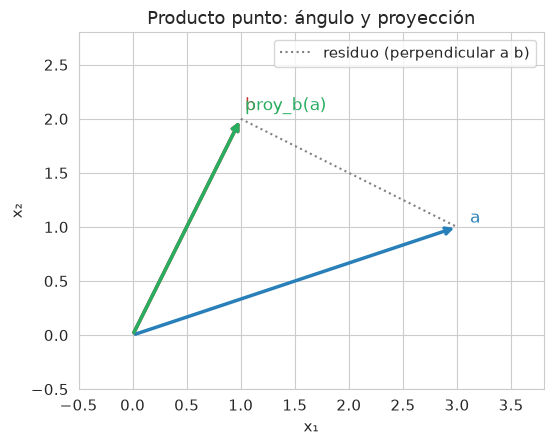

In [4]:
a = np.array([3.0, 1.0])
b = np.array([1.0, 2.0])

dot = a @ b
cos_theta = dot / (np.linalg.norm(a) * np.linalg.norm(b))
angle = np.degrees(np.arccos(cos_theta))
proj = (a @ b) / (b @ b) * b                 # componente de a en la dirección de b
resid = a - proj                              # lo que queda: debe ser perpendicular a b

print(f"a·b = {dot:.2f} | cos θ = {cos_theta:.4f} | ángulo = {angle:.1f}°")
print(f"proyección de a sobre b = {proj} | residuo = {resid}")
print(f"¿residuo ⟂ b?  resid·b = {resid @ b:.2e}  (≈ 0)")

fig, ax = plt.subplots(figsize=(6, 5))
for v, c, lab in [(a, "#2980b9", "a"), (b, "#c0392b", "b"), (proj, "#27ae60", "proy_b(a)")]:
    ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
    ax.text(*(v * 1.04), lab, color=c, fontsize=12)
ax.plot([proj[0], a[0]], [proj[1], a[1]], ":", color="gray", label="residuo (perpendicular a b)")
ax.set(xlim=(-0.5, 3.8), ylim=(-0.5, 2.8), title="Producto punto: ángulo y proyección", xlabel="x₁", ylabel="x₂")
ax.set_aspect("equal"); ax.grid(True); ax.legend(); plt.show()

**Qué deberías ver:** `a` (azul), `b` (rojo) y la sombra de `a` sobre la recta de `b` (verde); el segmento punteado une la punta de `a` con su proyección formando un **ángulo recto** con `b`. Numéricamente, `resid·b` debe ser 0 (o, en general, del orden de $10^{-16}$: el redondeo impide garantizar un cero exacto).

### Normas: distintas formas de medir "tamaño"
Una **norma** mide la longitud de un vector. Las tres que más usarás:

| Norma | Fórmula | Dónde aparece |
|---|---|---|
| $\ell_2$ (euclídea) | $\sqrt{\sum x_i^2}$ | distancias, MSE, regularización Ridge |
| $\ell_1$ (Manhattan) | $\sum\lvert x_i\rvert$ | Lasso (promueve ceros → *sparsity*), distancia en una grilla (NB-04) |
| $\ell_\infty$ | $\max\lvert x_i\rvert$ | error en el peor caso, distancia de Chebyshev |

Para *ver* cómo cambian, dibujamos el conjunto de vectores con norma 1 ("bola unidad") en cada caso:

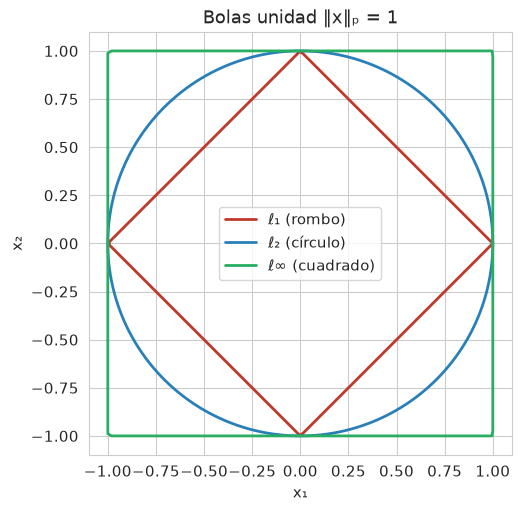

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
angles = np.linspace(0, 2 * np.pi, 400)
dirs = np.vstack([np.cos(angles), np.sin(angles)])          # direcciones; las reescalamos para que cada una tenga norma 1
for p, lab, c in [(1, "ℓ₁ (rombo)", "#c0392b"), (2, "ℓ₂ (círculo)", "#2980b9"), (np.inf, "ℓ∞ (cuadrado)", "#27ae60")]:
    unit = dirs / np.linalg.norm(dirs, ord=p, axis=0)
    ax.plot(*unit, label=lab, color=c, lw=2)
ax.set(title="Bolas unidad ‖x‖ₚ = 1", xlabel="x₁", ylabel="x₂"); ax.set_aspect("equal"); ax.grid(True); ax.legend()
plt.show()

**Qué deberías ver:** un rombo, un círculo y un cuadrado anidados. La esquina del rombo sobre los ejes es la razón geométrica por la que **Lasso** ($\ell_1$) produce coeficientes exactamente cero: al intersectar la región de error con el rombo, es muy probable tocar una esquina (NB-11).

### Similitud coseno
Cuando importa la **dirección** y no la magnitud (documentos de distinto largo, embeddings), se usa $\cos\theta=\frac{\mathbf a\cdot\mathbf b}{\|\mathbf a\|\|\mathbf b\|}$. Es 1 si apuntan igual, 0 si son perpendiculares, −1 si son opuestos.

In [6]:
def cosine_similarity_matrix(X):
    Xn = X / np.linalg.norm(X, axis=1, keepdims=True)      # normalizar filas: así el producto punto ES el coseno
    return Xn @ Xn.T

# Conteo de palabras ["red", "neurona", "señal", "base_de_datos"] para 4 "documentos"
docs = np.array([[5, 4, 0, 0],      # redes neuronales
                 [10, 8, 0, 0],     # lo mismo, pero el doble de largo
                 [3, 0, 6, 0],      # redes de comunicaciones
                 [0, 0, 0, 7]], dtype=float)   # bases de datos
S = cosine_similarity_matrix(docs)
print(S.round(2))
print("\nOjo: docs 0 y 1 tienen distancia euclídea", round(np.linalg.norm(docs[0] - docs[1]), 2), "pero similitud coseno", S[0, 1].round(2))

[[1.   1.   0.35 0.  ]
 [1.   1.   0.35 0.  ]
 [0.35 0.35 1.   0.  ]
 [0.   0.   0.   1.  ]]

Ojo: docs 0 y 1 tienen distancia euclídea 6.4 pero similitud coseno 1.0


**Qué deberías ver:** una matriz simétrica con unos en la diagonal. Los documentos 0 y 1 tienen coseno **exactamente 1** (misma dirección) aunque su distancia euclídea sea grande: el coseno ignora el largo. Esa es la razón de que los *embeddings* de texto se comparen con coseno.

### 🔧 Pruébalo tú mismo

**3-1. Ángulo recto:** encuentra un vector `c` no nulo que sea perpendicular a `a = [3, 1]` y verifica `a @ c == 0`. ¿Cuántos vectores unitarios lo cumplen? (Pista: en 2D, intercambia componentes y cambia un signo.)

**3-2. Proyección sobre un plano:** proyecta `v = [1, 2, 3]` sobre el plano generado por `e1 = [1,0,0]` y `e2 = [0,1,0]` (suma de proyecciones, porque son ortogonales). ¿Qué obtienes y por qué?

**3-3. Normas:** calcula `np.linalg.norm(x, ord=p)` de `x = [3, -4, 0]` para `p = 1, 2, np.inf`. ¿Cuál es la mayor? ¿Siempre se cumple $\|x\|_\infty \le \|x\|_2 \le \|x\|_1$?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 3-1, 3-2 y 3-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [7]:
c = np.array([-a[1], a[0]])                                    # 3-1: rotar 90° → [-1, 3]
print("c =", c, "| a·c =", a @ c, "| hay exactamente 2 unitarios: ±c/‖c‖")
v3 = np.array([1.0, 2.0, 3.0]); e1, e2 = np.eye(3)[0], np.eye(3)[1]
p3 = (v3 @ e1) / (e1 @ e1) * e1 + (v3 @ e2) / (e2 @ e2) * e2     # 3-2: se obtiene [1, 2, 0]: "borra" la 3.ª coordenada
print("proyección sobre el plano xy:", p3)
x3 = np.array([3.0, -4.0, 0.0])                                 # 3-3
print({p: np.linalg.norm(x3, ord=p) for p in (1, 2, np.inf)}, "→ ℓ1 ≥ ℓ2 ≥ ℓ∞ siempre")

c = [-1.  3.] | a·c = 0.0 | hay exactamente 2 unitarios: ±c/‖c‖
proyección sobre el plano xy: [1. 2. 0.]
{1: np.float64(7.0), 2: np.float64(5.0), inf: np.float64(4.0)} → ℓ1 ≥ ℓ2 ≥ ℓ∞ siempre


### 3.2 Matrices como transformaciones
**Por qué:** si "una matriz es una función", ¿qué función es? Aplicada a un vector $\mathbf x$, $A\mathbf x$ lo transforma. Las **columnas** de $A$ te dicen adónde van los vectores base: $A\mathbf e_1$ es la 1.ª columna y $A\mathbf e_2$ la 2.ª. Todo lo demás se deduce por linealidad.

Dos números resumen la transformación:
- **Determinante:** el factor por el que cambia el **área** (negativo = hay reflexión; 0 = el espacio colapsa).
- **Rango:** la dimensión de lo que queda (rango 1 en 2D = todo cae sobre una recta; se pierde información de forma irreversible).

Dibujemos seis transformaciones típicas (flechas roja y verde = imágenes de $\mathbf e_1$ y $\mathbf e_2$):

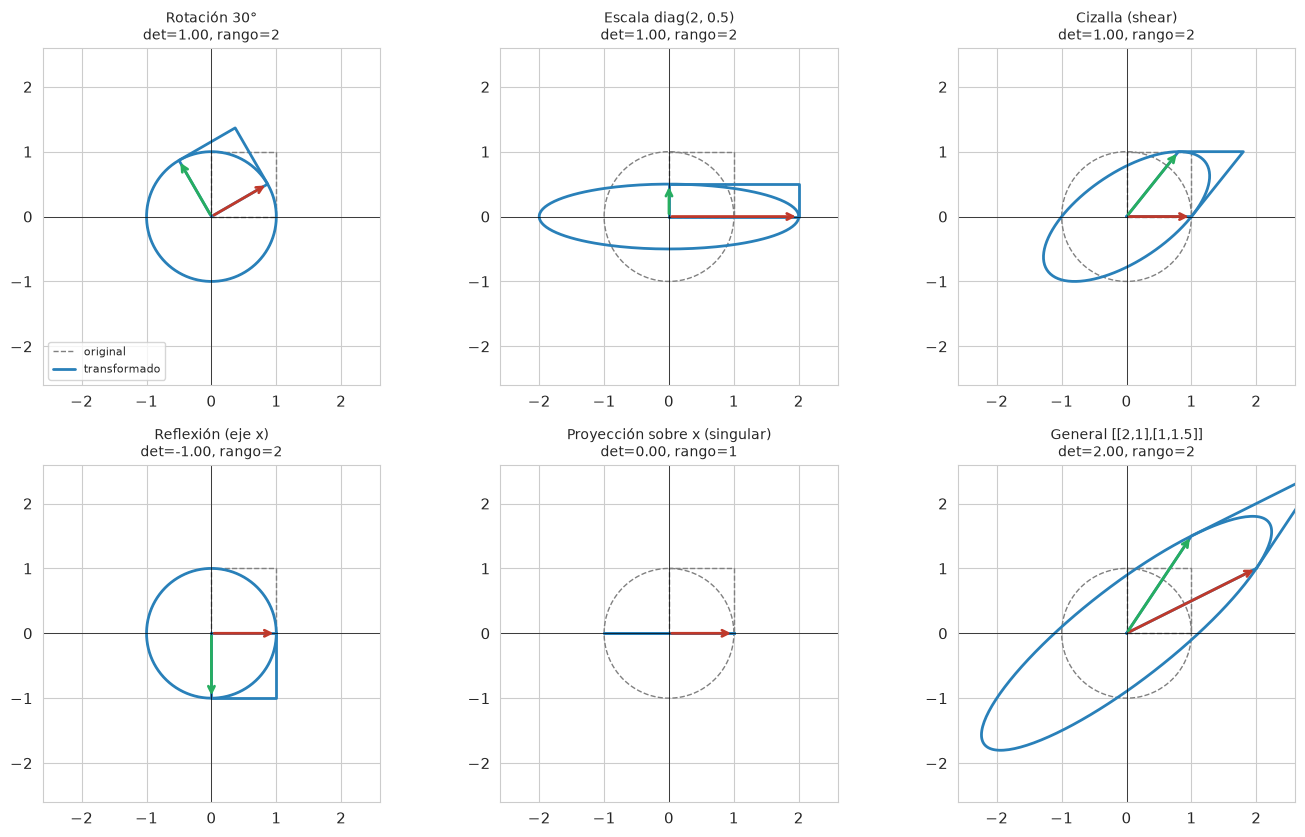

In [8]:
th = np.radians(30)
mats = {
    "Rotación 30°": np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]]),
    "Escala diag(2, 0.5)": np.diag([2.0, 0.5]),
    "Cizalla (shear)": np.array([[1.0, 0.8], [0.0, 1.0]]),
    "Reflexión (eje x)": np.array([[1.0, 0.0], [0.0, -1.0]]),
    "Proyección sobre x (singular)": np.array([[1.0, 0.0], [0.0, 0.0]]),
    "General [[2,1],[1,1.5]]": np.array([[2.0, 1.0], [1.0, 1.5]]),
}
fig, axes = plt.subplots(2, 3, figsize=(14, 8.5))
for ax, (name, A) in zip(axes.ravel(), mats.items()):
    plot_transform(A, ax, name)
    ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6)
axes[0, 0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Qué deberías ver:**
- **Rotación:** el círculo no cambia y $\det=1$ (conserva áreas y ángulos).
- **Escala:** el círculo se vuelve una elipse; $\det=2\cdot 0.5=1$ (área igual, forma distinta).
- **Cizalla:** el cuadrado se inclina; $\det=1$.
- **Reflexión:** el espejo vuelve el $\det=-1$.
- **Proyección:** todo cae sobre una recta; $\det=0$ y **rango 1**: no existe $A^{-1}$ (no puedes recuperar el $x_2$ perdido).
- **General:** una elipse inclinada; sus ejes son justo lo que revelarán los autovalores y la SVD.

> **NOTA:** una matriz es invertible ⇔ $\det\neq0$ ⇔ rango completo ⇔ sus columnas son linealmente independientes. En la práctica "casi singular" ($\det$ minúsculo) es tan malo como singular: lo medimos con el número de condición (sección 3.4).

### 🔧 Pruébalo tú mismo

**3-4. Componer transformaciones:** ¿qué hace `R @ S` (rotar después de escalar) frente a `S @ R`? Dibuja ambas con `plot_transform`. ¿Conmutan las matrices? ¿Y qué determinante tiene el producto?

**3-5. Crear una cizalla distinta:** construye una matriz que mapee `e1 → [1, 0]` y `e2 → [-1, 1]`. Verifica que sus columnas son esas imágenes y que su determinante es 1.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 3-4 y 3-5
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

¿R@S == S@R? False | det(R@S) = 1.0 = det(R)·det(S)


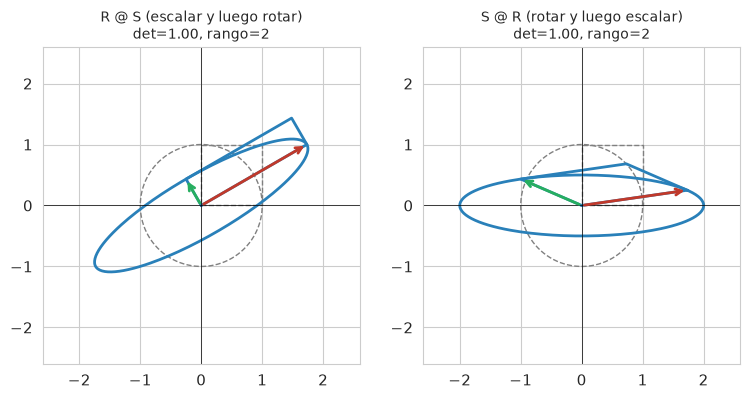

A5 =
 [[ 1 -1]
 [ 0  1]] | det = 1.0


In [9]:
R, S_ = mats["Rotación 30°"], mats["Escala diag(2, 0.5)"]
print("¿R@S == S@R?", np.allclose(R @ S_, S_ @ R), "| det(R@S) =", round(np.linalg.det(R @ S_), 3), "= det(R)·det(S)")
fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
plot_transform(R @ S_, axs[0], "R @ S (escalar y luego rotar)"); plot_transform(S_ @ R, axs[1], "S @ R (rotar y luego escalar)")
for ax in axs: ax.set_xlim(-2.6, 2.6); ax.set_ylim(-2.6, 2.6)
plt.show()                                      # las matrices NO conmutan: el orden de las transformaciones importa
A5 = np.column_stack([[1, 0], [-1, 1]])         # 3-5: las columnas son las imágenes de e1 y e2
print("A5 =\n", A5, "| det =", np.linalg.det(A5))

### 3.3 Ortogonalidad, QR y mínimos cuadrados
**Por qué:** una base **ortonormal** (vectores perpendiculares de norma 1) es la mejor posible: los cálculos son estables y las proyecciones triviales ($Q^\top Q=I$, así que $Q^{-1}=Q^\top$). La **descomposición QR** convierte las columnas de cualquier matriz $A$ en una base ortonormal $Q$, guardando en $R$ (triangular superior) cómo reconstruir $A=QR$. El método clásico es **Gram–Schmidt**: a cada columna le restas sus proyecciones sobre las anteriores y normalizas.

Lo implementamos (versión "modificada", numéricamente más estable) y lo comparamos con `np.linalg.qr`:

In [10]:
def gram_schmidt(A):
    # QR por Gram–Schmidt modificado: resta cada proyección del vector YA actualizado (más estable que el clásico)
    m, n = A.shape
    Q, R = np.zeros((m, n)), np.zeros((n, n))
    for j in range(n):
        v = A[:, j].astype(float).copy()
        for i in range(j):
            R[i, j] = Q[:, i] @ v
            v -= R[i, j] * Q[:, i]
        R[j, j] = np.linalg.norm(v)
        Q[:, j] = v / R[j, j]
    return Q, R

X = rng.normal(size=(6, 3))
Q, R = gram_schmidt(X)
Q_np, R_np = np.linalg.qr(X)

print("A = QR            :", np.allclose(Q @ R, X))
print("QᵀQ = I           :", np.allclose(Q.T @ Q, np.eye(3)))
print("R triangular sup. :", np.allclose(R, np.triu(R)))
print("igual a np.qr (salvo signos):", np.allclose(np.abs(Q), np.abs(Q_np)))

A = QR            : True
QᵀQ = I           : True
R triangular sup. : True
igual a np.qr (salvo signos): True


**Qué deberías ver:** cuatro `True`. Los signos de las columnas de $Q$ pueden diferir de NumPy (la descomposición es única salvo signos), por eso comparamos valores absolutos.

### Mínimos cuadrados = proyección
Cuando $A\mathbf x=\mathbf y$ no tiene solución exacta (más ecuaciones que incógnitas: lo normal en ML), buscamos el $\hat{\mathbf x}$ que minimice $\|A\mathbf x-\mathbf y\|_2$. La geometría lo explica todo: $A\hat{\mathbf x}$ es la **proyección de $\mathbf y$ sobre el espacio generado por las columnas de $A$**, y por eso el **residuo es perpendicular a cada columna**: $A^\top(\mathbf y-A\hat{\mathbf x})=\mathbf 0$ (esa es la *ecuación normal*, $A^\top A\hat{\mathbf x}=A^\top\mathbf y$).

Con QR se resuelve sin formar $A^\top A$: $R\hat{\mathbf x}=Q^\top\mathbf y$.

In [11]:
n = 80
t = rng.uniform(-1, 1, n)
A_ls = np.column_stack([np.ones(n), t, t ** 2])               # modelo: y = c0 + c1 t + c2 t²
coef_true = np.array([1.0, -2.0, 3.0])
y = A_ls @ coef_true + rng.normal(0, 0.3, n)

Q, R = np.linalg.qr(A_ls)
x_qr = sla.solve_triangular(R, Q.T @ y)                      # QR: resolver un sistema triangular (barato y estable)
x_ne = np.linalg.solve(A_ls.T @ A_ls, A_ls.T @ y)            # ecuación normal
x_lstsq = np.linalg.lstsq(A_ls, y, rcond=None)[0]            # lo que usarías en la práctica
residual = y - A_ls @ x_qr

print("QR     :", x_qr, "\nNormal :", x_ne, "\nlstsq  :", x_lstsq, "\nreal   :", coef_true)
print("Residuo ⟂ columnas de A →  ‖Aᵀ r‖ =", f"{np.linalg.norm(A_ls.T @ residual):.2e}")

QR     : [ 0.9772 -1.9889  2.9505] 
Normal : [ 0.9772 -1.9889  2.9505] 
lstsq  : [ 0.9772 -1.9889  2.9505] 
real   : [ 1. -2.  3.]
Residuo ⟂ columnas de A →  ‖Aᵀ r‖ = 4.17e-14


**Qué deberías ver:** los tres métodos coinciden (con coeficientes cercanos a [1, −2, 3]) y la norma $\|A^\top r\|$ es prácticamente cero: la prueba numérica de que el residuo es perpendicular al espacio de las columnas. En este problema bien condicionado todo funciona. Veamos qué pasa cuando **no** lo está.

### 3.4 Número de condición: cuando resolver un sistema "bien" sale mal
El **número de condición** $\kappa(A)=\sigma_{\max}/\sigma_{\min}$ es el factor máximo por el que se amplifica un error relativo en los datos. Con `float64` ($\epsilon\approx10^{-16}$), el error relativo de la solución es del orden de $\kappa\cdot\epsilon$. Probemos con las **matrices de Hilbert**, un clásico patológicamente mal condicionado: resolvemos $H\mathbf x=\mathbf b$ con $\mathbf x$ conocido y medimos el error.

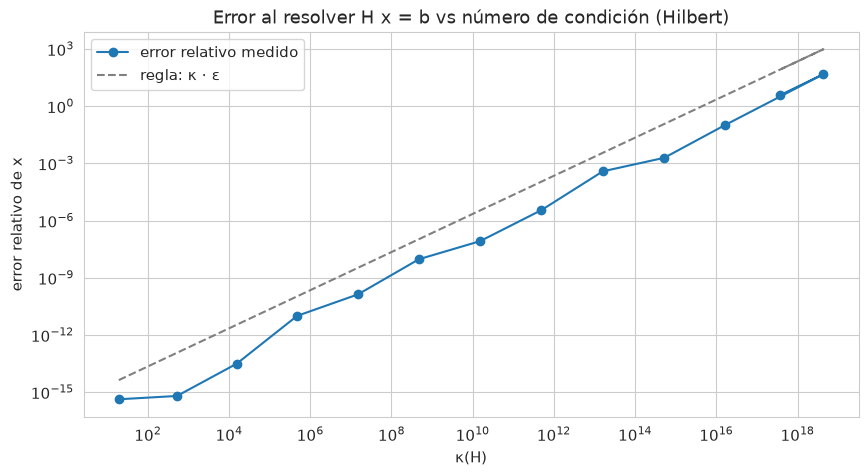

n=14: κ = 3.7e+17 → error relativo ≈ 3.7e+00 (¡casi sin dígitos correctos!)


In [12]:
rows = []
for n_ in range(2, 15):
    H = sla.hilbert(n_)
    x_true = np.ones(n_)
    x_hat = np.linalg.solve(H, H @ x_true)
    rows.append((n_, np.linalg.cond(H), np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)))
cond, err = np.array([r[1] for r in rows]), np.array([r[2] for r in rows])

fig, ax = plt.subplots()
ax.loglog(cond, err, "o-", label="error relativo medido")
ax.loglog(cond, cond * np.finfo(float).eps, "--", color="gray", label="regla: κ · ε")
ax.set(title="Error al resolver H x = b vs número de condición (Hilbert)", xlabel="κ(H)", ylabel="error relativo de x")
ax.grid(True, which="both"); ax.legend(); plt.show()
print(f"n=14: κ = {cond[-1]:.1e} → error relativo ≈ {err[-1]:.1e} (¡casi sin dígitos correctos!)")

**Qué deberías ver:** una nube de puntos que sube junto con la recta $\kappa\cdot\epsilon$: a mayor condicionamiento, mayor error; para $n=14$ el error relativo **supera 1** (¡el error es mayor que la propia solución!), es decir, el resultado es **basura** aunque `solve` no lance ninguna advertencia.

Esto explica por qué la **ecuación normal** es peligrosa: $\kappa(A^\top A)=\kappa(A)^2$. Con un ajuste polinomial de grado alto, $A$ ya viene mal condicionada y $A^\top A$ pierde el *doble* de dígitos.

In [13]:
t = np.linspace(0, 1, 60)
print(f"{'grado':>5} {'κ(A)':>10} {'κ(AᵀA)':>12} {'error coef. normal':>20} {'error coef. lstsq':>19}")
for deg in (3, 6, 9, 12):
    Ad = np.vander(t, deg + 1, increasing=True)
    c_true_p = np.ones(deg + 1)                       # coeficientes CONOCIDOS y datos sin ruido: aislamos el error numérico
    y_exact = Ad @ c_true_p
    c_ne = np.linalg.solve(Ad.T @ Ad, Ad.T @ y_exact)
    c_ls = np.linalg.lstsq(Ad, y_exact, rcond=None)[0]
    rel_c = lambda c: np.linalg.norm(c - c_true_p) / np.linalg.norm(c_true_p)
    print(f"{deg:>5} {np.linalg.cond(Ad):>10.1e} {np.linalg.cond(Ad.T @ Ad):>12.1e} {rel_c(c_ne):>20.1e} {rel_c(c_ls):>19.1e}")

grado       κ(A)       κ(AᵀA)   error coef. normal   error coef. lstsq
    3    1.2e+02      1.4e+04              7.2e-13             1.5e-15
    6    2.0e+04      4.0e+08              4.4e-09             1.0e-12
    9    3.6e+06      1.3e+13              1.7e-04             1.6e-10
   12    6.8e+08      1.0e+18              7.7e+00             3.0e-09


**Qué deberías ver:** $\kappa(A^\top A)$ es aproximadamente el **cuadrado** de $\kappa(A)$, y el error en los **coeficientes** de la ecuación normal es varios órdenes de magnitud mayor que el de `lstsq` (que usa SVD) cuando el grado crece. Un detalle sutil: el *residuo* de ambos métodos puede ser casi igual (el ajuste "se ve bien"), pero los **coeficientes** difieren: una solución mal condicionada puede reproducir los datos y aun así tener parámetros sin sentido. **Conclusión práctica:** usa siempre `np.linalg.lstsq` o `scipy.linalg.lstsq` en lugar de `solve(AᵀA, Aᵀy)`; y recuerda que normalizar las features (NB-09) mejora el condicionamiento.

### ⚠️ Troubleshooting

**Error:** `numpy.linalg.LinAlgError: Singular matrix`
**Por qué:** `np.linalg.solve`/`inv` recibió una matriz de rango deficiente (columnas redundantes, por ejemplo dos features perfectamente correlacionadas).
**Solución:** elimina la redundancia, o usa `lstsq`/`pinv` (que dan la solución de mínima norma) o regulariza (Ridge, sección 5.3).

**Síntoma:** resultados "raros" **sin** error ni warning.
**Por qué:** matriz mal condicionada (ver arriba): NumPy no te avisa.
**Solución:** revisa `np.linalg.cond(A)` antes de confiar en una solución; si $\kappa>10^{8}$ desconfía.

### 🔧 Pruébalo tú mismo

**3-6. Predice la pérdida de dígitos:** para `H = sla.hilbert(8)` calcula $\log_{10}\kappa$ y compáralo con el número de dígitos correctos que obtienes en `solve(H, H @ ones)` (usa `-np.log10(error)`).

**3-7. Normalizar ayuda:** con `Ad = np.vander(t, 10, increasing=True)`, calcula `cond` antes y después de **escalar cada columna a norma 1**. ¿Cuánto mejora? ¿Por qué mejora tan poco aquí, y en qué caso ayudaría mucho más?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 3-6 y 3-7
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [14]:
H8 = sla.hilbert(8); e8 = np.linalg.norm(np.linalg.solve(H8, H8 @ np.ones(8)) - np.ones(8)) / np.sqrt(8)
print(f"log10 κ = {np.log10(np.linalg.cond(H8)):.1f} → dígitos perdidos ≈ 16 - {-np.log10(e8):.1f} = {16 + np.log10(e8):.1f}")   # 3-6
Ad = np.vander(t, 10, increasing=True)
Ad_n = Ad / np.linalg.norm(Ad, axis=0)                      # 3-7: columnas de norma 1 (equilibrado)
print(f"κ antes = {np.linalg.cond(Ad):.1e} | κ después = {np.linalg.cond(Ad_n):.1e}")
print("Mejora poco: las columnas ya tienen escalas parecidas; el mal condicionamiento viene de la COLINEALIDAD (t⁹ ≈ t¹⁰), no de la escala.")
print("Escalar ayuda mucho cuando las columnas tienen magnitudes muy distintas (ver 7-2); para colinealidad hace falta otra base (Legendre) o regularizar.")

log10 κ = 10.2 → dígitos perdidos ≈ 16 - 7.1 = 8.9
κ antes = 3.6e+06 | κ después = 2.3e+06
Mejora poco: las columnas ya tienen escalas parecidas; el mal condicionamiento viene de la COLINEALIDAD (t⁹ ≈ t¹⁰), no de la escala.
Escalar ayuda mucho cuando las columnas tienen magnitudes muy distintas (ver 7-2); para colinealidad hace falta otra base (Legendre) o regularizar.


### 📊 Resumen visual — vectores y matrices
```
 CONCEPTO              GEOMETRÍA                              CÓDIGO                         CUIDADO CON…
 ──────────────────────────────────────────────────────────────────────────────────────────────────────
 a·b                   proyección y ángulo                    a @ b                          dimensiones (1D vs 2D)
 ‖x‖₂ / ‖x‖₁ / ‖x‖∞    esfera / rombo / cuadrado              np.linalg.norm(x, ord=p)       ℓ1 → esquinas → sparsity
 A como función        columnas = imágenes de la base          A @ x                          el orden importa (A@B ≠ B@A)
 det(A), rango(A)      factor de área, dimensión que sobrevive np.linalg.det/matrix_rank     det≈0 ⇒ casi singular
 QR                    base ortonormal Q + triangular R        np.linalg.qr                   signos libres
 Mínimos cuadrados     proyectar y sobre col(A)                np.linalg.lstsq                NO usar solve(AᵀA, Aᵀy)
 κ(A)                  amplificación del error                 np.linalg.cond                 pierdes log10(κ) dígitos
```

## 4. Autovalores y autovectores

### 4.1 La intuición geométrica
Cuando aplicas $A$ a un vector cualquiera, normalmente cambia de **dirección**. Pero casi siempre existen unas pocas direcciones especiales que **no se desvían**: solo se estiran o encogen. Esas son los **autovectores**, y el factor de estiramiento es el **autovalor**:
$$A\mathbf v=\lambda\mathbf v$$

> **Analogía:** imagina que estiras una hoja de goma sujetándola de dos lados opuestos. La mayoría de los puntos se desplazan en diagonal, pero los que estaban sobre la línea de estiramiento solo se alejan o se acercan a lo largo de esa línea. Esa línea es un autovector.

El resultado más importante para ML: si $A$ es **simétrica** (como una matriz de covarianza o $A^\top A$), sus autovectores son **perpendiculares** entre sí y la transformación es exactamente "estirar a lo largo de ejes perpendiculares" (**teorema espectral**: $A=Q\Lambda Q^\top$). Lo comprobamos dibujando cómo $A$ convierte el círculo en una elipse cuyos ejes son los autovectores:

autovalores λ : [1.382 3.618]
autovectores (columnas):
 [[ 0.5257 -0.8507]
 [-0.8507 -0.5257]]
¿A v = λ v ?    True
¿V ortonormal?  True | ¿A = V Λ Vᵀ?  True


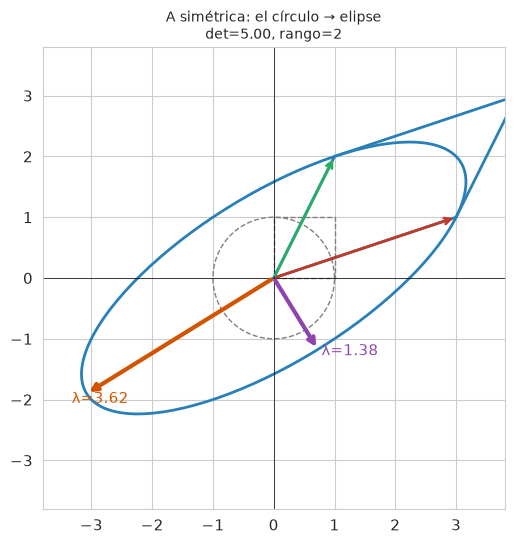

In [15]:
A_sym = np.array([[3.0, 1.0], [1.0, 2.0]])
lam, V = np.linalg.eigh(A_sym)             # eigh: para simétricas (más rápida, autovalores reales, V ortonormal)
print("autovalores λ :", lam)
print("autovectores (columnas):\n", V)
print("¿A v = λ v ?   ", all(np.allclose(A_sym @ V[:, i], lam[i] * V[:, i]) for i in range(2)))
print("¿V ortonormal? ", np.allclose(V.T @ V, np.eye(2)), "| ¿A = V Λ Vᵀ? ", np.allclose(V @ np.diag(lam) @ V.T, A_sym))

fig, ax = plt.subplots(figsize=(6, 6))
plot_transform(A_sym, ax, "A simétrica: el círculo → elipse")
for i, c in enumerate(["#8e44ad", "#d35400"]):
    ax.annotate("", xy=lam[i] * V[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=3))
    ax.text(*(lam[i] * V[:, i] * 1.08), f"λ={lam[i]:.2f}", color=c, fontsize=11)
ax.set_xlim(-3.8, 3.8); ax.set_ylim(-3.8, 3.8); plt.show()

**Qué deberías ver:** el círculo gris se convierte en una elipse azul **inclinada**; las flechas morada y naranja (autovectores escalados por su $\lambda$) caen **exactamente sobre los ejes de la elipse**, con largo igual al semieje correspondiente. Los autovalores son ≈ 1.38 y 3.62.

> **NOTA:** usa `eigh` para matrices simétricas y `eig` para generales. `eig` puede devolver autovalores **complejos** (p. ej. una rotación pura no tiene ninguna dirección que se conserve), y sus autovectores no tienen por qué ser ortogonales. Además `eigh` los entrega **ordenados de menor a mayor**, mientras que la convención de PCA es de mayor a menor.

In [16]:
lam_c, V_c = np.linalg.eig(mats["Rotación 30°"])
print("Autovalores de una rotación (complejos, sin dirección invariante real):", lam_c)
print("|λ| =", np.abs(lam_c), "→ una rotación no estira nada; solo gira.")

Autovalores de una rotación (complejos, sin dirección invariante real): [0.866+0.5j 0.866-0.5j]
|λ| = [1. 1.] → una rotación no estira nada; solo gira.


### 4.2 Covarianza y PCA: los autovectores de los datos
**Por qué:** ¿en qué dirección "se estira" más una nube de datos? La **matriz de covarianza** $\Sigma$ describe cómo covarían las variables, y sus autovectores son los **ejes principales** de la nube; los autovalores son las **varianzas** a lo largo de esos ejes. Esa es la idea central de **PCA** (se desarrolla completa en NB-14).

Generamos una nube correlacionada y calculamos sus ejes:

In [17]:
mu = np.array([2.0, 1.0])
Sigma_true = np.array([[3.0, 2.0], [2.0, 2.0]])
data = rng.multivariate_normal(mu, Sigma_true, size=600)

Xc = data - data.mean(axis=0)                     # centrar: PCA se hace sobre datos con media cero
Sigma = (Xc.T @ Xc) / (len(Xc) - 1)                # covarianza muestral; equivale a np.cov(data.T)
assert np.allclose(Sigma, np.cov(data.T))

lam_s, V_s = np.linalg.eigh(Sigma)
order = np.argsort(lam_s)[::-1]                    # de mayor a menor varianza
lam_s, V_s = lam_s[order], V_s[:, order]
scores = Xc @ V_s                                  # coordenadas de los datos en los ejes principales

print("autovalores de Σ:", lam_s, "| varianza explicada:", (lam_s / lam_s.sum()).round(3))
print("varianza de los datos proyectados:", scores.var(axis=0, ddof=1), "← igual a los autovalores")
print("covarianza entre componentes (≈ 0, decorrelacionadas):", np.cov(scores.T)[0, 1].round(6))

autovalores de Σ: [4.6785 0.44  ] | varianza explicada: [0.914 0.086]
varianza de los datos proyectados: [4.6785 0.44  ] ← igual a los autovalores
covarianza entre componentes (≈ 0, decorrelacionadas): 0.0


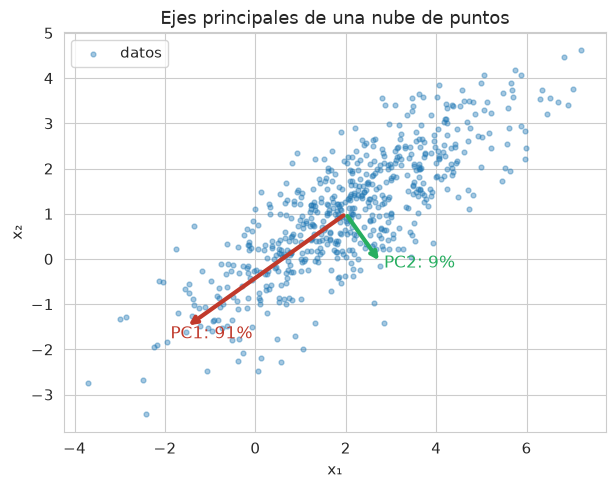

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(*data.T, s=12, alpha=0.4, label="datos")
for i, c in enumerate(["#c0392b", "#27ae60"]):
    v = V_s[:, i] * 2 * np.sqrt(lam_s[i])              # 2 desviaciones estándar a lo largo del eje
    ax.annotate("", xy=mu + v, xytext=mu, arrowprops=dict(arrowstyle="->", color=c, lw=3))
    ax.text(*(mu + v * 1.1), f"PC{i+1}: {lam_s[i] / lam_s.sum():.0%}", color=c, fontsize=12)
ax.set(title="Ejes principales de una nube de puntos", xlabel="x₁", ylabel="x₂"); ax.set_aspect("equal"); ax.grid(True); ax.legend()
plt.show()

**Qué deberías ver:** una nube alargada en diagonal con dos flechas: la roja (PC1) a lo largo del eje mayor, que explica cerca del **90 %** de la varianza, y la verde (PC2) perpendicular. Fíjate en tres verificaciones numéricas: la varianza de los datos proyectados **es** el autovalor, la covarianza entre componentes es ~0 (PCA **decorrelaciona**), y el número de componentes que necesitas depende de cuánta varianza quieres conservar.

### 4.3 Iteración de potencias y PageRank
Para matrices enormes (millones de filas) no se calcula la descomposición completa: se usan métodos iterativos. El más simple es la **iteración de potencias**: multiplicar repetidamente un vector aleatorio por $A$ y normalizar. Cada multiplicación amplifica la componente del autovector dominante, y tras unas iteraciones el vector **converge a él**.

$$\mathbf v_{k+1}=\frac{A\mathbf v_k}{\|A\mathbf v_k\|},\qquad \lambda\approx\mathbf v^\top A\mathbf v\qquad\text{(velocidad: }|\lambda_2/\lambda_1|^k\text{)}$$

In [19]:
def power_iteration(A, iters=500, tol=1e-12, rng=rng):
    v = rng.normal(size=A.shape[0]); v /= np.linalg.norm(v)
    lam_old, hist = 0.0, []
    for k in range(iters):
        w = A @ v
        v = w / np.linalg.norm(w)
        lam = v @ A @ v                       # cociente de Rayleigh: estimación del autovalor
        hist.append(abs(lam - lam_old)); lam_old = lam
        if hist[-1] < tol:
            break
    return lam, v, hist

lam_pi, v_pi, hist = power_iteration(Sigma)
print(f"iteración de potencias: λ = {lam_pi:.6f} en {len(hist)} pasos | eigh: {lam_s[0]:.6f}")
print(f"cociente |λ2/λ1| = {lam_s[1]/lam_s[0]:.3f}  (cuanto más chico, más rápido converge)")
print("¿mismo eje que PC1?", np.allclose(np.abs(v_pi), np.abs(V_s[:, 0])))

iteración de potencias: λ = 4.678461 en 7 pasos | eigh: 4.678461
cociente |λ2/λ1| = 0.094  (cuanto más chico, más rápido converge)
¿mismo eje que PC1? True


**Qué deberías ver:** convergencia en unas pocas iteraciones al mismo autovalor y eje que `eigh`. El ritmo lo fija $|\lambda_2/\lambda_1|$.

**PageRank** (el algoritmo original de Google) es exactamente esto aplicado a la web: la importancia de una página es el **autovector dominante** de la matriz de transición del "navegante aleatorio" (una cadena de Markov, ver NB-01 y NB-08). Con un factor de amortiguación $d=0.85$ (con probabilidad $1-d$ el navegante salta a una página al azar), la matriz es $G=dM+\frac{1-d}{n}\mathbf 1\mathbf 1^\top$.

In [20]:
pages = ["Inicio", "Blog", "Docs", "Precios", "Contacto", "Foro"]
links = {0: [1, 2, 3], 1: [0, 2], 2: [0, 3], 3: [0, 4], 4: [0], 5: [0, 2]}       # a qué páginas enlaza cada una
n_p = len(pages)
M_web = np.zeros((n_p, n_p))
for src, dsts in links.items():
    M_web[dsts, src] = 1 / len(dsts)                     # columna src: probabilidad de ir de src a cada destino
assert np.allclose(M_web.sum(axis=0), 1)                 # columnas suman 1 (estocástica por columnas)

d = 0.85
G = d * M_web + (1 - d) / n_p * np.ones((n_p, n_p))      # el "salto aleatorio" hace G positiva → convergencia garantizada
pr = np.full(n_p, 1 / n_p)
for _ in range(100):
    pr = G @ pr                                          # distribución de probabilidad: ya suma 1, no hace falta normalizar

ev, evec = np.linalg.eig(G); pr_eig = np.real(evec[:, np.argmax(np.real(ev))]); pr_eig /= pr_eig.sum()
print("¿PageRank por potencias == por autovector?", np.allclose(pr, pr_eig))
for name, p_ in sorted(zip(pages, pr), key=lambda z: -z[1]):
    print(f"  {name:9s} {p_:.3f}")

¿PageRank por potencias == por autovector? True
  Inicio    0.349
  Precios   0.203
  Docs      0.187
  Blog      0.124
  Contacto  0.111
  Foro      0.025


**Qué deberías ver:** "Inicio" (a la que casi todas enlazan) con el puntaje más alto, "Foro" (a la que nadie enlaza) con el más bajo. Dos mensajes: (1) el autovalor dominante de una matriz estocástica es 1 y su autovector es la **distribución estacionaria**; (2) un algoritmo de miles de millones de páginas es, en esencia, una iteración de potencias.

### 🔧 Pruébalo tú mismo

**4-1. Mayor varianza:** usa `load_iris().data` (4 features). Calcula la covarianza y sus autovalores con `eigh`. ¿Qué fracción de la varianza explica el primer componente? ¿Cuántos componentes necesitas para el 95 %?

**4-2. Autovalores y traza:** verifica que `suma(autovalores) == traza(Σ)` y que `producto(autovalores) == det(Σ)`. ¿Qué significan ambos en términos de varianza total y volumen?

**4-3. Velocidad de potencias:** construye una matriz simétrica 2×2 con autovalores 10 y 9.9 (usa `Q diag(10, 9.9) Qᵀ`). ¿Cuántas iteraciones necesita `power_iteration`? Compara con autovalores 10 y 1.

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 4-1, 4-2 y 4-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [21]:
Xi = load_iris().data
Si = np.cov(Xi.T); li = np.sort(np.linalg.eigvalsh(Si))[::-1]
print("fracción por componente:", (li / li.sum()).round(4), "| acumulada:", np.cumsum(li / li.sum()).round(4))       # 4-1
print("componentes para 95%:", int(np.searchsorted(np.cumsum(li / li.sum()), 0.95) + 1))
print("traza == suma λ:", np.isclose(np.trace(Si), li.sum()), "| det == prod λ:", np.isclose(np.linalg.det(Si), li.prod()))   # 4-2
Qr = np.linalg.qr(rng.normal(size=(2, 2)))[0]
for pair in [(10, 9.9), (10, 1)]:                                                                                       # 4-3
    A_ = Qr @ np.diag(pair) @ Qr.T
    print(f"autovalores {pair}: {len(power_iteration(A_)[2])} iteraciones")
# traza = varianza total (se conserva al rotar los ejes); det = "volumen" de la nube. Con λ casi iguales la convergencia es lentísima.

fracción por componente: [0.9246 0.0531 0.0171 0.0052] | acumulada: [0.9246 0.9777 0.9948 1.    ]
componentes para 95%: 2
traza == suma λ: True | det == prod λ: True
autovalores (10, 9.9): 500 iteraciones
autovalores (10, 1): 9 iteraciones


### 📊 Resumen visual — autovalores
```
        A v = λ v                      Σ = V Λ Vᵀ  (A simétrica)
   ┌─────────────────┐            ┌──────────────────────────────────────┐
   │ v: dirección que │            │ columnas de V: ejes principales       │
   │ solo se estira   │   ──►      │ λᵢ: varianza a lo largo de cada eje   │  ──► PCA (NB-14)
   │ λ: cuánto        │            │ suma λᵢ = traza  ·  prod λᵢ = det     │
   └─────────────────┘            └──────────────────────────────────────┘
 eigh (simétrica, ordenado ↑, ortonormal) · eig (general, puede ser complejo) · potencias (matrices enormes)
```

## 5. SVD: la descomposición universal

### 5.1 Intuición: "girar, estirar, girar"
Los autovalores solo existen para matrices **cuadradas** (y se portan bien solo para las simétricas). La SVD funciona para **cualquier** matriz $m\times n$:
$$A=U\,\Sigma\,V^\top\qquad U\in\mathbb R^{m\times m},\; V\in\mathbb R^{n\times n}\text{ ortogonales},\;\Sigma\text{ diagonal con }\sigma_1\ge\dots\ge0$$

Lee la transformación de derecha a izquierda: $V^\top$ **gira** el espacio de entrada, $\Sigma$ **estira** cada eje, $U$ **gira** el resultado. Es decir, toda matriz es una elipse que se obtiene estirando un círculo a lo largo de ejes perpendiculares; los $\sigma_i$ son los semiejes. La conexión con autovalores: los $\sigma_i^2$ son los autovalores de $A^\top A$ (y los $V$, sus autovectores).

σ = [3.0425 0.493 ] | κ = σmax/σmin = 6.171292729553324
A = U Σ Vᵀ : True
σ² = autovalores de AᵀA : True


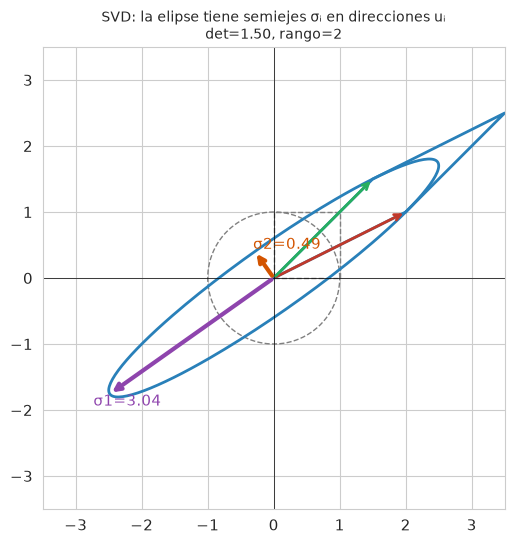

In [22]:
A2 = mats["General [[2,1],[1,1.5]]"] + np.array([[0.0, 0.5], [0.0, 0.0]])      # una matriz NO simétrica
U, s, Vt = np.linalg.svd(A2)
print("σ =", s, "| κ = σmax/σmin =", s[0] / s[-1])
print("A = U Σ Vᵀ :", np.allclose(U @ np.diag(s) @ Vt, A2))
print("σ² = autovalores de AᵀA :", np.allclose(np.sort(s ** 2), np.sort(np.linalg.eigvalsh(A2.T @ A2))))

fig, ax = plt.subplots(figsize=(6, 6))
plot_transform(A2, ax, "SVD: la elipse tiene semiejes σᵢ en direcciones uᵢ")
for i, c in enumerate(["#8e44ad", "#d35400"]):
    ax.annotate("", xy=s[i] * U[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=3))
    ax.text(*(s[i] * U[:, i] * 1.1), f"σ{i+1}={s[i]:.2f}", color=c, fontsize=11)
ax.set_xlim(-3.5, 3.5); ax.set_ylim(-3.5, 3.5); plt.show()

**Qué deberías ver:** una elipse **inclinada** cuyos semiejes (flechas morada y naranja) miden $\sigma_1$ y $\sigma_2$ y apuntan en las direcciones $\mathbf u_1,\mathbf u_2$. Observa: aunque $A$ no es simétrica, la SVD siempre encuentra ejes **perpendiculares** de entrada ($V$) y de salida ($U$). El cociente $\sigma_1/\sigma_2$ es el número de condición: cuanto más aplastada la elipse, peor condicionada la matriz.

### 5.2 Compresión de imágenes con SVD
**Aplicación visual de Eckart–Young:** una imagen en escala de grises es una matriz de $m\times n$. Si conservamos solo los $k$ mayores valores singulares,
$$A_k=\sum_{i=1}^k\sigma_i\,\mathbf u_i\mathbf v_i^\top$$
es la **mejor aproximación posible de rango $k$**, y guardarla cuesta $k(m+n+1)$ números en vez de $mn$.

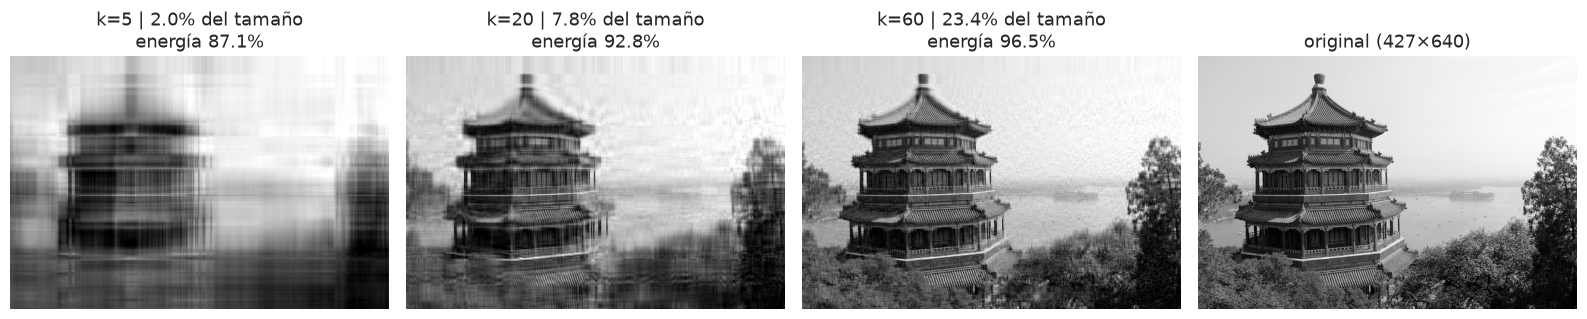

In [23]:
img = load_sample_image("china.jpg").astype(float).mean(axis=2) / 255      # a gris, normalizada a [0,1]
m_, n_ = img.shape
img_mean = img.mean()
# Centramos (como en PCA): el brillo medio aporta casi toda la "energía" pero no es estructura que valga la pena comprimir
U_i, s_i, Vt_i = np.linalg.svd(img - img_mean, full_matrices=False)

def rank_k(k):
    return (U_i[:, :k] * s_i[:k]) @ Vt_i[:k] + img_mean          # U_k Σ_k V_kᵀ (+ la media), sin construir Σ completa

energy = np.cumsum(s_i ** 2) / np.sum(s_i ** 2)                   # fracción de "energía" (norma de Frobenius²) acumulada
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, k in zip(axes, [5, 20, 60]):
    ax.imshow(rank_k(k), cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(f"k={k} | {k*(m_+n_+1)/(m_*n_):.1%} del tamaño\nenergía {energy[k-1]:.1%}")
axes[3].imshow(img, cmap="gray", vmin=0, vmax=1); axes[3].axis("off"); axes[3].set_title(f"original ({m_}×{n_})")
plt.tight_layout(); plt.show()

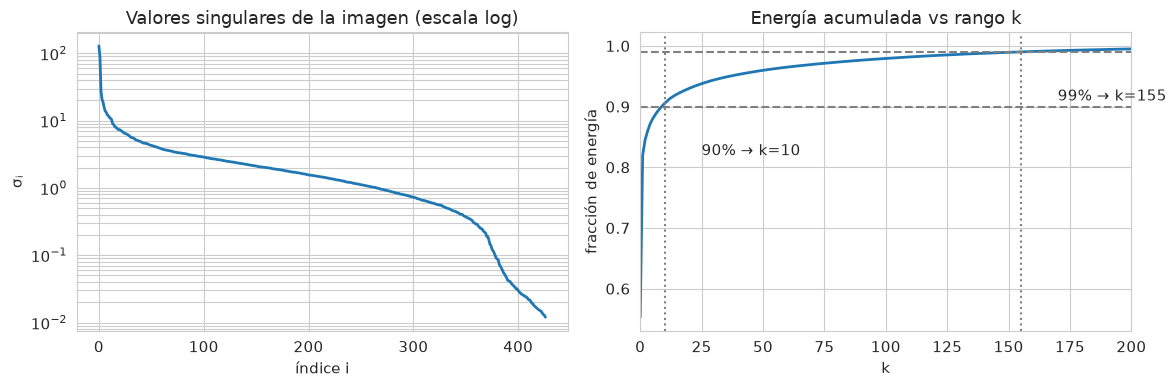

error relativo (Frobenius): {5: '18.25%', 20: '13.61%', 60: '9.56%'}


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(s_i, lw=2); axes[0].set(title="Valores singulares de la imagen (escala log)", xlabel="índice i", ylabel="σᵢ")
axes[1].plot(energy, lw=2)
for q in (0.9, 0.99):
    k_q = int(np.searchsorted(energy, q) + 1)
    axes[1].axhline(q, ls="--", color="gray"); axes[1].axvline(k_q, ls=":", color="gray")
    axes[1].annotate(f"{q:.0%} → k={k_q}", xy=(k_q, q), xytext=(k_q + 15, q - 0.08))
axes[1].set(title="Energía acumulada vs rango k", xlabel="k", ylabel="fracción de energía", xlim=(0, 200))
for ax in axes: ax.grid(True, which="both")
plt.tight_layout(); plt.show()
err_k = {k: np.linalg.norm(img - rank_k(k)) / np.linalg.norm(img) for k in (5, 20, 60)}
print("error relativo (Frobenius):", {k: f"{v:.2%}" for k, v in err_k.items()})

**Qué deberías ver:** con $k=5$ solo se intuyen manchas grandes; con $k=20$ la escena ya es reconocible; con $k=60$ la imagen es muy fiel aunque con una textura de "grano" en las zonas lisas (cielo, agua), y aun así ya ocupa ~23 % del tamaño original: la compresión es real pero modesta. Los valores singulares **decaen rápido** (el eje está en escala log): unos pocos componentes concentran la mayor parte de la energía (cerca del 87 % con solo $k=5$, tras quitar el brillo medio). Esa es la razón de fondo por la que funciona PCA, la compresión y los sistemas de recomendación (matrices usuario–ítem de bajo rango).

> **NOTA (honestidad):** SVD *no* es cómo se comprimen las imágenes en la práctica (JPEG usa DCT por bloques, mucho más eficiente). Aquí es una ilustración de la **aproximación de bajo rango**, que sí es central en ML.

### 5.3 Pseudoinversa y regularización
Para una matriz mal condicionada, los $\sigma_i$ muy pequeños **amplifican el ruido**: la solución de mínimos cuadrados es $\hat{\mathbf x}=\sum_i\frac{\mathbf u_i^\top\mathbf b}{\sigma_i}\mathbf v_i$, y dividir por un $\sigma_i\approx10^{-12}$ dispara cualquier error de $\mathbf b$. Dos remedios, ambos naturales con SVD:

- **SVD truncada:** descartar los $\sigma_i$ pequeños.
- **Ridge (Tikhonov):** cambiar $1/\sigma_i$ por $\sigma_i/(\sigma_i^2+\lambda)$: los $\sigma$ grandes casi no cambian, los pequeños se **suprimen suavemente**. Es exactamente la regresión Ridge (NB-11).

In [25]:
n_h = 12
H = sla.hilbert(n_h)
x_true = np.ones(n_h)
b_clean = H @ x_true
b_noisy = b_clean + rng.normal(0, 1e-8, n_h)             # ruido minúsculo en las mediciones

U_h, s_h, Vt_h = np.linalg.svd(H)
def solve_filtered(filter_fn):
    return Vt_h.T @ (filter_fn(s_h) * (U_h.T @ b_noisy))

x_ls = solve_filtered(lambda s: 1 / s)                                      # mínimos cuadrados "ingenuos"
x_trunc = solve_filtered(lambda s: np.where(s > 1e-6, 1 / s, 0.0))          # SVD truncada
lam_r = 1e-8
x_ridge = solve_filtered(lambda s: s / (s ** 2 + lam_r))                    # Ridge

rel = lambda x: np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
print(f"κ(H) = {s_h[0]/s_h[-1]:.1e} | ruido relativo en b = {np.linalg.norm(b_noisy-b_clean)/np.linalg.norm(b_clean):.1e}")
print(f"error  mínimos cuadrados: {rel(x_ls):.2e}\nerror  SVD truncada     : {rel(x_trunc):.2e}\nerror  Ridge (λ=1e-8)    : {rel(x_ridge):.2e}")
print("¿pinv coincide con la solución filtrada 1/σ?", np.allclose(np.linalg.pinv(H, rcond=0) @ b_noisy, x_ls, atol=1e-3 * np.abs(x_ls).max()))

κ(H) = 1.7e+16 | ruido relativo en b = 7.2e-09
error  mínimos cuadrados: 6.54e+07
error  SVD truncada     : 6.80e-04
error  Ridge (λ=1e-8)    : 4.06e-03
¿pinv coincide con la solución filtrada 1/σ? True


**Qué deberías ver:** un ruido relativo de ~$10^{-8}$ en $\mathbf b$ produce un error **enorme** (órdenes de magnitud mayor) en la solución ingenua, mientras que la SVD truncada y Ridge lo reducen a niveles razonables. Es el **compromiso sesgo–varianza** en estado puro: descartar información (introducir sesgo) a cambio de estabilidad (menor varianza). Lo retomas en NB-11.

### 🔧 Pruébalo tú mismo

**5-1. Eckart–Young numérico:** verifica que el error de la mejor aproximación de rango $k$ en norma de Frobenius es $\sqrt{\sum_{i>k}\sigma_i^2}$ (usa los `s_i` de la imagen para $k=20$).

**5-2. Elegir k por energía:** escribe `choose_k(s, q)` que devuelva el menor $k$ con energía acumulada ≥ q. Calcula cuánto ahorro de almacenamiento da `q=0.95` en la imagen.

**5-3. Barrido de λ:** grafica el error de Ridge en la sección 5.3 para `λ ∈ [1e-16, 1e-2]` (escala log). ¿Existe un valor óptimo? ¿Qué pasa con λ muy grande o muy pequeño?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 5-1, 5-2 y 5-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

error medido 46.5542 vs teoría 46.5542
k(95%) = 38 → almacenamiento 14.9% del original


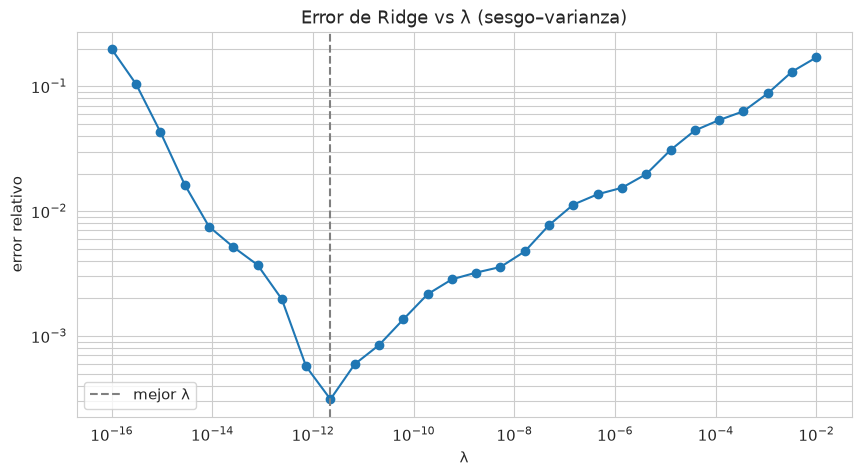

λ muy pequeño → se amplifica el ruido (varianza alta); λ muy grande → solución sesgada hacia 0. El óptimo está en el medio.


In [26]:
k = 20
print(f"error medido {np.linalg.norm(img - rank_k(k)):.4f} vs teoría {np.sqrt(np.sum(s_i[k:] ** 2)):.4f}")               # 5-1
def choose_k(s, q):
    return int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), q) + 1)
k95 = choose_k(s_i, 0.95); print(f"k(95%) = {k95} → almacenamiento {k95*(m_+n_+1)/(m_*n_):.1%} del original")            # 5-2
lams = np.logspace(-16, -2, 30)
errs = [rel(solve_filtered(lambda s, l=l: s / (s ** 2 + l))) for l in lams]                                            # 5-3
fig, ax = plt.subplots(); ax.loglog(lams, errs, "o-"); ax.axvline(lams[int(np.argmin(errs))], ls="--", color="gray", label="mejor λ")
ax.set(title="Error de Ridge vs λ (sesgo–varianza)", xlabel="λ", ylabel="error relativo"); ax.grid(True, which="both"); ax.legend(); plt.show()
print("λ muy pequeño → se amplifica el ruido (varianza alta); λ muy grande → solución sesgada hacia 0. El óptimo está en el medio.")

### 📊 Resumen visual — SVD
```
   A  =  U     Σ      Vᵀ                 Usos:
  m×n   m×m  m×n    n×n                 ┌───────────────────────────────────────────────┐
        giro estira  giro                 │ rango y condicionamiento:  κ = σ₁/σᵣ          │
                                          │ mejor aprox. rango k:      A_k = Σᵢ≤k σᵢ uᵢ vᵢᵀ │
   σᵢ² = autovalores de AᵀA               │ PCA (sobre datos centrados) · pinv · Ridge     │
   V = autovectores de AᵀA                │ compresión y recomendación (matrices bajo rango)│
                                          └───────────────────────────────────────────────┘
```

## 6. Probabilidad con NumPy

**Por qué:** los datos reales son ruidosos, y los modelos de ML son, en el fondo, modelos probabilísticos. Con NumPy puedes **simular** un proceso aleatorio miles de veces y comparar con la teoría: es la mejor forma de *sentir* un resultado antes de demostrarlo (y una herramienta de verificación para el resto de la carrera). La probabilidad formal (axiomas, redes bayesianas) la verás en NB-08; aquí construimos la caja de herramientas de cómputo.

### 6.1 Muestreo y distribuciones
`rng` (un `Generator`) ofrece las distribuciones más comunes; `scipy.stats` aporta densidades (`pdf`), acumuladas (`cdf`), cuantiles (`ppf`) y ajuste. Comparamos histograma simulado y densidad teórica:

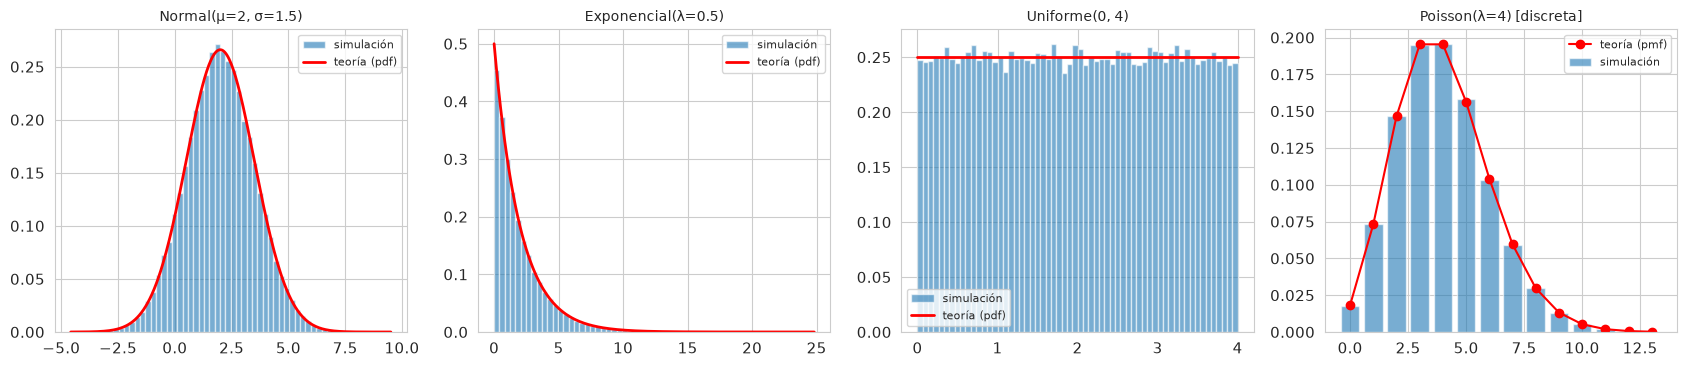

{'Normal(μ=2, σ=1.5)': 'media sim=1.994 | teórica=2.000', 'Exponencial(λ=0.5)': 'media sim=1.990 | teórica=2.000', 'Uniforme(0, 4)': 'media sim=2.000 | teórica=2.000', 'Poisson(λ=4) [discreta]': 'media sim=3.999 | teórica=4.000'}


In [27]:
N = 100_000
samples = {
    "Normal(μ=2, σ=1.5)": (rng.normal(2, 1.5, N), stats.norm(2, 1.5)),
    "Exponencial(λ=0.5)": (rng.exponential(2.0, N), stats.expon(scale=2.0)),         # NumPy usa la escala = 1/λ
    "Uniforme(0, 4)": (rng.uniform(0, 4, N), stats.uniform(0, 4)),
    "Poisson(λ=4) [discreta]": (rng.poisson(4, N), stats.poisson(4)),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (name, (x, dist)) in zip(axes, samples.items()):
    if "Poisson" in name:
        ks = np.arange(0, 14)
        ax.bar(ks, np.bincount(x, minlength=14)[:14] / N, alpha=0.6, label="simulación")
        ax.plot(ks, dist.pmf(ks), "ro-", label="teoría (pmf)")
    else:
        ax.hist(x, bins=60, density=True, alpha=0.6, label="simulación")
        grid = np.linspace(x.min(), x.max(), 300); ax.plot(grid, dist.pdf(grid), "r", lw=2, label="teoría (pdf)")
    ax.set_title(name, fontsize=10); ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print({n: f"media sim={x.mean():.3f} | teórica={d.mean():.3f}" for n, (x, d) in samples.items()})

**Qué deberías ver:** en las cuatro figuras, las barras (simulación) se pegan a la curva roja (teoría). Con $10^5$ muestras el acuerdo es casi perfecto; es la **ley de los grandes números** en acción.

> **NOTA:** `rng.exponential(scale)` recibe la **escala** $=1/\lambda$, no la tasa; confundirlas es un error clásico. Y usa siempre `rng = np.random.default_rng(seed)` en vez de `np.random.seed(...)` global: es el generador moderno, reproducible y recomendado por NumPy.

### 6.2 Ley de los grandes números y Teorema Central del Límite
- **LLN:** el promedio muestral converge al valor esperado al crecer $n$.
- **TCL:** la **suma/promedio** de muchas variables independientes (de casi cualquier distribución con varianza finita) se distribuye aproximadamente **normal**, con desviación $\sigma/\sqrt n$. Por eso la campana aparece en todas partes (el ruido térmico de un receptor es la suma de muchísimos efectos microscópicos, de ahí el ruido **gaussiano** de un canal AWGN).

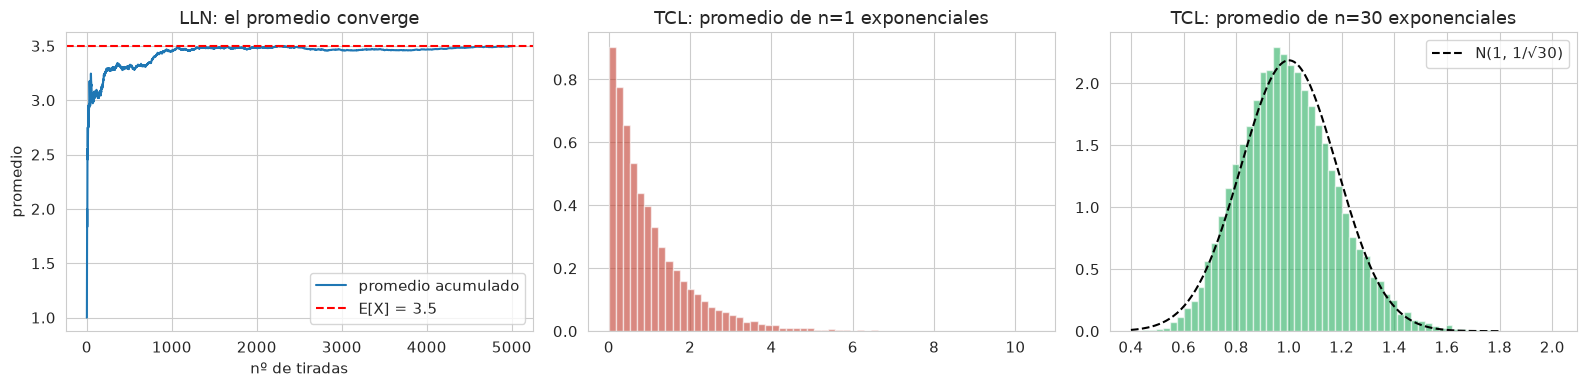

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
# LLN: promedio acumulado de tiradas de un dado (esperanza teórica = 3.5)
rolls = rng.integers(1, 7, 5000)
axes[0].plot(np.cumsum(rolls) / np.arange(1, len(rolls) + 1), lw=1.5, label="promedio acumulado")
axes[0].axhline(3.5, color="r", ls="--", label="E[X] = 3.5")
axes[0].set(title="LLN: el promedio converge", xlabel="nº de tiradas", ylabel="promedio"); axes[0].legend()

# TCL: promedios de n variables EXPONENCIALES (muy asimétricas) → campana
for n_, color in [(1, "#c0392b"), (30, "#27ae60")]:
    means = rng.exponential(1.0, (20_000, n_)).mean(axis=1)
    axes[1 if n_ == 1 else 2].hist(means, bins=60, density=True, color=color, alpha=0.6)
    axes[1 if n_ == 1 else 2].set_title(f"TCL: promedio de n={n_} exponenciales")
grid = np.linspace(0.4, 1.8, 200)
axes[2].plot(grid, stats.norm(1, 1 / np.sqrt(30)).pdf(grid), "k--", label="N(1, 1/√30)"); axes[2].legend()
for ax in axes: ax.grid(True)
plt.tight_layout(); plt.show()

**Qué deberías ver:** (izquierda) el promedio de dados oscila al principio y se estabiliza en 3.5; (centro) con $n=1$ la distribución exponencial es muy asimétrica; (derecha) con $n=30$ el promedio ya es casi una campana, que coincide con la normal teórica de línea negra.

### 6.3 Monte Carlo: estimar con simulación
**Idea:** para calcular algo difícil (una integral, una probabilidad), **simulas** el experimento muchas veces y promedias. El error baja como $1/\sqrt N$ **sin importar la dimensión** (ventaja clave frente a integrar en una grilla). Ejemplo clásico: estimar $\pi$ lanzando puntos al azar en un cuadrado y contando cuántos caen en el círculo inscrito (la fracción es $\pi/4$).

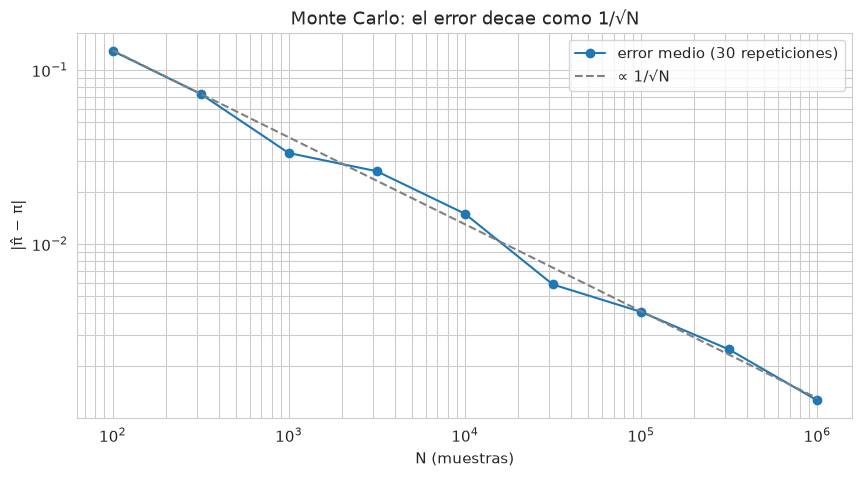

π̂ con N=10⁶: 3.13957  (real: 3.14159)


In [29]:
def estimate_pi(n, rng):
    xy = rng.uniform(-1, 1, size=(n, 2))
    return 4 * np.mean(np.sum(xy ** 2, axis=1) <= 1)       # vectorizado: sin bucles Python

Ns = np.logspace(2, 6, 9).astype(int)
errors = np.array([[abs(estimate_pi(n, rng) - np.pi) for _ in range(30)] for n in Ns])   # 30 repeticiones por tamaño

fig, ax = plt.subplots()
ax.loglog(Ns, errors.mean(axis=1), "o-", label="error medio (30 repeticiones)")
ax.loglog(Ns, 1.3 / np.sqrt(Ns), "--", color="gray", label="∝ 1/√N")
ax.set(title="Monte Carlo: el error decae como 1/√N", xlabel="N (muestras)", ylabel="|π̂ − π|"); ax.grid(True, which="both"); ax.legend()
plt.show()
print(f"π̂ con N=10⁶: {estimate_pi(1_000_000, rng):.5f}  (real: {np.pi:.5f})")

**Qué deberías ver:** una recta de pendiente −1/2 en escala log-log: **para ganar un dígito decimal necesitas 100× más muestras**. Esa lentitud es el precio de Monte Carlo, y por eso se usa cuando no hay alternativa mejor.

#### Aplicación en Comunicaciones Digitales: BER de BPSK sobre AWGN
Un transmisor envía bits mapeados a símbolos $s=\pm\sqrt{E_b}$ (BPSK). El canal suma ruido gaussiano $n\sim\mathcal N(0,N_0/2)$ y el receptor decide por el **signo** de $r=s+n$. La teoría da
$$\text{BER}=Q\!\left(\sqrt{\tfrac{2E_b}{N_0}}\right)=\tfrac12\,\text{erfc}\!\left(\sqrt{\tfrac{E_b}{N_0}}\right)$$
Simulémoslo y comparemos con la fórmula. (Esto es exactamente un experimento de Monte Carlo sobre la ley del ruido gaussiano.)

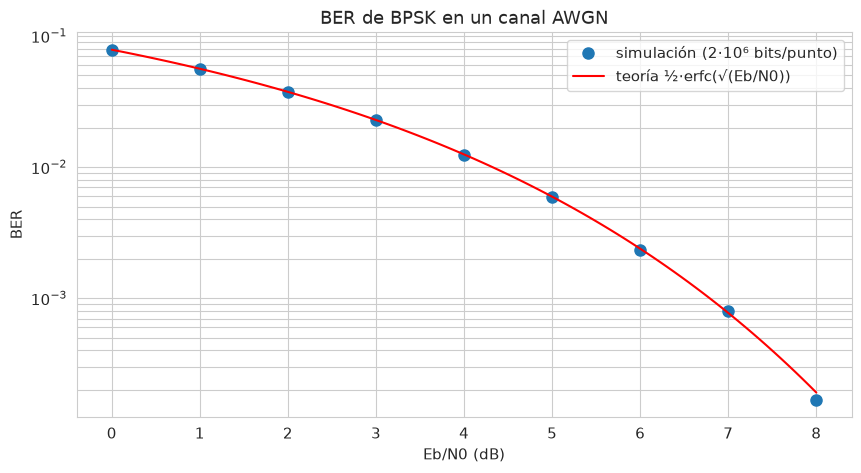

BER sim vs teoría: ['0dB: 7.9e-02/7.9e-02', '4dB: 1.2e-02/1.3e-02', '8dB: 1.7e-04/1.9e-04']


In [30]:
def simulate_bpsk_ber(ebn0_db, n_bits, rng):
    ebn0 = 10 ** (ebn0_db / 10)
    bits = rng.integers(0, 2, n_bits)
    s = 2 * bits - 1.0                                        # símbolos ±1 → Eb = 1
    sigma = np.sqrt(1 / (2 * ebn0))                           # σ² = N0/2 = 1/(2·Eb/N0)
    r = s + sigma * rng.normal(size=n_bits)
    return np.mean((r > 0) != bits.astype(bool))              # decisión por signo; BER = fracción de errores

def theory_ber_bpsk(ebn0_db):
    return 0.5 * special.erfc(np.sqrt(10 ** (np.asarray(ebn0_db) / 10)))

ebn0_grid = np.arange(0, 9)
ber_sim = np.array([simulate_bpsk_ber(e, 2_000_000, rng) for e in ebn0_grid])

fig, ax = plt.subplots()
ax.semilogy(ebn0_grid, ber_sim, "o", ms=8, label="simulación (2·10⁶ bits/punto)")
ax.semilogy(np.linspace(0, 8, 100), theory_ber_bpsk(np.linspace(0, 8, 100)), "r-", label="teoría ½·erfc(√(Eb/N0))")
ax.set(title="BER de BPSK en un canal AWGN", xlabel="Eb/N0 (dB)", ylabel="BER"); ax.grid(True, which="both"); ax.legend()
plt.show()
print("BER sim vs teoría:", [f"{e}dB: {s:.1e}/{theory_ber_bpsk(e):.1e}" for e, s in zip(ebn0_grid[[0, 4, 8]], ber_sim[[0, 4, 8]])])

**Qué deberías ver:** la curva clásica "cascada" (*waterfall*): el BER cae casi **en línea recta en escala log** al subir $E_b/N_0$ (de ~$8\times10^{-2}$ a 0 dB hasta ~$2\times10^{-4}$ a 8 dB), y los puntos simulados caen sobre la curva teórica.

> **NOTA (precisión estadística):** para estimar un BER $p$ con error relativo del ~10 % necesitas observar unos **100 errores**, es decir, $\approx100/p$ bits. Para $p=10^{-6}$ son $10^8$ bits: ahí la simulación directa se vuelve costosa y se usan técnicas de *importance sampling*. Esto es relevante para tu tesis: predecir el BER con ML (a partir del diagrama de ojo) evita simular cientos de millones de bits.

### 6.4 Regla de Bayes: la paradoja del test positivo
AIMA cap. 12–13: $P(H\mid E)=\dfrac{P(E\mid H)\,P(H)}{P(E)}$. Con una enfermedad rara (1 %), un test con sensibilidad 95 % y especificidad 90 %, ¿cuál es la probabilidad de estar enfermo dado un test positivo? La intuición dice "~95 %"… pero Bayes dice otra cosa. Calculémoslo **exacto** y **simulado**:

In [31]:
prev, sens, spec = 0.01, 0.95, 0.90

# Exacto (regla de Bayes con probabilidad total en el denominador)
p_pos = sens * prev + (1 - spec) * (1 - prev)
posterior = sens * prev / p_pos

# Simulación: 2 millones de personas
n_people = 2_000_000
sick = rng.random(n_people) < prev
positive = np.where(sick, rng.random(n_people) < sens, rng.random(n_people) < (1 - spec))
posterior_mc = sick[positive].mean()                        # entre los positivos, ¿qué fracción está enferma?

print(f"P(positivo) = {p_pos:.4f}")
print(f"P(enfermo | positivo)  exacto = {posterior:.4f} | simulado = {posterior_mc:.4f}")
print(f"Falsos positivos por cada verdadero positivo ≈ {(1 - posterior) / posterior:.1f}")

P(positivo) = 0.1085
P(enfermo | positivo)  exacto = 0.0876 | simulado = 0.0877
Falsos positivos por cada verdadero positivo ≈ 10.4


**Qué deberías ver:** `P(enfermo | positivo) ≈ 0.088` (**menos del 9 %**, no 95 %) y la simulación coincide. La razón: hay tantos sanos que los falsos positivos (10 % de 99 %) superan con creces a los verdaderos positivos (95 % de 1 %). Es el mismo fenómeno que hace que, en detección de fraude o intrusos, **la tasa base importa más que la precisión del test** (conecta con precision/recall en NB-10).

### 6.5 Gaussiana multivariada, Cholesky y distancia de Mahalanobis
Para muestrear $\mathbf x\sim\mathcal N(\boldsymbol\mu,\Sigma)$: factoriza $\Sigma=LL^\top$ (**Cholesky**) y calcula $\mathbf x=\boldsymbol\mu+L\mathbf z$ con $\mathbf z\sim\mathcal N(0,I)$. La **distancia de Mahalanobis** $d^2=(\mathbf x-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x-\boldsymbol\mu)$ mide distancia "en desviaciones estándar" **teniendo en cuenta la correlación**: dos puntos a igual distancia euclídea pueden ser uno normal y otro atípico. Bajo normalidad, $d^2\sim\chi^2_p$, lo que da un umbral natural para **detección de anomalías** (NB-15).

In [32]:
mu_m = np.array([0.0, 0.0])
Sigma_m = np.array([[2.0, 1.6], [1.6, 2.0]])               # correlación fuerte (ρ = 0.8)
L = np.linalg.cholesky(Sigma_m)
Z = rng.normal(size=(5000, 2))
Xm = mu_m + Z @ L.T                                          # cada fila: μ + L z
print("covarianza muestral:\n", np.cov(Xm.T), "\n(objetivo Σ):\n", Sigma_m)

def mahalanobis_sq(X, mu, Sigma):
    D = X - mu
    return np.sum(D * np.linalg.solve(Sigma, D.T).T, axis=1)      # solve en vez de inv: más estable

d2 = mahalanobis_sq(Xm, mu_m, Sigma_m)
thr = stats.chi2.ppf(0.99, df=2)
test_pts = np.array([[2.0, 2.0], [2.0, -2.0]])             # ambos a igual distancia euclídea del origen (2.83)
print(f"\nUmbral χ²(2) al 99%: {thr:.2f} | fracción de puntos sobre el umbral: {(d2 > thr).mean():.3f} (≈ 0.01)")
print("d² de [2,2]:", mahalanobis_sq(test_pts, mu_m, Sigma_m).round(2), "← el primero es normal, el segundo es atípico")

covarianza muestral:
 [[1.9979 1.5863]
 [1.5863 1.9626]] 
(objetivo Σ):
 [[2.  1.6]
 [1.6 2. ]]

Umbral χ²(2) al 99%: 9.21 | fracción de puntos sobre el umbral: 0.012 (≈ 0.01)
d² de [2,2]: [ 2.22 20.  ] ← el primero es normal, el segundo es atípico


**Qué deberías ver:** la covarianza muestral ≈ Σ; ≈1 % de los puntos supera el umbral $\chi^2$ (como corresponde); y los dos puntos de prueba, **idénticos en distancia euclídea**, tienen $d^2$ muy distintos: `[2,2]` sigue la dirección de la correlación (normal) y `[2,−2]` va contra ella (atípico).

### 6.6 Entropía, KL y softmax estable
Tres funciones que te acompañarán en todo el ML (y que implementaremos "a mano" una vez para entenderlas):

$$H(p)=-\sum_i p_i\log p_i\quad\text{(incertidumbre)}\qquad D_{KL}(p\|q)=\sum_i p_i\log\frac{p_i}{q_i}\qquad H(p,q)=H(p)+D_{KL}(p\|q)\;\text{(entropía cruzada)}$$

La **entropía cruzada** es la función de pérdida estándar de clasificación (NB-10, NB-16): minimizarla equivale a acercar la distribución predicha $q$ a la real $p$.

In [33]:
def entropy(p):
    p = np.asarray(p, float)
    return -np.sum(special.xlogy(p, p))               # xlogy(0, 0) = 0: evita el NaN de 0·log(0)

def kl_div(p, q):
    p, q = np.asarray(p, float), np.asarray(q, float)
    return np.sum(special.xlogy(p, p / q))

p = np.array([0.7, 0.2, 0.1, 0.0])                    # distribución "verdadera" (con una probabilidad exactamente 0)
q = np.array([0.4, 0.3, 0.2, 0.1])                    # lo que "predice" el modelo
ce = entropy(p) + kl_div(p, q)
print(f"H(p) = {entropy(p):.4f} | KL(p‖q) = {kl_div(p, q):.4f} | H(p,q) = {ce:.4f}")
print(f"Entropía cruzada directa: {-np.sum(special.xlogy(p, q)):.4f} (coincide)")
print(f"KL no es simétrica: KL(p‖q)={kl_div(p, q):.3f} vs KL(q‖p)={kl_div(q, p + 1e-12):.3f}")
print(f"Entropía máxima (uniforme de 4): {entropy(np.full(4, .25)):.4f} = ln 4 = {np.log(4):.4f}")

H(p) = 0.8018 | KL(p‖q) = 0.2413 | H(p,q) = 1.0431
Entropía cruzada directa: 1.0431 (coincide)
KL no es simétrica: KL(p‖q)=0.241 vs KL(q‖p)=2.569
Entropía máxima (uniforme de 4): 1.3863 = ln 4 = 1.3863


**Qué deberías ver:** `H(p,q) = H(p) + KL(p‖q)` (la entropía cruzada siempre es ≥ la entropía; la diferencia es el KL, que nunca es negativo), KL **asimétrica**, y la entropía máxima para la distribución uniforme.

#### Softmax y `logsumexp`: el desborde clásico
La **softmax** convierte logits en probabilidades: $\text{softmax}(z)_i=e^{z_i}/\sum_j e^{z_j}$. Implementada literalmente, **desborda**: `np.exp(1000)` es `inf`, y `inf/inf` es `NaN`. La solución es restar el máximo (no cambia el resultado, porque se cancela en numerador y denominador).

In [34]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

def softmax_stable(z):
    z = z - np.max(z, axis=-1, keepdims=True)         # el máximo pasa a 0 → exp ≤ 1, nunca desborda
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

z = np.array([1000.0, 1001.0, 1002.0])
print("ingenua :", softmax_naive(z))
print("estable :", softmax_stable(z))
print("scipy   :", special.softmax(z))

# Pérdida de entropía cruzada directamente desde logits (como hacen Keras/PyTorch con from_logits=True)
def cross_entropy_from_logits(z, y_idx):
    return special.logsumexp(z) - z[y_idx]            # -log softmax(z)[y] = logsumexp(z) - z[y], sin pasar por probabilidades

print(f"\nCE estable con logits grandes = {cross_entropy_from_logits(z, 2):.4f} (≈ 0.4076)")
print("CE ingenua:", -np.log(softmax_naive(z)[2]))

ingenua : [nan nan nan]
estable : [0.09   0.2447 0.6652]
scipy   : [0.09   0.2447 0.6652]

CE estable con logits grandes = 0.4076 (≈ 0.4076)
CE ingenua: nan


**Qué deberías ver:** la versión ingenua da `[nan nan nan]` (con un `RuntimeWarning` que silenciamos arriba) y la estable da `[0.0900 0.2447 0.6652]`. Es también la razón por la que los *frameworks* ofrecen `from_logits=True`: calcular la pérdida directamente desde los logits con `logsumexp` es más estable que pasar por las probabilidades.

### ⚠️ Troubleshooting

**Síntoma:** `RuntimeWarning: overflow encountered in exp` / `invalid value encountered in divide` y `NaN` en la pérdida.
**Por qué:** `exp` de un número grande desborda; `inf/inf = NaN`. También `log(0) = -inf`.
**Solución:** usa `logsumexp`, `softmax` estable, `np.log1p`/`np.expm1` para valores pequeños y `xlogy` para $0\log0$; recorta probabilidades con `np.clip(p, 1e-12, 1)`.

**Síntoma:** resultados distintos en cada ejecución.
**Por qué:** no fijaste la semilla (o usaste `np.random` y `default_rng` mezclados).
**Solución:** un único `rng = np.random.default_rng(seed)` y pásalo a las funciones que lo necesiten.

### 🔧 Pruébalo tú mismo

**6-1. Dado cargado:** simula 100.000 tiradas de un dado donde el 6 tiene probabilidad 0.25 y el resto reparten el resto por igual (`rng.choice(p=...)`). Compara el promedio con la esperanza teórica.

**6-2. BER más alto:** extiende la simulación BPSK a 9–10 dB con 2·10⁶ bits. ¿Cuántos errores observas? ¿Cuántos bits necesitarías para ver 100 errores a 10 dB?

**6-3. Cambiar la prevalencia:** repite el cálculo de Bayes con prevalencia 10 % y luego 50 %. ¿Cómo cambia el posterior? ¿Qué te dice sobre usar un test de screening en poblaciones de bajo riesgo?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 6-1, 6-2 y 6-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [35]:
pm = np.array([0.15, 0.15, 0.15, 0.15, 0.15, 0.25])                              # 6-1
rolls_c = rng.choice(np.arange(1, 7), size=100_000, p=pm)
print(f"promedio = {rolls_c.mean():.3f} | E[X] = {np.sum(np.arange(1, 7) * pm):.3f}")
for e in (9, 10):                                                                  # 6-2
    b_ = simulate_bpsk_ber(e, 2_000_000, rng); print(f"{e} dB: BER sim = {b_:.1e} ({int(round(b_ * 2_000_000))} errores) | teoría {theory_ber_bpsk(e):.1e}")
print(f"bits para ~100 errores a 10 dB ≈ {100 / theory_ber_bpsk(10):.1e}")
for pv in (0.10, 0.50):                                                            # 6-3
    pp = sens * pv + (1 - spec) * (1 - pv); print(f"prevalencia {pv:.0%}: P(enfermo|+) = {sens * pv / pp:.3f}")
# Con prevalencia baja casi todos los positivos son falsos; con 50% el test sí es muy informativo.

promedio = 3.745 | E[X] = 3.750
9 dB: BER sim = 3.0e-05 (61 errores) | teoría 3.4e-05
10 dB: BER sim = 5.5e-06 (11 errores) | teoría 3.9e-06
bits para ~100 errores a 10 dB ≈ 2.6e+07
prevalencia 10%: P(enfermo|+) = 0.514
prevalencia 50%: P(enfermo|+) = 0.905


### 📊 Resumen visual — probabilidad en NumPy
```
 HERRAMIENTA                  PARA QUÉ                                   RECUERDA
 ──────────────────────────────────────────────────────────────────────────────────────────────
 rng = default_rng(seed)      muestreo reproducible                       exponential(scale=1/λ)
 scipy.stats.dist             pdf / cdf / ppf / fit                       frozen: stats.norm(mu, s)
 LLN / TCL                    promedios → valor esperado / campana         error ∝ σ/√n
 Monte Carlo                  estimar integrales y probabilidades          error ∝ 1/√N (100× muestras = +1 dígito)
 BER BPSK                     ½·erfc(√(Eb/N0))                             ~100 errores para 10% de error relativo
 Bayes                        posterior = verosimilitud·prior / evidencia  ¡la tasa base manda!
 Cholesky + Mahalanobis       muestrear gaussianas y detectar atípicos     d² ~ χ²(p) bajo normalidad
 H, KL, entropía cruzada      incertidumbre y pérdida de clasificación     xlogy y logsumexp evitan NaN
```

## 7. Optimización numérica

### 7.1 Descenso de gradiente y el número de condición
**La intuición (la persona con los ojos vendados):** imagina que estás en una montaña con los ojos vendados y quieres llegar al valle. Solo puedes sentir la **pendiente bajo tus pies** (el gradiente). La estrategia: da un paso corto en la dirección que más baja, y repite. El tamaño del paso es la **tasa de aprendizaje** $\eta$.
$$\mathbf x_{k+1}=\mathbf x_k-\eta\,\nabla f(\mathbf x_k)$$

Para entenderlo bien, usamos la función cuadrática $f(\mathbf x)=\tfrac12\mathbf x^\top A\mathbf x-\mathbf b^\top\mathbf x$, cuyo gradiente es $A\mathbf x-\mathbf b$ y cuyo mínimo exacto es $A^{-1}\mathbf b$ (podemos comparar). Para una cuadrática, la velocidad de convergencia depende del **número de condición** $\kappa=\lambda_{\max}/\lambda_{\min}$ de $A$:
- un valle **redondo** ($\kappa\approx1$) → el gradiente apunta al mínimo → convergencia rápida;
- un valle **largo y estrecho** ($\kappa\gg1$) → el gradiente apunta a las paredes, no al fondo → trayectoria en zigzag y muy lenta.

Además hay un límite de estabilidad: si $\eta>2/\lambda_{\max}$ el algoritmo **diverge**.

In [36]:
def gradient_descent(grad, x0, lr, n_iter):
    # Devuelve toda la trayectoria (n_iter+1 puntos) para poder graficarla
    path = [np.asarray(x0, float)]
    for _ in range(n_iter):
        path.append(path[-1] - lr * grad(path[-1]))
    return np.array(path)

def quad_problem(eigs, rotate=True):
    # Cuadrática con autovalores dados (opcionalmente rotada para que los ejes no coincidan con x1, x2)
    Q = np.array([[np.cos(.5), -np.sin(.5)], [np.sin(.5), np.cos(.5)]]) if rotate else np.eye(2)
    A = Q @ np.diag(eigs) @ Q.T
    b = np.array([1.0, 1.0])
    return A, b, np.linalg.solve(A, b)

def plot_quad(ax, A, b, path, title, xlim=(-1, 3.5), ylim=(-1, 3.5)):
    g = np.linspace(*xlim, 200), np.linspace(*ylim, 200)
    X1, X2 = np.meshgrid(*g)
    F = 0.5 * (A[0, 0] * X1 ** 2 + 2 * A[0, 1] * X1 * X2 + A[1, 1] * X2 ** 2) - b[0] * X1 - b[1] * X2
    ax.contour(X1, X2, F, levels=25, cmap="viridis", alpha=0.7)
    ax.plot(*path.T, "o-", color="#c0392b", ms=3, lw=1.2); ax.plot(*path[0], "ks"); ax.plot(*np.linalg.solve(A, b), "g*", ms=15)
    ax.set(title=title, xlim=xlim, ylim=ylim, xlabel="x₁", ylabel="x₂"); ax.set_aspect("equal")

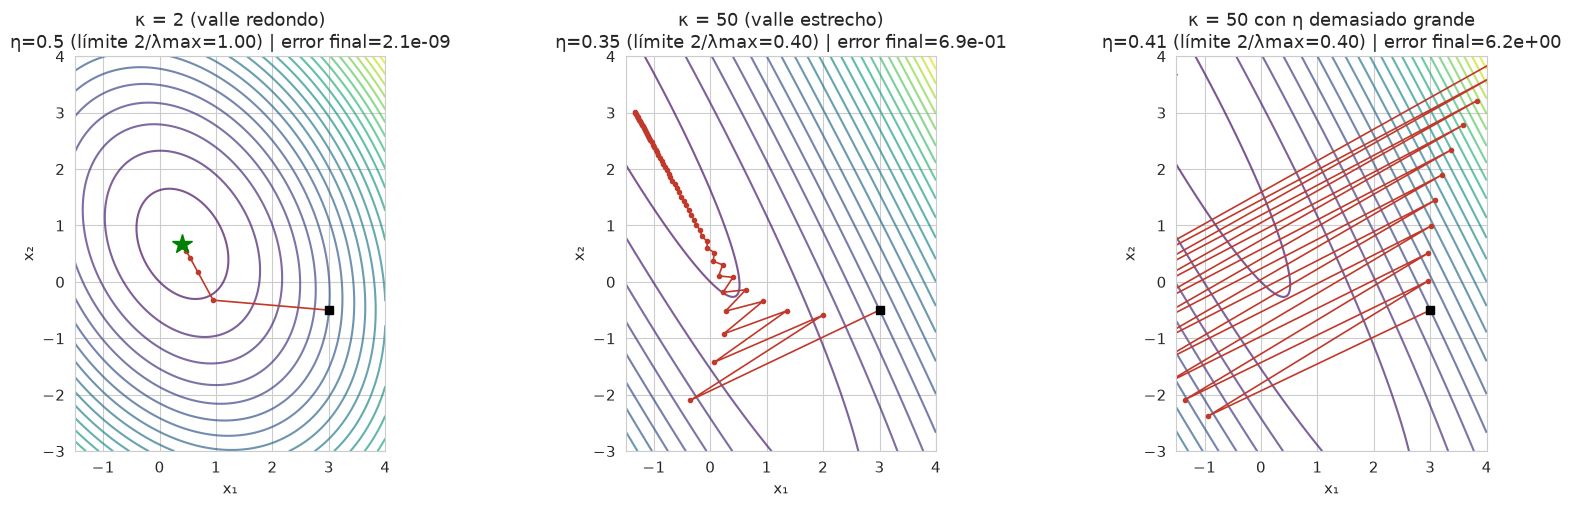

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
x0 = np.array([3.0, -0.5])
cases = [("κ = 2 (valle redondo)", [2.0, 1.0], 0.5, 30),
         ("κ = 50 (valle estrecho)", [5.0, 0.1], 0.35, 60),
         ("κ = 50 con η demasiado grande", [5.0, 0.1], 0.41, 20)]       # 2/λmax = 0.4 → 0.41 diverge
for ax, (name, eigs, lr, iters) in zip(axes, cases):
    A_, b_, xs = quad_problem(eigs)
    path = gradient_descent(lambda x: A_ @ x - b_, x0, lr, iters)
    plot_quad(ax, A_, b_, path, f"{name}\nη={lr} (límite 2/λmax={2/max(eigs):.2f}) | error final={np.linalg.norm(path[-1]-xs):.1e}",
              xlim=(-1.5, 4), ylim=(-3, 4))
plt.tight_layout(); plt.show()

**Qué deberías ver:** (izquierda) una trayectoria que baja directo y llega a la estrella verde (el mínimo exacto); (centro) en el valle estrecho, un **zigzag** que avanza muy lento incluso después de 60 pasos; (derecha) con $\eta$ apenas por encima del límite, los pasos **crecen** en cada iteración y el algoritmo diverge (el error final es enorme).

La conclusión cuantitativa: con el mejor $\eta$ posible, el número de iteraciones necesarias crece **linealmente con $\kappa$**. Lo medimos:

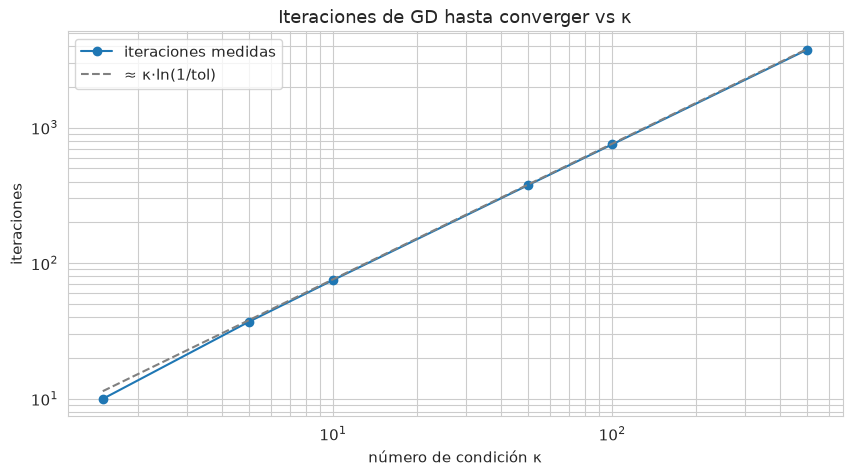

{1.5: 10, 5.0: 37, 10.0: 75, 50.0: 376, 100.0: 751, 500.0: 3753}


In [38]:
def iters_to_converge(eigs, tol=1e-6, max_iter=200_000):
    A_, b_, xs = quad_problem(eigs)
    lr = 2 / (max(eigs) + min(eigs))                    # η óptimo para una cuadrática
    x = np.array([3.0, -0.5])
    for k in range(max_iter):
        if np.linalg.norm(x - xs) < tol:
            return k
        x = x - lr * (A_ @ x - b_)
    return max_iter

kappas = np.array([1.5, 5, 10, 50, 100, 500])
its = np.array([iters_to_converge([k, 1.0]) for k in kappas])
fig, ax = plt.subplots()
ax.loglog(kappas, its, "o-", label="iteraciones medidas"); ax.loglog(kappas, 0.55 * kappas * np.log(1e6), "--", color="gray", label="≈ κ·ln(1/tol)")
ax.set(title="Iteraciones de GD hasta converger vs κ", xlabel="número de condición κ", ylabel="iteraciones"); ax.grid(True, which="both"); ax.legend(); plt.show()
print(dict(zip(kappas.tolist(), its.tolist())))

**Qué deberías ver:** puntos que siguen casi paralelos a la recta $\propto\kappa$: **duplicar el condicionamiento duplica el costo**. Esta es la razón matemática de que **normalizar las features** (que equilibra las escalas y baja $\kappa$) acelere tanto el entrenamiento (NB-09, NB-11), y de que existan optimizadores adaptativos como Adam (NB-17) que "corrigen" las escalas por dirección.

### 7.2 Gradient checking: depurar el cálculo del gradiente
Cuando implementas backpropagation a mano (NB-16), un error de signo o un factor omitido **no produce un error**: la red simplemente no aprende. El antídoto es comparar tu gradiente analítico con uno **numérico** por diferencias finitas centrales:
$$\frac{\partial f}{\partial x_i}\approx\frac{f(\mathbf x+h\mathbf e_i)-f(\mathbf x-h\mathbf e_i)}{2h}\qquad(\text{error }O(h^2))$$
Lo probamos con la pérdida logística (regresión logística, NB-11), cuyo gradiente analítico conocemos.

In [39]:
def numerical_gradient(f, w, h=1e-6):
    g = np.zeros_like(w)
    for i in range(len(w)):
        e = np.zeros_like(w); e[i] = h
        g[i] = (f(w + e) - f(w - e)) / (2 * h)       # diferencia central: mucho más precisa que la unilateral
    return g

Xlog = rng.normal(size=(200, 4)); ylog = np.where(Xlog @ np.array([1.0, -2.0, 0.5, 0.0]) + rng.normal(0, 0.5, 200) > 0, 1.0, -1.0)

def logistic_loss(w):                                  # etiquetas en {-1, +1}: L = mean log(1 + exp(-y wᵀx))
    return np.mean(np.logaddexp(0, -ylog * (Xlog @ w)))       # logaddexp(0, t) = log(1+e^t) sin desbordar

def logistic_grad(w):
    return -(Xlog * (ylog * special.expit(-ylog * (Xlog @ w)))[:, None]).mean(axis=0)   # expit = sigmoide estable

def logistic_grad_buggy(w):                            # error típico: olvidamos el signo menos
    return +(Xlog * (ylog * special.expit(-ylog * (Xlog @ w)))[:, None]).mean(axis=0)

w0 = rng.normal(size=4)
rel_err = lambda ga, gn: np.linalg.norm(ga - gn) / (np.linalg.norm(ga) + np.linalg.norm(gn))
gn = numerical_gradient(logistic_loss, w0)
print(f"gradiente correcto: error relativo = {rel_err(logistic_grad(w0), gn):.2e}   (regla: < 1e-6 → OK)")
print(f"gradiente con bug : error relativo = {rel_err(logistic_grad_buggy(w0), gn):.2e}   (≈ 1 → ¡hay un error!)")

gradiente correcto: error relativo = 6.13e-11   (regla: < 1e-6 → OK)
gradiente con bug : error relativo = 1.00e+00   (≈ 1 → ¡hay un error!)


**Qué deberías ver:** un error relativo del orden de $10^{-9}$ o menor para el gradiente correcto, y cercano a **1** para el que tiene el signo invertido. Regla práctica: menos de $10^{-6}$ está bien; más de $10^{-3}$ casi seguro hay un bug. Úsalo **siempre** al implementar backprop desde cero (NB-16), y apágalo después (es $O(n)$ evaluaciones de la pérdida: carísimo).

### 7.3 Newton–Raphson
GD usa solo la pendiente (primer orden). **Newton** usa también la **curvatura** (la matriz Hessiana $H$) y modela la función localmente como una parábola, saltando directo a su mínimo.

- **Búsqueda de raíces** (1D): $x_{k+1}=x_k-\dfrac{f(x_k)}{f'(x_k)}$ (la recta tangente corta el eje).
- **Minimización** (nD): $\mathbf x_{k+1}=\mathbf x_k-H^{-1}\nabla f(\mathbf x_k)$ (se resuelve $H\Delta=-\nabla f$, no se invierte $H$).

Su virtud: **convergencia cuadrática** (los dígitos correctos se **duplican** en cada paso). Veámoslo calculando $\sqrt2$ como raíz de $f(x)=x^2-2$ y comparándolo con la bisección:

In [40]:
def newton_root(f, df, x0, n=7):
    xs = [x0]
    for _ in range(n):
        xs.append(xs[-1] - f(xs[-1]) / df(xs[-1]))
    return np.array(xs)

def bisection(f, a, b, n=7):
    mids = []
    for _ in range(n):
        m = (a + b) / 2; mids.append(m)
        a, b = (a, m) if f(a) * f(m) <= 0 else (m, b)
    return np.array(mids)

fx, dfx = lambda x: x ** 2 - 2, lambda x: 2 * x
xs_newton = newton_root(fx, dfx, 1.0, n=6)
xs_bis = bisection(fx, 1.0, 2.0, n=7)
print(f"{'paso':>4} {'Newton':>20} {'error Newton':>14} {'error bisección':>16}")
for k in range(7):
    en = abs(xs_newton[k] - np.sqrt(2)) if k < len(xs_newton) else np.nan
    eb = abs(xs_bis[k] - np.sqrt(2)) if k < len(xs_bis) else np.nan
    print(f"{k:>4} {xs_newton[k] if k < len(xs_newton) else np.nan:>20.15f} {en:>14.2e} {eb:>16.2e}")

paso               Newton   error Newton  error bisección
   0    1.000000000000000       4.14e-01         8.58e-02
   1    1.500000000000000       8.58e-02         1.64e-01
   2    1.416666666666667       2.45e-03         3.92e-02
   3    1.414215686274510       2.12e-06         2.33e-02
   4    1.414213562374690       1.59e-12         7.96e-03
   5    1.414213562373095       0.00e+00         7.66e-03
   6    1.414213562373095       2.22e-16         1.51e-04


**Qué deberías ver:** el error de Newton pasa por ~$10^{-1}\to10^{-3}\to10^{-6}\to10^{-12}\to$ precisión de máquina: **los exponentes se duplican** (convergencia cuadrática), mientras la bisección solo **reduce a la mitad el intervalo** en cada paso (convergencia lineal; su error puntual sube y baja, pero la cota se parte por 2).

Ahora Newton en varias dimensiones, sobre un problema difícil: la **función de Rosenbrock** $f(x,y)=(1-x)^2+100(y-x^2)^2$, un valle curvo y estrecho con mínimo en $(1,1)$, el banco de pruebas clásico de optimizadores. Comparamos GD, Newton (con una búsqueda de línea de retroceso para asegurar descenso) y BFGS (cuasi-Newton de SciPy).

In [41]:
rosen = lambda p: (1 - p[0]) ** 2 + 100 * (p[1] - p[0] ** 2) ** 2
rosen_grad = lambda p: np.array([-2 * (1 - p[0]) - 400 * p[0] * (p[1] - p[0] ** 2), 200 * (p[1] - p[0] ** 2)])
rosen_hess = lambda p: np.array([[2 - 400 * (p[1] - p[0] ** 2) + 800 * p[0] ** 2, -400 * p[0]], [-400 * p[0], 200.0]])

def newton_opt(f, g, H, x0, n=50, tol=1e-10):
    x = np.asarray(x0, float); path = [x.copy()]
    for _ in range(n):
        grad = g(x)
        if np.linalg.norm(grad) < tol:
            break
        step = np.linalg.solve(H(x), -grad)                 # resolver, no invertir
        if grad @ step >= 0:                                 # si H no es definida positiva, usar -grad (seguridad)
            step = -grad
        t = 1.0
        while f(x + t * step) > f(x) + 1e-4 * t * (grad @ step) and t > 1e-12:     # búsqueda de línea (Armijo)
            t *= 0.5
        x = x + t * step; path.append(x.copy())
    return np.array(path)

start = np.array([-1.2, 1.0])
path_gd = gradient_descent(rosen_grad, start, 1e-3, 5000)
path_newton = newton_opt(rosen, rosen_grad, rosen_hess, start)
res_bfgs = optimize.minimize(rosen, start, jac=rosen_grad, method="BFGS")

print(f"GD (5000 pasos, η=1e-3): x = {path_gd[-1].round(4)} | f = {rosen(path_gd[-1]):.2e}")
print(f"Newton ({len(path_newton)-1} pasos)        : x = {path_newton[-1].round(6)} | f = {rosen(path_newton[-1]):.2e}")
print(f"BFGS ({res_bfgs.nit} pasos)           : x = {res_bfgs.x.round(6)} | f = {res_bfgs.fun:.2e}")

GD (5000 pasos, η=1e-3): x = [0.9387 0.881 ] | f = 3.76e-03
Newton (22 pasos)        : x = [1. 1.] | f = 0.00e+00
BFGS (32 pasos)           : x = [1. 1.] | f = 2.54e-15


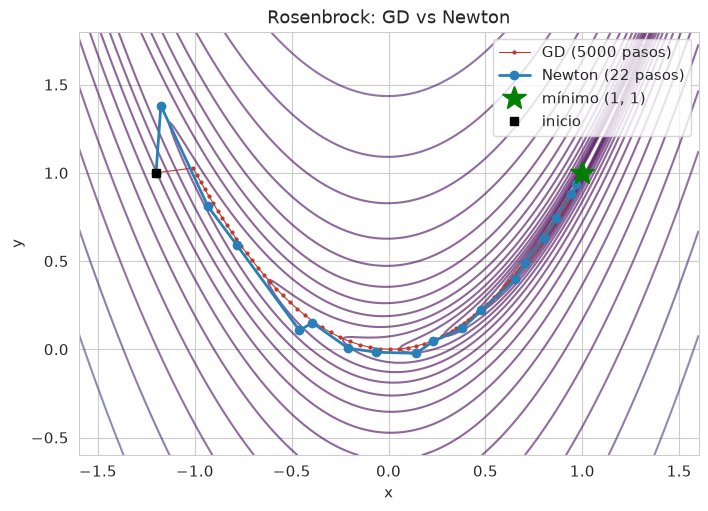

In [42]:
fig, ax = plt.subplots(figsize=(8, 5.5))
gx, gy = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-0.6, 1.8, 300))
ax.contour(gx, gy, (1 - gx) ** 2 + 100 * (gy - gx ** 2) ** 2, levels=np.logspace(-1, 3.5, 20), cmap="viridis", alpha=0.6)
ax.plot(*path_gd[::25].T, ".-", color="#c0392b", ms=4, lw=0.8, label=f"GD (5000 pasos)")
ax.plot(*path_newton.T, "o-", color="#2980b9", lw=2, label=f"Newton ({len(path_newton)-1} pasos)")
ax.plot(1, 1, "g*", ms=18, label="mínimo (1, 1)"); ax.plot(*start, "ks", label="inicio")
ax.set(title="Rosenbrock: GD vs Newton", xlabel="x", ylabel="y"); ax.grid(True); ax.legend(); plt.show()

**Qué deberías ver:** GD (rojo) avanza lentísimo y todavía **no ha llegado** tras 5.000 pasos (se arrastra por el fondo curvo del valle); Newton (azul) y BFGS llegan al mínimo exacto en **decenas de pasos**. Newton aprovecha la curvatura: corrige la dirección según la forma del valle.

#### ¿Y por qué no usamos Newton en deep learning?
| | Gradiente descendente | Newton |
|---|---|---|
| Coste por paso | $O(n)$ | $O(n^2)$ memoria + $O(n^3)$ resolver (para $n=10^8$ parámetros: imposible) |
| Pasos necesarios | muchos | pocos (cuadrática cerca del óptimo) |
| Robustez | alta (funciona lejos del óptimo) | frágil: $H$ puede no ser definida positiva |
| Variantes prácticas | SGD, Momentum, **Adam** (NB-17) | **BFGS/L-BFGS** (cuasi-Newton; `scipy.optimize`, regresión logística en sklearn) |

> **NOTA (honestidad):** en problemas **pequeños y suaves** (regresión logística con pocas features) L-BFGS suele ser mejor que SGD, y de hecho es el solver por defecto de `LogisticRegression` en scikit-learn. En redes profundas con millones de parámetros y datos ruidosos, domina el gradiente estocástico.

### 🔧 Pruébalo tú mismo

**7-1. Ajusta η:** en el caso κ = 50, prueba η = 0.05, 0.2 y 0.39. Grafica el error vs iteración (escala log) para las tres. ¿Cuál converge más rápido? ¿Coincide con $\eta_{opt}=2/(\lambda_{max}+\lambda_{min})$?

**7-2. Escalar features:** genera `X` con dos columnas, una en [0,1] y otra en [0,1000]; calcula $\kappa(X^\top X)$ antes y después de estandarizar (`(X-mean)/std`). Relaciónalo con la velocidad de GD.

**7-3. Raíz cúbica con Newton:** usa `newton_root` para calcular $\sqrt[3]{10}$ (raíz de $x^3-10$). ¿Cuántos pasos necesita para 12 dígitos?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 7-1, 7-2 y 7-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

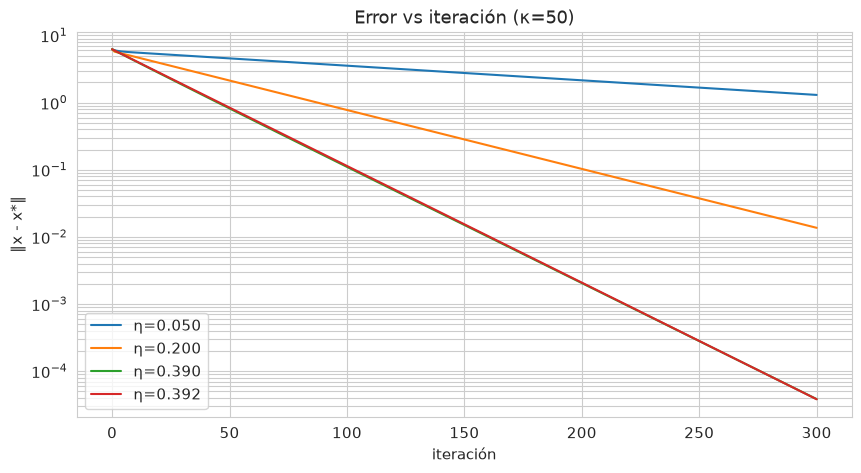

κ(XᵀX) sin escalar = 2.4e+06 | estandarizado = 1.1e+00
errores: [0.1544 0.0122 0.0001 0.     0.     0.     0.     0.     0.    ]
→ en ~5 pasos se alcanza precisión de máquina (convergencia cuadrática)


In [43]:
A_, b_, xs_ = quad_problem([5.0, 0.1])                                                    # 7-1
fig, ax = plt.subplots()
for lr in (0.05, 0.2, 0.39, 2 / 5.1):
    pth = gradient_descent(lambda x: A_ @ x - b_, x0, lr, 300)
    ax.semilogy(np.linalg.norm(pth - xs_, axis=1) + 1e-16, label=f"η={lr:.3f}")
ax.set(title="Error vs iteración (κ=50)", xlabel="iteración", ylabel="‖x - x*‖"); ax.grid(True, which="both"); ax.legend(); plt.show()
Xs = np.column_stack([rng.uniform(0, 1, 500), rng.uniform(0, 1000, 500)])                  # 7-2
Xz = (Xs - Xs.mean(0)) / Xs.std(0)
print(f"κ(XᵀX) sin escalar = {np.linalg.cond(Xs.T @ Xs):.1e} | estandarizado = {np.linalg.cond(Xz.T @ Xz):.1e}")
r3 = newton_root(lambda x: x ** 3 - 10, lambda x: 3 * x ** 2, 2.0, n=8)                    # 7-3
print("errores:", np.abs(r3 - 10 ** (1 / 3)))
print("→ en ~5 pasos se alcanza precisión de máquina (convergencia cuadrática)")

### 📊 Resumen visual — optimización
```
   MÉTODO            USA                  COSTO/PASO    CONVERGENCIA           DEPENDE DE
 ─────────────────────────────────────────────────────────────────────────────────────────────
  Descenso grad.     ∇f                   O(n)          lineal (∝ κ·ln 1/ε)    κ = λmax/λmin, η < 2/λmax
  Newton             ∇f y Hessiana        O(n³)         cuadrática (cerca)     H def. positiva; línea de búsqueda
  BFGS / L-BFGS      ∇f (aprox. H)        O(n²)/O(n)    superlineal            problemas medianos y suaves
  SGD / Adam         ∇f en mini-lotes     O(batch)      ruidosa pero escalable  deep learning (NB-17)

   CHECKLIST ANTES DE ENTRENAR:  ✔ gradient check (<1e-6)   ✔ features escaladas (κ↓)   ✔ η < 2/λmax   ✔ pérdida sin NaN
```

## 8. NumPy avanzado

### 8.1 `einsum`: la notación de Einstein
**Por qué:** muchas operaciones de ML son sumas de productos con índices (`matmul`, trazas, productos por lotes, la atención de un Transformer). `np.einsum` las expresa con una **cadena de índices**: los índices repetidos se **suman**, los que aparecen a la derecha de `->` se **conservan**. Al principio parece críptico, pero evita transposiciones y temporales innecesarios.

In [44]:
A_e, B_e = rng.normal(size=(3, 4)), rng.normal(size=(4, 5))
v1, v2 = rng.normal(size=4), rng.normal(size=4)

checks = {
    "producto matricial   'ij,jk->ik'": (np.einsum("ij,jk->ik", A_e, B_e), A_e @ B_e),
    "producto punto       'i,i->'    ": (np.einsum("i,i->", v1, v2), v1 @ v2),
    "producto externo     'i,j->ij'  ": (np.einsum("i,j->ij", v1, v2), np.outer(v1, v2)),
    "traza                'ii->'     ": (np.einsum("ii->", A_e[:3, :3]), np.trace(A_e[:3, :3])),
    "transpuesta          'ij->ji'   ": (np.einsum("ij->ji", A_e), A_e.T),
    "suma por columnas    'ij->j'    ": (np.einsum("ij->j", A_e), A_e.sum(axis=0)),
}
for name, (got, ref) in checks.items():
    print(name, "→", np.allclose(got, ref))

# Producto por lotes: 10 matrices (3x4) por 10 matrices (4x5) a la vez
Ab, Bb = rng.normal(size=(10, 3, 4)), rng.normal(size=(10, 4, 5))
print("lotes 'bij,bjk->bik' →", np.allclose(np.einsum("bij,bjk->bik", Ab, Bb), Ab @ Bb))

producto matricial   'ij,jk->ik' → True
producto punto       'i,i->'     → True
producto externo     'i,j->ij'   → True
traza                'ii->'      → True
transpuesta          'ij->ji'    → True
suma por columnas    'ij->j'     → True
lotes 'bij,bjk->bik' → True


**Qué deberías ver:** siete `True`. Lectura rápida de una cadena: en `'ij,jk->ik'` el índice `j` aparece en ambos operandos y **no** aparece a la derecha, luego se suma sobre él: es exactamente el producto matricial.

Un uso más cercano a IA Avanzada: las **puntuaciones de atención** (NB-20) $\text{scores}=QK^\top/\sqrt{d}$ para un lote de secuencias se escriben `'bqd,bkd->bqk'`:

In [45]:
batch, seq, dim = 2, 5, 8
Qm, Km = rng.normal(size=(batch, seq, dim)), rng.normal(size=(batch, seq, dim))
scores = np.einsum("bqd,bkd->bqk", Qm, Km) / np.sqrt(dim)       # (lote, consulta, clave)
weights = special.softmax(scores, axis=-1)                       # cada consulta reparte atención entre las claves
print("scores:", scores.shape, "| ¿cada fila suma 1?", np.allclose(weights.sum(axis=-1), 1))
print("equivale a Q @ Kᵀ:", np.allclose(scores, (Qm @ Km.transpose(0, 2, 1)) / np.sqrt(dim)))

scores: (2, 5, 5) | ¿cada fila suma 1? True
equivale a Q @ Kᵀ: True


**Qué deberías ver:** `scores: (2, 5, 5)`, y que cada fila de los pesos suma 1. Ya escribiste, sin saberlo, el corazón de un Transformer.

> **NOTA:** para operaciones con 3+ operandos, `np.einsum(..., optimize=True)` busca el mejor orden de contracción y puede acelerar órdenes de magnitud. Para un simple producto de dos matrices, `@` sigue siendo más rápido (usa BLAS).

### 8.2 Memoria, `strides` y *vistas*
Un array es un **bloque de memoria** más una *plantilla* (`shape` + `strides`: cuántos bytes saltar para avanzar una posición en cada eje). Muchas operaciones (transponer, rebanar, `reshape` sin copia) solo **cambian la plantilla**, sin mover datos. Eso las hace gratis, pero también significa que el orden de recorrido importa para la velocidad (la caché del CPU prefiere memoria contigua).

In [46]:
a = np.arange(12).reshape(3, 4)
print("a      strides:", a.strides, "| C-contiguo:", a.flags["C_CONTIGUOUS"])
print("a.T    strides:", a.T.strides, "| ¿comparte memoria? ", np.shares_memory(a, a.T), "| F-contiguo:", a.T.flags["F_CONTIGUOUS"])

big = rng.normal(size=(4000, 4000))
big_T = big.T                                                    # vista: mismos datos, strides invertidos (se recorre "a saltos")
big_T_copy = np.ascontiguousarray(big.T)                         # copia contigua en memoria (cuesta una vez)

t_same = time_ms(lambda: big + big, 3)                           # ambos operandos se recorren en el mismo orden
t_mixed = time_ms(lambda: big + big_T, 3)                        # uno recorre filas y el otro columnas: la caché sufre
t_fixed = time_ms(lambda: big + big_T_copy, 3)                   # con la copia contigua se recupera la localidad
print(f"\nbig + big                      : {t_same:7.1f} ms")
print(f"big + big.T  (vista)           : {t_mixed:7.1f} ms   ← {t_mixed / t_same:.1f}× el tiempo: mismos datos, distinto orden de acceso")
print(f"big + ascontiguousarray(big.T) : {t_fixed:7.1f} ms   (sin contar el costo único de la copia)")

a      strides: (32, 8) | C-contiguo: True
a.T    strides: (8, 32) | ¿comparte memoria?  True | F-contiguo: True

big + big                      :    30.3 ms
big + big.T  (vista)           :    83.4 ms   ← 2.7× el tiempo: mismos datos, distinto orden de acceso
big + ascontiguousarray(big.T) :    18.6 ms   (sin contar el costo único de la copia)


**Qué deberías ver:** `a.T` comparte memoria con `a` (solo invirtió los strides: transponer es gratis). Pero **no todo es gratis**: sumar `big + big.T` recorre un operando por filas y el otro por columnas, y la caché del CPU lo penaliza (el factor exacto depende de tu máquina; lo normal es varias veces más tiempo que `big + big`). Si vas a usar esa vista muchas veces, pagar una copia contigua con `np.ascontiguousarray` suele compensar. *(Nota: `sum(axis=...)` no muestra esta diferencia porque NumPy la optimiza internamente para ambos ejes.)*

#### `sliding_window_view`: convolución y filtros sin bucles
Una **ventana deslizante** es una vista (sin copiar) de todos los segmentos consecutivos de longitud $k$ de una señal. Con ella, un **filtro FIR** (promedio móvil, convolución con la respuesta al impulso de un canal) es un producto matriz-vector. Es el vínculo directo con Comunicaciones Digitales: la salida de un canal con ISI es $y[n]=\sum_k h[k]\,x[n-k]$ (una convolución).

In [47]:
x_sig = np.sin(2 * np.pi * 0.02 * np.arange(500)) + 0.4 * rng.normal(size=500)        # señal ruidosa
h_ma = np.ones(11) / 11                                                                # promedio móvil de 11 puntos

win = sliding_window_view(x_sig, 11)                       # forma (490, 11): cada fila = una ventana, SIN copiar datos
y_win = win @ h_ma[::-1]                                   # convolución = producto con h invertida (por definición)
y_conv = np.convolve(x_sig, h_ma, mode="valid")
y_fft = signal.fftconvolve(x_sig, h_ma, mode="valid")
print("ventana @ h == np.convolve == FFT:", np.allclose(y_win, y_conv), np.allclose(y_conv, y_fft))
print("win.base is x_sig (vista, no copia):", win.base is not None and np.shares_memory(win, x_sig))

ventana @ h == np.convolve == FFT: True True
win.base is x_sig (vista, no copia): True


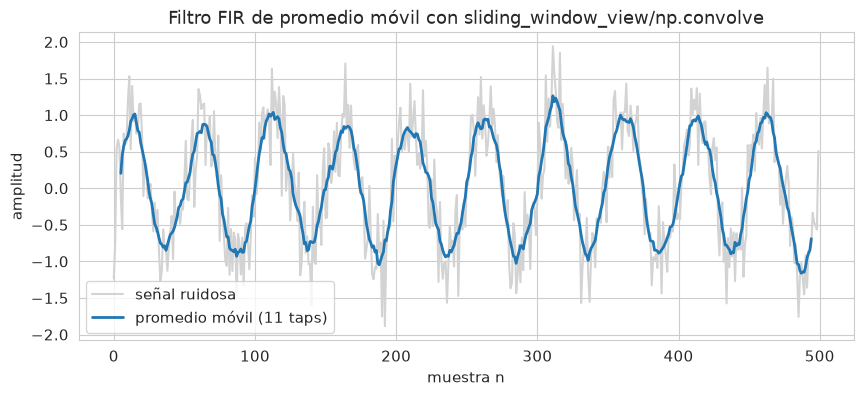

  taps   np.convolve (ms)   fftconvolve (ms)
    11                0.3               11.5
   101                6.4               17.4
  1001               40.2                8.7
  5001              189.2                8.4


In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x_sig, color="lightgray", label="señal ruidosa")
ax.plot(np.arange(5, 495), y_conv, lw=2, label="promedio móvil (11 taps)")
ax.set(title="Filtro FIR de promedio móvil con sliding_window_view/np.convolve", xlabel="muestra n", ylabel="amplitud"); ax.grid(True); ax.legend()
plt.show()

# ¿Cuándo conviene FFT? Costo directo O(N·K) vs FFT O(N log N): gana cuando el filtro es largo
big_x = rng.normal(size=200_000)
rows = []
for K in (11, 101, 1001, 5001):
    hk = rng.normal(size=K)
    rows.append((K, time_ms(lambda: np.convolve(big_x, hk, "valid"), repeat=2), time_ms(lambda: signal.fftconvolve(big_x, hk, "valid"), repeat=2)))
print(f"{'taps':>6} {'np.convolve (ms)':>18} {'fftconvolve (ms)':>18}")
for K, t1, t2 in rows:
    print(f"{K:>6} {t1:>18.1f} {t2:>18.1f}")

**Qué deberías ver:** la curva suave atravesando la señal ruidosa (el filtro elimina el ruido de alta frecuencia a costa de un pequeño retraso/recorte en los bordes por `mode="valid"`). En la tabla, `np.convolve` (costo $O(NK)$) gana con filtros cortos y la FFT (costo $O(N\log N)$) la supera ampliamente cuando el filtro tiene miles de coeficientes. En comunicaciones, un canal con ISI corta (3–10 taps) se simula con `np.convolve`; un canal de miles de taps (p. ej. acústico) con FFT.

### 8.3 Precisión numérica: los flotantes no son los reales
`float64` tiene ~16 dígitos; `float32` ~7. Tres trampas frecuentes y sus remedios:

In [49]:
eps64, eps32 = np.finfo(np.float64).eps, np.finfo(np.float32).eps
print(f"ε float64 = {eps64:.2e} | ε float32 = {eps32:.2e}")
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3, "| np.isclose:", np.isclose(0.1 + 0.2, 0.3), "| diferencia:", (0.1 + 0.2) - 0.3)

# 1) Cancelación catastrófica: (1 - cos x)/x² para x muy pequeño (valor real → 0.5)
x_small = 1e-8
naive = (1 - np.cos(x_small)) / x_small ** 2
stable = 2 * np.sin(x_small / 2) ** 2 / x_small ** 2          # identidad trigonométrica que evita restar números casi iguales
print(f"\n(1-cos x)/x² con x=1e-8 → ingenua: {naive}  | estable: {stable}  | real: 0.5")

# 2) log1p / expm1: precisión para argumentos pequeños
print(f"log(1+1e-12) = {np.log(1 + 1e-12):.6e} (impreciso) | log1p(1e-12) = {np.log1p(1e-12):.6e} (exacto: 1e-12)")

ε float64 = 2.22e-16 | ε float32 = 1.19e-07
0.1 + 0.2 == 0.3 ? False | np.isclose: True | diferencia: 5.551115123125783e-17

(1-cos x)/x² con x=1e-8 → ingenua: 0.0  | estable: 0.5  | real: 0.5
log(1+1e-12) = 1.000089e-12 (impreciso) | log1p(1e-12) = 1.000000e-12 (exacto: 1e-12)


In [50]:
# 3) Acumulación de errores en float32: sumar 10 millones de 0.1 (resultado exacto = 1.000.000)
v32 = np.full(10_000_000, 0.1, dtype=np.float32)
seq = np.cumsum(v32)[-1]                                       # cumsum acumula de forma secuencial → el error crece
pairwise = v32.sum()                                           # np.sum usa suma por pares → error mucho menor
exact = math.fsum(v32.astype(np.float64))                      # fsum: suma "exacta" de referencia
print(f"secuencial float32: {seq:,.1f} (error {abs(seq - exact):,.1f}) | por pares: {pairwise:,.1f} (error {abs(pairwise - exact):,.2f}) | fsum: {exact:,.1f}")
assert abs(pairwise - exact) < abs(seq - exact)
print("float32 también limita el tamaño: 16_777_217 como float32 =", np.float32(16_777_217), "(¡no representable!)")

secuencial float32: 1,087,937.0 (error 87,937.0) | por pares: 1,000,000.1 (error 0.12) | fsum: 1,000,000.0
float32 también limita el tamaño: 16_777_217 como float32 = 1.6777216e+07 (¡no representable!)


**Qué deberías ver:** (1) `0.1 + 0.2 != 0.3`, diferencia ~$5.5\times10^{-17}$: compara siempre con `np.isclose`; (2) la fórmula ingenua con $x=10^{-8}$ da **0** (¡todos los dígitos perdidos!) mientras la estable da 0.5; (3) la suma secuencial en `float32` se desvía de 1.000.000 en **decenas de miles** de unidades (un error de ~9 %), y la suma por pares de NumPy queda mucho más cerca. Esto último es relevante para **sistemas distribuidos**: como la suma de flotantes no es asociativa, el resultado de sumar en distinto orden (distintos nodos, distinto número de hilos) puede variar en los últimos dígitos, algo a tener presente al comparar resultados entre ejecuciones (reproducibilidad).

### 8.4 Rendimiento: lo que de verdad importa
Cuatro hábitos que dan la mayoría de las mejoras (mide antes de optimizar):

In [51]:
n_big = 5_000_000
a_, b_, c_ = rng.normal(size=n_big), rng.normal(size=n_big), rng.normal(size=n_big)
tmp = np.empty(n_big)

def with_temporaries():  return a_ * b_ + c_                          # crea un temporal para a*b y otro para el resultado
def with_out():          np.multiply(a_, b_, out=tmp); np.add(tmp, c_, out=tmp); return tmp   # reutiliza un buffer

# np.vectorize NO vectoriza: es un bucle de Python con otra sintaxis
f_scalar = lambda v: v if v > 0 else 0.0
f_vec = np.vectorize(f_scalar)
small = a_[:200_000]

# float32 vs float64 en un producto matricial grande (la GPU y los modelos usan float32/float16)
M64 = rng.normal(size=(1500, 1500)); M32 = M64.astype(np.float32)

results = {
    "a*b+c (temporales)": time_ms(with_temporaries, 3),
    "a*b+c (out=, sin temporales)": time_ms(with_out, 3),
    "np.vectorize (200k elem.)": time_ms(lambda: f_vec(small), 2),
    "np.maximum(x, 0) (200k elem.)": time_ms(lambda: np.maximum(small, 0), 2),
    "matmul 1500² float64": time_ms(lambda: M64 @ M64, 3),
    "matmul 1500² float32": time_ms(lambda: M32 @ M32, 3),
}
for k, v in results.items():
    print(f"{k:34s} {v:9.2f} ms")

a*b+c (temporales)                      9.87 ms
a*b+c (out=, sin temporales)            5.41 ms
np.vectorize (200k elem.)              35.12 ms
np.maximum(x, 0) (200k elem.)           0.42 ms
matmul 1500² float64                   40.04 ms
matmul 1500² float32                    9.24 ms


**Qué deberías ver (los números exactos dependen de tu máquina):**
- `out=` suele ser algo más rápido que dejar que NumPy cree temporales (y usa menos memoria pico); la ganancia es modesta pero importa en arrays enormes y bucles internos.
- `np.vectorize` es **decenas o cientos de veces más lento** que la operación vectorizada real: su documentación lo dice, es solo *azúcar sintáctico* para un bucle.
- `float32` multiplica matrices típicamente **2–3× más rápido** que `float64` (la mitad de bytes y más SIMD por instrucción).

**Cuándo ir más allá de NumPy:** si tu cuello de botella es un bucle que no se puede vectorizar, **Numba** (`@njit`) compila Python a código máquina; **JAX/PyTorch** dan diferenciación automática y GPU con una API casi idéntica a NumPy (por eso lo aprendido aquí se transfiere a NB-16). Y si los datos no caben en RAM, Dask/Polars/Spark (ver NB-22).

### 🔧 Pruébalo tú mismo

**8-1. einsum práctico:** escribe con `einsum` (a) la suma de todos los elementos de una matriz, (b) la norma de Frobenius al cuadrado, (c) la diagonal de `A @ B` **sin** calcular el producto completo. Verifica con NumPy.

**8-2. Media móvil a mano:** implementa un promedio móvil de ventana `k` con `np.cumsum` (la diferencia de sumas acumuladas) y compáralo con `sliding_window_view(...).mean(axis=1)`. ¿Cuál es más rápido para `k` grande?

**8-3. Varianza inestable:** calcula la varianza de `1e9 + rng.normal(size=10**6)` con la fórmula ingenua `mean(x²) - mean(x)²` y con `np.var`. ¿Qué observas? ¿Por qué?

*(Las soluciones están al final de esta sección, en celdas colapsadas.)*

#### ✅ Soluciones — 8-1, 8-2 y 8-3
*Intenta primero por tu cuenta; expande la celda de abajo para comparar.*

In [52]:
Ma, Mb = rng.normal(size=(5, 5)), rng.normal(size=(5, 5))                                           # 8-1
print(np.isclose(np.einsum("ij->", Ma), Ma.sum()), np.isclose(np.einsum("ij,ij->", Ma, Ma), np.linalg.norm(Ma) ** 2),
      np.allclose(np.einsum("ij,ji->i", Ma, Mb), np.diag(Ma @ Mb)))   # (c) es O(n²) en vez de O(n³)
sig = rng.normal(size=1_000_000); k_ = 5000                                                         # 8-2
def ma_cumsum(x, k):
    cs = np.cumsum(np.insert(x, 0, 0.0)); return (cs[k:] - cs[:-k]) / k
ref_ma = sliding_window_view(sig[:50_000], 500).mean(axis=1)
print("coinciden:", np.allclose(ma_cumsum(sig[:50_000], 500), ref_ma))
print(f"k={k_}: cumsum {time_ms(lambda: ma_cumsum(sig, k_), 2):.1f} ms | ventanas {time_ms(lambda: sliding_window_view(sig, k_).mean(axis=1), 1):.0f} ms (la ventana es O(N·k); cumsum es O(N))")
xv = 1e9 + rng.normal(size=10 ** 6)                                                                 # 8-3
print(f"ingenua: {np.mean(xv**2) - np.mean(xv)**2:.4f} | np.var: {np.var(xv):.4f} | real ≈ 1")
# La fórmula ingenua resta dos números ~1e18 que difieren en ~1: cancelación catastrófica (pierde todos los dígitos útiles).

True True True
coinciden: True
k=5000: cumsum 20.3 ms | ventanas 1055 ms (la ventana es O(N·k); cumsum es O(N))
ingenua: 128.0000 | np.var: 1.0001 | real ≈ 1


### 📊 Resumen visual — NumPy avanzado
```
 HERRAMIENTA            RESUELVE                                       RECUERDA
 ───────────────────────────────────────────────────────────────────────────────────────────────
 einsum                 sumas de productos con índices (matmul, atención)  índice repetido y ausente a la derecha → se suma
 strides / vistas       transponer/rebanar sin copiar                    modificar una vista modifica el original
 order='C'/'F'          localidad de memoria                             recorre el eje contiguo
 sliding_window_view    ventanas sin copiar (FIR, features locales)      costo O(N·k); FFT para k grande
 fftconvolve            convolución larga                                O(N log N)
 float32 / float64      memoria vs precisión                              ε=1.2e-7 / 2.2e-16; compara con isclose
 logsumexp, log1p, xlogy  estabilidad numérica                           evitan inf/NaN y cancelación
 out=, vectorizar       rendimiento                                      np.vectorize NO es vectorización
```

## 9. 📋 Cheat Sheet

| Concepto / Función | Qué hace | Cuándo usarlo | Sintaxis rápida |
|---|---|---|---|
| `a @ b`, `np.dot` | producto punto / matricial | siempre | `W @ x + b` |
| `np.linalg.norm` | norma de vector/matriz | distancias, regularización | `np.linalg.norm(x, ord=1)` · `axis=1` por filas |
| coseno | similitud por dirección | embeddings, texto | `Xn = X/np.linalg.norm(X,axis=1,keepdims=True); Xn@Xn.T` |
| `np.linalg.det`, `matrix_rank` | área/volumen y dimensión | ¿invertible? | `np.linalg.matrix_rank(A)` |
| `np.linalg.cond` | número de condición | diagnosticar inestabilidad | `np.linalg.cond(A)` (> 1e8: desconfía) |
| `np.linalg.solve` | resolver $A x=b$ | sistema cuadrado | `np.linalg.solve(A, b)` (nunca `inv(A)@b`) |
| `np.linalg.lstsq` | mínimos cuadrados | regresión, ajuste | `np.linalg.lstsq(X, y, rcond=None)[0]` |
| `np.linalg.qr` | descomposición QR | LS estable, ortonormalizar | `Q, R = np.linalg.qr(A)` |
| `np.linalg.eigh` / `eig` | autovalores (simétrica / general) | covarianza, PCA | `lam, V = np.linalg.eigh(Sigma)` (orden ascendente) |
| `np.linalg.svd` | SVD | rango, PCA, compresión | `U, s, Vt = np.linalg.svd(A, full_matrices=False)` |
| aprox. rango k | mejor aproximación de bajo rango | compresión | `(U[:,:k]*s[:k]) @ Vt[:k]` |
| `np.linalg.pinv` | pseudoinversa | sistemas rectangulares/singulares | `np.linalg.pinv(A) @ b` |
| `np.cov`, `np.corrcoef` | covarianza / correlación | features | `np.cov(X.T)` (variables en filas) |
| Cholesky | muestrear gaussianas | simulación | `L = np.linalg.cholesky(S); mu + Z @ L.T` |
| `rng = default_rng(s)` | generador reproducible | todo muestreo | `rng.normal(size=(n, d))` |
| `scipy.stats` | pdf/cdf/ppf/fit | probabilidad | `stats.norm(mu, s).cdf(x)` |
| `special.logsumexp`, `softmax` | log-suma-exp / softmax estables | clasificación, pérdidas | `special.softmax(z, axis=-1)` |
| `special.xlogy`, `expit` | $x\log y$ seguro / sigmoide | entropía, logística | `special.xlogy(p, p)` |
| gradient check | validar gradiente | al implementar backprop | `(f(w+h)-f(w-h))/(2h)` → error rel. < 1e-6 |
| `optimize.minimize` | optimizadores clásicos | problemas pequeños | `optimize.minimize(f, x0, jac=g, method="L-BFGS-B")` |
| `np.einsum` | contracciones con índices | lotes, atención | `np.einsum("bqd,bkd->bqk", Q, K)` |
| `sliding_window_view` | ventanas sin copia | FIR, features locales | `sliding_window_view(x, k) @ h[::-1]` |
| `signal.fftconvolve` | convolución rápida | filtros largos | `signal.fftconvolve(x, h, mode="valid")` |
| `np.isclose/allclose` | comparar flotantes | siempre (nunca `==`) | `np.allclose(a, b, atol=1e-8)` |
| `np.log1p`, `np.expm1` | exactas para argumentos pequeños | probabilidades pequeñas | `np.log1p(x)` |

**Regla de oro de estabilidad:** *si una fórmula resta números casi iguales, divide por algo casi cero, o hace `exp` de algo grande, reescríbela.*

## 10. Conexiones con el Mundo Real

**En la industria.** El álgebra lineal numérica corre debajo de casi todo: motores de recomendación (factorización de matrices usuario–ítem ≈ SVD truncada), búsqueda semántica (similitud coseno entre *embeddings*), detección de anomalías (Mahalanobis), compresión y *denoising*, y el entrenamiento de todas las redes neuronales (multiplicaciones de matrices en GPU en `float32`/`bfloat16`). La estabilidad numérica no es un detalle académico: `softmax` ingenuas, `log(0)` y gradientes mal calculados son causas reales de *runs* de entrenamiento que mueren con `NaN`.

**Comunicaciones Digitales.** Todo este notebook es, en cierto sentido, el kit de herramientas de un ingeniero de comunicaciones: el **BER de BPSK** simulado en la sección 6.3 es la línea base de cualquier receptor; la convolución con la respuesta del canal modela la **ISI**; los **mínimos cuadrados** estiman el canal y diseñan ecualizadores (lo harás en el Ejercicio 3); la matriz de covarianza y la **transformada de Karhunen–Loève** (autovectores de la covarianza) son PCA en el dominio de señales; los métodos de Monte Carlo evalúan sistemas cuya teoría cerrada no existe.

**Sistemas Distribuidos.** Reproducibilidad numérica: la suma de flotantes no es asociativa, así que *reductions* distribuidas (all-reduce en entrenamiento multi-GPU) pueden diferir en los últimos bits según el orden. Por eso el entrenamiento distribuido exacto bit a bit exige cuidado explícito. Además, estimar con Monte Carlo en paralelo es *embarazosamente paralelo* (cada nodo simula con su propia semilla/`SeedSequence.spawn`).

**Tesis (SNN + diagrama de ojo + BER).**
- El **BER teórico y simulado** (sec. 6.3) define lo que tu modelo de ML debe aproximar; y la advertencia de las ~100 errores por punto explica **por qué** predecir el BER desde métricas del ojo vale la pena (evita simular $10^8$ bits).
- Las métricas de ojo de varias neuronas forman una matriz de características: su **covarianza y autovalores** (sec. 4.2) dirán cuántas dimensiones independientes tiene tu información (PCA, NB-14), y **Mahalanobis** (6.5) sirve para detectar simulaciones atípicas.
- El **ecualizador lineal por mínimos cuadrados** del Ejercicio 3 es la **línea base clásica** contra la que compararás tu ecualizador SNN.
- El **gradient checking** (7.2) es el seguro de vida cuando implementes *surrogate gradients* para SNN (NB-25): el gradiente de una neurona que dispara es una aproximación, y verificar la implementación numéricamente ahorra semanas de depuración.

**Contexto chileno / latinoamericano.** Ingeniería de telecomunicaciones (planificación de enlaces, evaluación de modulaciones con Monte Carlo), minería (PCA sobre sensores de planta para detección de fallas), astronomía (los grandes observatorios del norte de Chile procesan matrices enormes de imágenes con descomposiciones de bajo rango), y análisis financiero (matrices de covarianza de portafolios) usan exactamente estas herramientas.

**Limitaciones y alternativas.**
- NumPy corre en **una CPU** y en memoria; para matrices que no caben o necesitas GPU/autodiff, usa **PyTorch/JAX/CuPy** (misma idea, otra API; NB-16).
- Para matrices **dispersas** enormes (grafos, texto), `scipy.sparse` + `scipy.sparse.linalg.svds/eigsh` en vez de `np.linalg`.
- Newton y la SVD completa **no escalan** a millones de parámetros: se usan métodos iterativos/estocásticos y SVD aleatorizada (`sklearn.utils.extmath.randomized_svd`).
- Monte Carlo converge lento ($1/\sqrt N$): si hay estructura, usa *importance sampling* o cuasi-Monte Carlo.

## 11. Ejercicios progresivos

Cada nivel tiene una celda **"Tu turno"** y, **después**, su solución completa en celdas separadas.

---
### Nivel 1 — Reproducir (guiado): PCA desde cero con autovalores y con SVD
**Objetivo:** reconstruir PCA con lo aprendido y comprobar que coincide con `sklearn.decomposition.PCA`. Usa el dataset **Iris** (`load_iris().data`, 150×4).

**Pasos:**
1. Centra los datos (resta la media de cada columna).
2. **Vía autovalores:** calcula la covarianza, sus autovectores (`eigh`) y ordénalos de mayor a menor varianza.
3. **Vía SVD:** aplica `np.linalg.svd` a la matriz centrada; recuerda que $\lambda_i=\sigma_i^2/(n-1)$ y que las filas de $V^\top$ son los componentes.
4. Proyecta a 2 componentes y verifica que ambos métodos coinciden con `PCA(2)` (salvo el signo de cada componente).
5. Grafica los datos proyectados coloreados por especie y reporta la varianza explicada.

> 💡 **Hints:** `PCA(n_components=2).fit(X)` expone `components_` y `explained_variance_`; compara con `np.abs(...)` para ignorar signos.

In [53]:
# Tu turno (Nivel 1)

#### ✅ Solución — Nivel 1

λ (eigh) : [4.2282 0.2427 0.0782 0.0238]
λ (SVD)  : [4.2282 0.2427 0.0782 0.0238]
λ (sklearn, 2 comp.): [4.2282 0.2427]


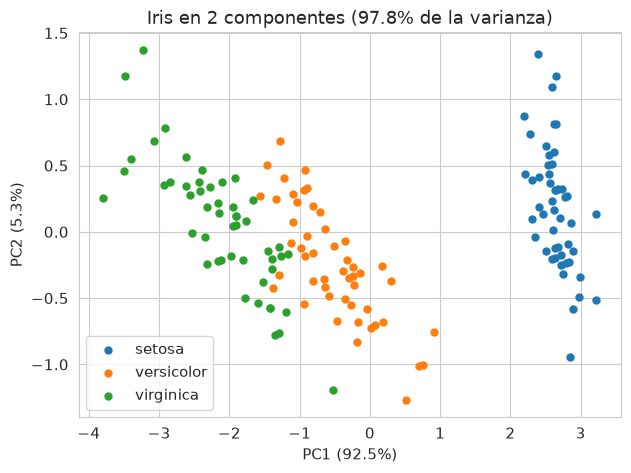

✔ eigh, SVD y sklearn coinciden


In [54]:
iris = load_iris()
X_i, y_i = iris.data, iris.target
Xc_i = X_i - X_i.mean(axis=0)                                                    # 1) centrar

lam_e, V_e = np.linalg.eigh(np.cov(Xc_i.T))                                      # 2) vía autovalores
idx = np.argsort(lam_e)[::-1]; lam_e, V_e = lam_e[idx], V_e[:, idx]

U_s, s_s, Vt_s = np.linalg.svd(Xc_i, full_matrices=False)                        # 3) vía SVD
lam_svd = s_s ** 2 / (len(Xc_i) - 1)

sk = PCA(n_components=2).fit(X_i)
print("λ (eigh) :", lam_e.round(4)); print("λ (SVD)  :", lam_svd.round(4)); print("λ (sklearn, 2 comp.):", sk.explained_variance_.round(4))
assert np.allclose(lam_e, lam_svd) and np.allclose(lam_e[:2], sk.explained_variance_)
assert np.allclose(np.abs(V_e[:, :2].T), np.abs(sk.components_)) and np.allclose(np.abs(Vt_s[:2]), np.abs(sk.components_))

Z_i = Xc_i @ V_e[:, :2]                                                          # 4) proyección
assert np.allclose(np.abs(Z_i), np.abs(sk.transform(X_i)))
fig, ax = plt.subplots(figsize=(7, 5))
for c, name in enumerate(iris.target_names):
    ax.scatter(*Z_i[y_i == c].T, label=name, s=25)
ax.set(title=f"Iris en 2 componentes ({lam_e[:2].sum() / lam_e.sum():.1%} de la varianza)", xlabel=f"PC1 ({lam_e[0]/lam_e.sum():.1%})", ylabel=f"PC2 ({lam_e[1]/lam_e.sum():.1%})")
ax.grid(True); ax.legend(); plt.show()
print("✔ eigh, SVD y sklearn coinciden")

**Qué deberías ver:** las tres rutas dan los mismos autovalores (~4.23, 0.24, 0.08, 0.02) y los mismos componentes (salvo signo). PC1 explica ≈ **92 %** de la varianza y la gráfica separa claramente *setosa* de las otras dos especies. Es la prueba de que PCA no es magia: es la SVD (o los autovectores de la covarianza) de los datos centrados. En NB-14 lo desarrollas completo (varianza explicada, reconstrucción, kernel PCA, t-SNE).

---
### Nivel 2 — Aplicar (problema nuevo): ajuste polinomial mal condicionado
**Problema:** quieres ajustar un polinomio a datos ruidosos de un sensor, probando grados de 1 a 15. Sospechas que resolver con la ecuación normal se vuelve inestable.

**Tu tarea (sin paso a paso):**
1. Genera 40 puntos $t\in[0,1]$ y, para cada grado de 1 a 15, la matriz de Vandermonde $A$ (base de potencias).
2. **Aísla el error numérico:** fija coeficientes verdaderos conocidos (`np.ones(grado+1)`), genera $y=A\,c_{true}$ **sin ruido** y recupera los coeficientes con (a) la **ecuación normal**, (b) **QR** y (c) **`lstsq`**. Reporta $\kappa(A)$, $\kappa(A^\top A)$ y el error relativo de los coeficientes.
3. Grafica error vs grado (escala log) y marca el primer grado donde la ecuación normal es ≥100× peor que `lstsq`.
4. Repite con la base de **Legendre** (`np.polynomial.legendre.legvander(2*t-1, grado)`) en lugar de potencias. ¿Qué pasa con $\kappa$ y con los errores?
5. Ahora con datos **ruidosos** ($y=\sin 2\pi t+\mathcal N(0,0.1^2)$), compara el error cuadrático medio de ajuste de los tres métodos en grado 12. ¿Se nota la diferencia? ¿Por qué el residuo puede engañarte?
6. Escribe 2–3 líneas con la lección práctica para ajustar modelos.

In [55]:
# Tu turno (Nivel 2)

#### ✅ Solución — Nivel 2

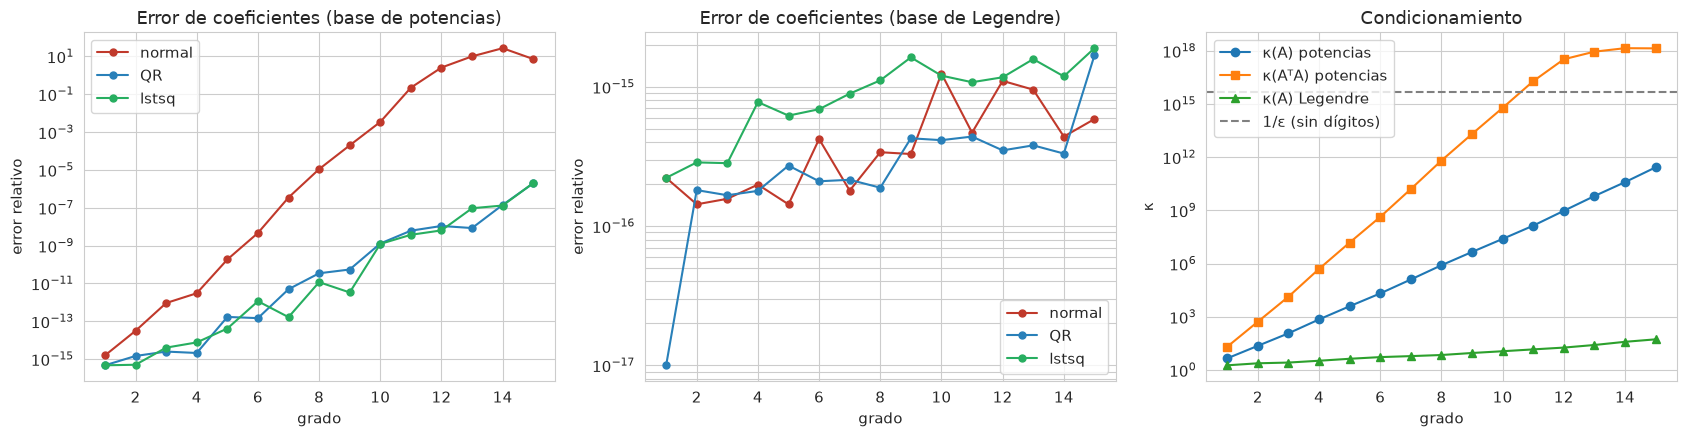

Potencias: la ecuación normal es ≥100× peor que lstsq desde el grado 3 | κ(A) grado 15: 2.7e+11 (potencias) vs 5.3e+01 (Legendre)
MSE de ajuste (grado 12): {'normal': '7.83e-03', 'QR': '7.83e-03', 'lstsq': '7.83e-03'} 
‖c_normal − c_lstsq‖/‖c_lstsq‖ = 1.3e-01


In [56]:
rp = np.random.default_rng(3)
tp = np.sort(rp.uniform(0, 1, 40))
degrees = list(range(1, 16))

def solve_three(Av, y):
    out = {}
    try:
        out["normal"] = np.linalg.solve(Av.T @ Av, Av.T @ y)
    except np.linalg.LinAlgError:                       # κ(AᵀA) tan grande que la matriz es "singular" numéricamente
        out["normal"] = np.full(Av.shape[1], np.nan)
    Qp, Rp = np.linalg.qr(Av); out["QR"] = sla.solve_triangular(Rp, Qp.T @ y)
    out["lstsq"] = np.linalg.lstsq(Av, y, rcond=None)[0]
    return out

def coef_errors(basis_fn):
    errs = {"normal": [], "QR": [], "lstsq": []}; conds = []
    for deg in degrees:
        Av = basis_fn(deg); c_true = np.ones(deg + 1)
        sol = solve_three(Av, Av @ c_true)              # datos SIN ruido: todo error es numérico
        for k in errs:
            errs[k].append(np.linalg.norm(sol[k] - c_true) / np.linalg.norm(c_true))
        conds.append((np.linalg.cond(Av), np.linalg.cond(Av.T @ Av)))
    return errs, conds

pow_err, pow_cond = coef_errors(lambda d: np.vander(tp, d + 1, increasing=True))
leg_err, leg_cond = coef_errors(lambda d: np.polynomial.legendre.legvander(2 * tp - 1, d))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, errs, name in [(axes[0], pow_err, "base de potencias"), (axes[1], leg_err, "base de Legendre")]:
    for k, c in zip(errs, ["#c0392b", "#2980b9", "#27ae60"]):
        ax.semilogy(degrees, np.maximum(errs[k], 1e-17), "o-", label=k, color=c, ms=5)
    ax.set(title=f"Error de coeficientes ({name})", xlabel="grado", ylabel="error relativo"); ax.grid(True, which="both"); ax.legend()
axes[2].semilogy(degrees, [c[0] for c in pow_cond], "o-", label="κ(A) potencias"); axes[2].semilogy(degrees, [c[1] for c in pow_cond], "s-", label="κ(AᵀA) potencias")
axes[2].semilogy(degrees, [c[0] for c in leg_cond], "^-", label="κ(A) Legendre")
axes[2].axhline(1 / np.finfo(float).eps, ls="--", color="gray", label="1/ε (sin dígitos)")
axes[2].set(title="Condicionamiento", xlabel="grado", ylabel="κ"); axes[2].grid(True, which="both"); axes[2].legend()
plt.tight_layout(); plt.show()

gap = next((d for d, a, b in zip(degrees, pow_err["normal"], pow_err["lstsq"]) if a > 100 * b), None)
print(f"Potencias: la ecuación normal es ≥100× peor que lstsq desde el grado {gap} | κ(A) grado 15: {pow_cond[-1][0]:.1e} (potencias) vs {leg_cond[-1][0]:.1e} (Legendre)")

# Paso 5: con datos ruidosos el RESIDUO apenas distingue los métodos, aunque los coeficientes sean muy distintos
yn = np.sin(2 * np.pi * tp) + rp.normal(0, 0.1, 40); A12 = np.vander(tp, 13, increasing=True)
sol_n = solve_three(A12, yn)
print("MSE de ajuste (grado 12):", {k: f"{np.mean((A12 @ c - yn) ** 2):.2e}" for k, c in sol_n.items()},
      "\n‖c_normal − c_lstsq‖/‖c_lstsq‖ =", f"{np.linalg.norm(sol_n['normal'] - sol_n['lstsq']) / np.linalg.norm(sol_n['lstsq']):.1e}")
assert gap is not None and leg_cond[-1][0] < 1e3 and pow_cond[-1][1] > 1e14

**Qué deberías ver:** con la base de **potencias**, el error de los coeficientes de la ecuación normal **se dispara** (llega a ser del orden de la propia solución) mucho antes que el de QR/`lstsq`, porque $\kappa(A^\top A)\approx\kappa(A)^2$ supera $1/\epsilon$; con la base de **Legendre** (ortogonal en $[-1,1]$) $\kappa$ queda en decenas y los tres métodos funcionan: **la elección de la base importa tanto como el algoritmo**. En el paso 5 el MSE de ajuste de los tres métodos es casi idéntico aunque sus coeficientes difieran muchísimo: un residuo pequeño **no** garantiza coeficientes fiables (importa si vas a interpretarlos o extrapolar). Lección: usa `lstsq`/QR, escoge bases bien condicionadas y regulariza; y recuerda que un MSE de entrenamiento muy bajo con grado alto también puede ser **sobreajuste** (NB-11).

---
### Nivel 3 — Integrar (Comunicaciones Digitales + Tesis): estimación de canal y ecualizador por mínimos cuadrados
**Contexto:** transmites símbolos BPSK por un canal con **interferencia entre símbolos** (ISI): $y[n]=\sum_k h[k]\,x[n-k]+w[n]$. No conoces $h$. Este es el escenario de tu tesis, y el **ecualizador lineal MMSE/LS** es la línea base clásica contra la que se compararía un ecualizador SNN.

**Tu tarea:**
1. Simula un canal $h=[0.9,\,0.45,\,0.25]$ y ruido AWGN a $E_b/N_0$ = 12 dB (nota: usa $\sigma^2=\tfrac{\,\sum h^2\,}{2\,E_b/N_0}$ para fijar la SNR **en el receptor**).
2. **Estima el canal** con una secuencia de entrenamiento de 200 símbolos mediante mínimos cuadrados: arma la matriz de convolución con `sliding_window_view` y resuelve `lstsq`. Compara $\hat h$ con $h$.
3. **Diseña un ecualizador FIR** de 9 coeficientes que minimice $\sum(x[n-d]-\mathbf w^\top\mathbf y_n)^2$ sobre otra secuencia de entrenamiento (con retardo $d$ elegido por ti: prueba varios y quédate con el mejor).
4. Compara el **BER** (Monte Carlo con ≥ 200.000 bits) de: (a) detección directa sin ecualizar, (b) con tu ecualizador, (c) el límite de un canal sin ISI (teoría BPSK).
5. Conecta con la tesis: ¿qué limita a este ecualizador lineal y qué podría aportar uno no lineal (SNN)?

> 💡 **Hints:** la salida del canal es `np.convolve(x, h)[:len(x)]`; para el ecualizador, las filas de `sliding_window_view(y, L)` son las entradas $\mathbf y_n$ (recuerda alinear con el retardo $d$ para el objetivo).

In [57]:
# Tu turno (Nivel 3)

#### ✅ Solución — Nivel 3

In [58]:
rc = np.random.default_rng(21)
h_true = np.array([0.9, 0.45, 0.25])
ebn0_db = 12.0
sigma2 = np.sum(h_true ** 2) / (2 * 10 ** (ebn0_db / 10))          # 1) potencia de ruido fijada por la SNR a la salida del canal

def channel(x, rng):
    return np.convolve(x, h_true)[:len(x)] + np.sqrt(sigma2) * rng.normal(size=len(x))

def bpsk(n, rng):
    return 2 * rng.integers(0, 2, n) - 1.0

# 2) Estimación del canal por mínimos cuadrados: y[n] = Σ_k h[k] x[n-k]  →  y = X h con X formada por ventanas de x
n_tr = 200
x_tr = bpsk(n_tr, rc); y_tr = channel(x_tr, rc)
n_taps = 3
x_pad = np.concatenate([np.zeros(n_taps - 1), x_tr])               # relleno inicial: el canal "arranca" con memoria vacía
X_win = sliding_window_view(x_pad, n_taps)[:, ::-1]                # cada fila: [x[n], x[n-1], x[n-2]]
h_hat = np.linalg.lstsq(X_win, y_tr, rcond=None)[0]
print("h real :", h_true, "\nh estim:", h_hat.round(3), f"| error relativo = {np.linalg.norm(h_hat - h_true)/np.linalg.norm(h_true):.3%}")

h real : [0.9  0.45 0.25] 
h estim: [0.886 0.45  0.274] | error relativo = 2.657%


In [59]:
# 3) Ecualizador FIR de L coeficientes: w minimiza Σ (x[n-d] - wᵀ y_n)², con y_n = [y[n], y[n-1], ..., y[n-L+1]]
L_eq = 9
def design_equalizer(delay, rng, n_train=20_000):
    x = bpsk(n_train, rng); y = channel(x, rng)
    Y = sliding_window_view(np.concatenate([np.zeros(L_eq - 1), y]), L_eq)[:, ::-1]     # filas: ventanas de y (más reciente primero)
    target = np.concatenate([np.zeros(delay), x])[:n_train]                              # x[n-d]
    w = np.linalg.lstsq(Y, target, rcond=None)[0]
    return w, np.mean((Y @ w - target) ** 2)

mse_by_delay = {d: design_equalizer(d, rc)[1] for d in range(0, 8)}
best_d = min(mse_by_delay, key=mse_by_delay.get)
w_eq, _ = design_equalizer(best_d, rc)
print("MSE por retardo:", {d: round(v, 4) for d, v in mse_by_delay.items()}, f"\n→ mejor retardo d = {best_d}")

# 4) BER Monte Carlo
def ber_compare(n_bits, rng):
    x = bpsk(n_bits, rng); y = channel(x, rng)
    ber_raw = np.mean(np.sign(y) != x)                                                  # (a) sin ecualizar
    Y = sliding_window_view(np.concatenate([np.zeros(L_eq - 1), y]), L_eq)[:, ::-1]
    z = Y @ w_eq
    x_del = np.concatenate([np.zeros(best_d), x])[:n_bits]
    ber_eq = np.mean(np.sign(z)[best_d:] != x_del[best_d:])                              # (b) ecualizado (ignora transitorio inicial)
    return ber_raw, ber_eq

n_ber = 2_000_000
ber_raw, ber_eq = ber_compare(n_ber, rc)
print(f"errores observados: sin ecualizar ≈ {int(round(ber_raw * n_ber))} | ecualizado ≈ {int(round(ber_eq * n_ber))} de {n_ber:,} bits")
ber_ideal = 0.5 * special.erfc(np.sqrt(10 ** (ebn0_db / 10)))                            # (c) canal sin ISI a la misma Eb/N0 (teoría)
print(f"\nBER sin ecualizar : {ber_raw:.2e}\nBER ecualizado    : {ber_eq:.2e}\nBER ideal (sin ISI): {ber_ideal:.2e}")
assert ber_eq < ber_raw / 2, "el ecualizador debería mejorar sustancialmente el BER"

MSE por retardo: {0: np.float64(0.0498), 1: np.float64(0.0502), 2: np.float64(0.0495), 3: np.float64(0.0501), 4: np.float64(0.049), 5: np.float64(0.0538), 6: np.float64(0.0652), 7: np.float64(0.0662)} 
→ mejor retardo d = 4
errores observados: sin ecualizar ≈ 69332 | ecualizado ≈ 16 de 2,000,000 bits

BER sin ecualizar : 3.47e-02
BER ecualizado    : 8.00e-06
BER ideal (sin ISI): 9.01e-09


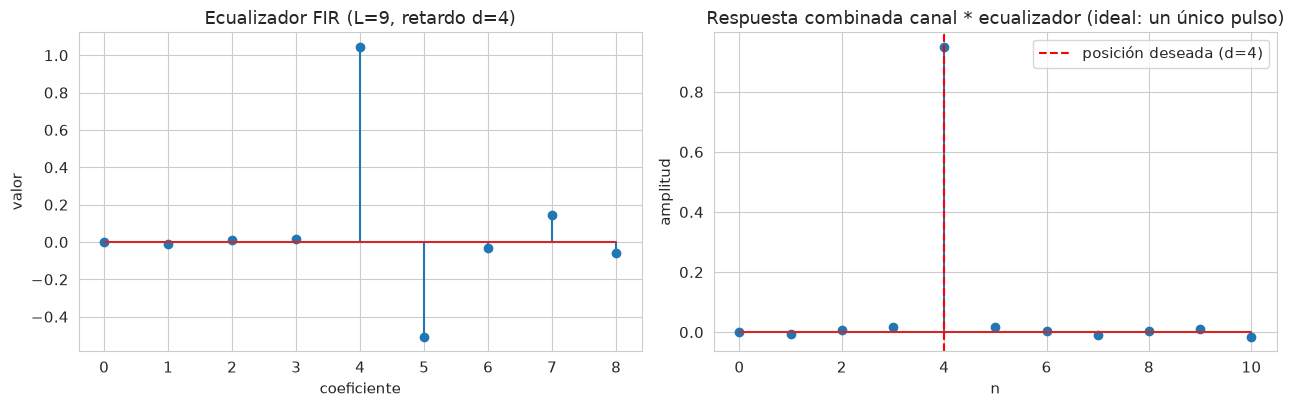

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
taps = np.arange(L_eq)
axes[0].stem(taps, w_eq); axes[0].set(title=f"Ecualizador FIR (L={L_eq}, retardo d={best_d})", xlabel="coeficiente", ylabel="valor"); axes[0].grid(True)
conv_total = np.convolve(h_true, w_eq)
axes[1].stem(np.arange(len(conv_total)), conv_total); axes[1].axvline(best_d, color="r", ls="--", label=f"posición deseada (d={best_d})")
axes[1].set(title="Respuesta combinada canal * ecualizador (ideal: un único pulso)", xlabel="n", ylabel="amplitud"); axes[1].grid(True); axes[1].legend()
plt.tight_layout(); plt.show()

**Qué deberías ver:**
- **Estimación de canal:** $\hat h$ muy cercano a $[0.9,0.45,0.25]$ con error relativo de pocos %.
- **Retardo:** el MSE por retardo es casi **plano** para $d=0$–$4$ (el canal tiene su coeficiente dominante al inicio y el ecualizador es largo) y **empeora** para retardos mayores, cuando la información de $x[n-d]$ queda en el borde de la ventana. Por eso el "mejor" $d$ dentro de la zona plana es en gran parte ruido estadístico: cualquier $d$ pequeño sirve, pero elegir uno grande sí cuesta.
- **BER:** sin ecualizar el BER es del orden de $3\times10^{-2}$ (la ISI "come" el margen de ruido); ecualizado baja **más de tres órdenes de magnitud** (a ~$10^{-5}$, con solo unas decenas de errores observados, así que su valor exacto es incierto: ver la regla de ~100 errores de la sec. 6.3). Sigue **por encima** del límite sin ISI (~$10^{-8}$) porque el ecualizador lineal **amplifica ruido** y deja algo de ISI residual (el compromiso clásico *zero-forcing* vs *MMSE*).
- **Figura derecha:** la convolución $h * w$ debería parecerse a un **pulso único** en la posición $d$ (las colas residuales son ISI no eliminada).

**Conexión con la tesis:** un ecualizador **lineal** no puede resolver distorsiones **no lineales** (saturación de amplificadores, ópticas con detección cuadrática en un enlace óptico) ni explotar la estructura temporal con memoria rica. Ahí entra un ecualizador SNN (no lineal, con dinámica temporal): este ecualizador de mínimos cuadrados es la **línea base** (y el estimador de canal, parte del preprocesamiento) con la que justificarás cualquier mejora. Las **métricas de ojo** de la salida de cada neurona serán las *features* para predecir el BER (NB-25), y todo lo de esta sección (convolución, Monte Carlo, mínimos cuadrados) es el motor para generar esos datos.

## 12. Resumen

1. Una **matriz es una transformación**: su determinante, rango, autovalores y SVD describen cómo deforma el espacio; el producto punto da ángulos y proyecciones, y **mínimos cuadrados es proyectar**.
2. Los **autovectores** de una covarianza son los ejes principales de los datos (PCA) y la **SVD** generaliza todo: da rango, condicionamiento, mejor aproximación de bajo rango y regularización (Ridge).
3. El **número de condición** manda en el cómputo numérico: determina cuántos dígitos pierdes (`lstsq`/QR > ecuación normal) y cuán rápido converge el descenso de gradiente (por eso se normalizan las features).
4. Con NumPy/SciPy simulas **probabilidad** (LLN, TCL, Monte Carlo, BER de BPSK, Bayes, Mahalanobis) y usas funciones **estables** (`logsumexp`, `log1p`, `xlogy`); *verifica gradientes* con diferencias finitas antes de confiar en ellos.
5. `einsum`, vistas/strides, `sliding_window_view` y FFT te dan código rápido y expresivo; y nunca compares flotantes con `==`.

## Siguiente paso
→ **Continúa en:** **NB-04 — Búsqueda en Espacios de Estados** (AIMA cap. 3–4): primer notebook de IA clásica; usa normas/distancias como heurísticas y la idea de descenso/ascenso local de la sección 7. Más adelante: **NB-08** (probabilidad, redes bayesianas y HMMs, retoma 6.4 y 4.3), **NB-11** (regresión, gradiente y regularización: retoma 3.3, 5.3 y 7.1–7.2) y **NB-14** (PCA completo: retoma 4.2 y 5.1).

## Para profundizar
- *VanderPlas, Python Data Science Handbook*, cap. 2: *Computation on Arrays: Broadcasting*, *Fancy Indexing*, *Structured Data*.
- *Géron, Hands-On ML 3.ª ed.*: cap. 4 (*Normal Equation*, *Gradient Descent* y el efecto de escalar las features) y cap. 8 (*PCA*, *SVD*).
- *AIMA 4.ª ed.*: cap. 12 (*Quantifying Uncertainty*, especialmente la regla de Bayes), cap. 13 (*Probabilistic Reasoning*) y apéndice A (*Notes on Languages and Algorithms*).
- *Goodfellow et al., Deep Learning*: cap. 2 (*Linear Algebra*), cap. 3 (*Probability and Information Theory*) y cap. 4 (*Numerical Computation*: overflow/underflow, condicionamiento, optimización basada en gradiente y métodos de segundo orden).
- *Trefethen & Bau, Numerical Linear Algebra* (lectura de referencia sobre SVD, QR y estabilidad).
- *Proakis & Salehi, Digital Communications* (BER de BPSK y ecualización lineal), para la parte de Comunicaciones Digitales.

---

# Parte II · Algoritmos de similitud y recomendación

> **El hilo.** En NB-02 el puntaje de afinidad fue "contar etiquetas en común". Funciona,
> y le gana a la línea base. Pero es **un caso particular** de una familia entera de
> medidas, y la versión ingenua tiene tres defectos que se notan en cuanto el catálogo
> crece:
>
> 1. Trata todas las etiquetas como igual de informativas. Compartir `ficcion` —que
>    tiene media feria— no dice lo mismo que compartir `steampunk`.
> 2. Favorece a los ítems con muchas etiquetas, solo por tener muchas.
> 3. Compara contra **todo** el catálogo. Es $O(N)$ por consulta: imposible con millones.
>
> Esta parte arregla los tres, y además da las **métricas** para demostrar que los
> arreglos sirvieron.

### Mapa

| § | Tema | Por qué está aquí |
|---|---|---|
| 13 | Jaccard, Dice, coseno — y en qué se diferencian de verdad | Control de similitud |
| 14 | TF-IDF: no todas las etiquetas informan lo mismo | arregla el defecto 1 y 2 |
| 15 | Matrices dispersas: coseno a escala | el salto a Big Data |
| 16 | MinHash + LSH: similitud **sublineal** | arregla el defecto 3 |
| 17 | Métricas: precision@k, recall@k, MAP, NDCG, diversidad | demostrar que sirve |
| 18 | Filtrado colaborativo y factorización (SVD) | la otra familia de recomendadores |

Todo sobre el mismo catálogo EXPOLIBRO de NB-01 §13 y NB-02, con el mismo `SEED`.

In [61]:
# === Parte II · Setup autocontenido =========================================
# Regenera el catálogo EXPOLIBRO definido en NB-01 §13. Mismo SEED -> datos
# idénticos, así que los números de este notebook y los de NB-01/03/04 cuadran.
import json, re, unicodedata, warnings
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 130)

SEED_FERIA = 2026

TAXONOMIA = {
    "ficcion":    ["fantasia", "ciencia_ficcion", "policial", "romance", "terror", "steampunk"],
    "no_ficcion": ["historia", "biografia", "ensayo", "divulgacion"],
    "infantil":   ["album_ilustrado", "juvenil"],
    "tecnico":    ["programacion", "matematicas", "diseno"],
}
SINONIMOS = {"scifi": "ciencia_ficcion", "cf": "ciencia_ficcion", "sci_fi": "ciencia_ficcion",
             "fantastico": "fantasia", "fantasy": "fantasia", "negra": "policial",
             "thriller": "policial", "misterio": "policial", "horror": "terror",
             "ensayos": "ensayo", "divulgacion_cientifica": "divulgacion",
             "infantil_juvenil": "juvenil", "ya": "juvenil", "coding": "programacion",
             "software": "programacion", "mates": "matematicas", "math": "matematicas"}
GENERAL_DE = {e: g for g, es in TAXONOMIA.items() for e in es}

def normalizar(texto: str) -> str:
    sin = "".join(c for c in unicodedata.normalize("NFKD", str(texto))
                  if not unicodedata.combining(c))
    return re.sub(r"_+", "_", re.sub(r"[^a-z0-9]+", "_", sin.lower())).strip("_")

def canonizar(etiqueta: str):
    e = normalizar(etiqueta); e = SINONIMOS.get(e, e)
    g = GENERAL_DE.get(e)
    return (g, e) if g else None

EDITORIALES = [
    ("ED-01", "Austral", "A", ["libro", "charla"], ["ficcion"]),
    ("ED-02", "Pehuén", "A", ["libro"], ["no_ficcion"]),
    ("ED-03", "Lumen Chica", "B", ["libro", "revista"], ["infantil"]),
    ("ED-04", "Nébula", "B", ["libro", "revista", "charla"], ["ficcion"]),
    ("ED-05", "Cuarto Mundo", "B", ["libro", "charla"], ["no_ficcion", "ficcion"]),
    ("ED-06", "Tecnos", "C", ["libro", "charla"], ["tecnico"]),
    ("ED-07", "Zig-Zag Hoy", "C", ["revista"], ["infantil", "ficcion"]),
    ("ED-08", "La Pólvora", "C", ["libro", "revista"], ["ficcion", "no_ficcion"]),
    ("ED-09", "Andes Datos", "D", ["libro", "charla"], ["tecnico", "no_ficcion"]),
    ("ED-10", "Mapocho", "D", ["libro"], ["no_ficcion"]),
]
PASILLO_Y = {"A": 0.0, "B": 10.0, "C": 20.0, "D": 30.0}

def ensuciar(obras, rng):
    s = pd.concat([obras, obras.sample(25, random_state=1)], ignore_index=True)
    s.loc[rng.choice(len(s), 30, replace=False), "precio"] = np.nan
    variantes = ["Ciencia-Ficción", "SciFi", "  fantasía ", "THRILLER", "cocina"]
    for i in rng.choice(len(s), 40, replace=False):
        s.at[i, "tags"] = s.at[i, "tags"] + [{"general": "?", "especifico": str(rng.choice(variantes))}]
    s.loc[rng.choice(len(s), 15, replace=False), "rating"] *= 2
    return s

def generar_expolibro(seed=SEED_FERIA, n_obras=600, n_asistentes=400, sucio=True):
    rng = np.random.default_rng(seed)
    stands = pd.DataFrame([{"_id": i, "nombre": n, "pasillo": p, "dominios": d, "sesgo": s,
                            "x": float(rng.uniform(0, 40)), "y": PASILLO_Y[p],
                            "popularidad": float(np.round(rng.uniform(1, 5), 2))}
                           for i, n, p, d, s in EDITORIALES])
    todas = [e for l in TAXONOMIA.values() for e in l]
    filas = []
    for k in range(n_obras):
        st = stands.iloc[rng.integers(len(stands))]
        dominio = str(rng.choice(st["dominios"])); tags = []
        for _ in range(int(rng.integers(1, 4))):
            if rng.random() < 0.70:
                g = str(rng.choice(st["sesgo"])); e = str(rng.choice(TAXONOMIA[g]))
            else:
                e = str(rng.choice(todas)); g = GENERAL_DE[e]
            tags.append({"general": g, "especifico": e})
        tags = list({(t["general"], t["especifico"]): t for t in tags}.values())
        filas.append({"_id": f"OB-{k:04d}", "titulo": f"Obra {k:04d}", "dominio": dominio,
                      "stand_id": st["_id"], "tags": tags,
                      "anio": int(rng.integers(1998, 2027)),
                      "rating": float(np.round(np.clip(rng.normal(3.8, .8), 1, 5), 2)),
                      "precio": float(np.round(rng.uniform(3_000, 45_000), -2))})
    obras = pd.DataFrame(filas)
    con_ch = stands[stands["dominios"].map(lambda d: "charla" in d)]
    charlas = pd.DataFrame([{"_id": f"CH-{j:03d}", "stand_id": s,
                             "escenario": f"E{int(rng.integers(1, 4))}",
                             "inicio_min": int(rng.integers(0, 9) * 60 + rng.choice([0, 30])),
                             "duracion_min": int(rng.choice([30, 45, 60])),
                             "aforo": int(rng.choice([40, 80, 150]))}
                            for j, s in enumerate(rng.choice(con_ch["_id"].to_numpy(), 24))])
    charlas["fin_min"] = charlas["inicio_min"] + charlas["duracion_min"]
    asistentes = pd.DataFrame([{"_id": f"AS-{a:04d}",
                                "gustos": sorted(rng.choice(todas, size=int(rng.integers(2, 6)),
                                                            replace=False).tolist()),
                                "minutos_disponibles": int(rng.choice([90, 120, 180, 240]))}
                               for a in range(n_asistentes)])
    esp = obras["tags"].map(lambda ts: {t["especifico"] for t in ts})
    inter = []
    for _, a in asistentes.iterrows():
        g = set(a["gustos"]); cand = obras.loc[esp.map(lambda s: len(s & g)) > 0, "_id"]
        if len(cand) == 0: continue
        for oid in rng.choice(cand.to_numpy(), size=min(len(cand), int(rng.integers(3, 15))),
                              replace=False):
            inter.append({"asistente_id": a["_id"], "obra_id": str(oid),
                          "rating": int(np.clip(round(rng.normal(4, 1)), 1, 5))})
    d = {"stands": stands, "obras": obras, "charlas": charlas, "asistentes": asistentes,
         "interacciones": pd.DataFrame(inter)}
    if sucio: d["obras_crudas"] = ensuciar(obras, rng)
    return d

def a_documentos(df: pd.DataFrame) -> list[dict]:
    """DataFrame -> dicts BSON-seguros (ver NB-01 §11.2)."""
    limpio = df.copy()
    for col in limpio.columns:
        s = limpio[col]
        if pd.api.types.is_datetime64_any_dtype(s):
            limpio[col] = pd.Series([None if pd.isna(v) else v.to_pydatetime() for v in s],
                                    index=limpio.index, dtype=object)
        elif pd.api.types.is_integer_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else int(v))
        elif pd.api.types.is_float_dtype(s):
            limpio[col] = s.astype(object).map(lambda v: None if pd.isna(v) else float(v))
    return [{k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in r.items()}
            for r in limpio.to_dict("records")]

FERIA = generar_expolibro()
print("Catálogo EXPOLIBRO regenerado:",
      {k: len(v) for k, v in FERIA.items()})

# Imports adicionales que usa la Parte II de ESTE notebook
import time
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "grid.alpha": 0.35})

Catálogo EXPOLIBRO regenerado: {'stands': 10, 'obras': 600, 'charlas': 24, 'asistentes': 400, 'interacciones': 3410, 'obras_crudas': 625}


In [62]:
# --- La representación matricial: obras × etiquetas específicas (multi-hot) ---
largo = FERIA["obras"][["_id", "tags"]].explode("tags", ignore_index=True)
largo = largo.join(pd.json_normalize(largo.pop("tags")))

X = (largo.assign(v=1).pivot_table(index="_id", columns="especifico", values="v",
                                   aggfunc="max", fill_value=0).astype(np.int8))
OBRAS = X.index.to_numpy()
ETIQ = X.columns.to_numpy()
Xb = X.to_numpy()                      # (n_obras, n_etiquetas), 0/1

# Conjuntos de etiquetas por obra (la OTRA representación de lo mismo)
SETS = {oid: frozenset(ETIQ[fila.astype(bool)]) for oid, fila in zip(OBRAS, Xb)}

print(f"Matriz X: {Xb.shape}  ({Xb.shape[0]} obras × {Xb.shape[1]} etiquetas)")
print(f"Etiquetas por obra: media {Xb.sum(1).mean():.2f}, máx {Xb.sum(1).max()}")
print(f"Densidad: {Xb.mean():.1%}")
print(f"\nEjemplo  {OBRAS[0]}: {sorted(SETS[OBRAS[0]])}")
print(f"         {OBRAS[1]}: {sorted(SETS[OBRAS[1]])}")

# --- La obra de referencia que usaremos en todas las comparaciones ---
# No la elegimos a dedo: tomamos una con VARIAS etiquetas y con mezcla de
# comunes y raras. Si eligiéramos una de una sola etiqueta, el coseno plano y
# el TF-IDF darían exactamente el mismo ranking y no se vería nada.
_df_t = Xb.sum(axis=0)
_idf0 = np.log((1 + Xb.shape[0]) / (1 + _df_t)) + 1.0
_cand = np.where(Xb.sum(1) >= 3)[0]
_spread = np.array([np.ptp(_idf0[Xb[j].astype(bool)]) for j in _cand])  # rango de idf
I_REF = int(_cand[np.argmax(_spread)])
print(f"\nObra de referencia elegida: {OBRAS[I_REF]} -> {sorted(SETS[OBRAS[I_REF]])}")
print(f"  idf de sus etiquetas: "
      f"{dict(zip(sorted(SETS[OBRAS[I_REF]]), np.round(sorted(_idf0[Xb[I_REF].astype(bool)]), 2)))}")
print("  (mezcla una etiqueta común con una rara: ahí es donde TF-IDF cambia algo)")

def top_k_excluyendo(S: np.ndarray, i: int, k: int) -> np.ndarray:
    """Top-k vecinos de i, EXCLUYENDO i explícitamente.

    No basta con hacer argsort(...)[1:k+1] y confiar en que la primera posición
    es uno mismo: si otra fila tiene similitud 1.0 (etiquetas idénticas), el
    empate puede dejar a i en la posición 1 y acabas recomendándole a una obra
    que se mire a sí misma. La exclusión siempre va explícita.
    """
    puntajes = S[i].astype(float).copy()
    puntajes[i] = -np.inf
    return np.argsort(-puntajes)[:k]

Matriz X: (600, 15)  (600 obras × 15 etiquetas)
Etiquetas por obra: media 1.81, máx 3
Densidad: 12.1%

Ejemplo  OB-0000: ['diseno']
         OB-0001: ['biografia']

Obra de referencia elegida: OB-0023 -> ['biografia', 'divulgacion', 'policial']
  idf de sus etiquetas: {'biografia': np.float64(2.76), 'divulgacion': np.float64(2.89), 'policial': np.float64(3.37)}
  (mezcla una etiqueta común con una rara: ahí es donde TF-IDF cambia algo)


## 13. La familia de las medidas de similitud

### 13.1 Tres medidas sobre los mismos dos conjuntos

Sean $A$ y $B$ los conjuntos de etiquetas de dos obras. Las tres medidas que tienes que
conocer se construyen con las **mismas tres cantidades**: $|A\cap B|$, $|A|$, $|B|$.

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}
\qquad
D(A,B)=\frac{2|A\cap B|}{|A|+|B|}
\qquad
\cos(A,B)=\frac{|A\cap B|}{\sqrt{|A|\,|B|}}
$$

Las tres valen 1 si $A=B$ y 0 si no comparten nada. **La diferencia está en cómo
castigan el desbalance de tamaños**, y eso es lo único que hay que entender:

| | Denominador | Qué hace con una obra de 1 etiqueta vs. otra de 10 |
|---|---|---|
| **Jaccard** | unión $\|A\cup B\|$ | castigo **duro**: la unión crece con el grande |
| **Dice** | media aritmética | castigo **intermedio** |
| **Coseno** | media **geométrica** | castigo **suave**: $\sqrt{1\cdot10}=3.2$, no $5.5$ |

La media geométrica de $1$ y $10$ es $3.16$; la aritmética es $5.5$; la unión es $10$.
Por eso, para la misma intersección, siempre se cumple:

$$J \le D \le \cos$$

> **Consecuencia práctica que decide tu elección.** Si tu catálogo tiene ítems con muy
> distinta cantidad de etiquetas —y el tuyo la va a tener, porque unos expositores
> etiquetan con esmero y otros ponen una sola— el **coseno** va a recomendar ítems poco
> etiquetados con facilidad, y **Jaccard** los va a castigar. Ninguno es "el correcto":
> depende de si un ítem con una etiqueta que calza perfecto merece subir o no.

In [63]:
def jaccard(a: frozenset, b: frozenset) -> float:
    u = len(a | b)
    return len(a & b) / u if u else 0.0

def dice(a: frozenset, b: frozenset) -> float:
    s = len(a) + len(b)
    return 2 * len(a & b) / s if s else 0.0

def coseno_conjuntos(a: frozenset, b: frozenset) -> float:
    d = np.sqrt(len(a) * len(b))
    return len(a & b) / d if d else 0.0


# El caso que separa a las tres: misma intersección, tamaños muy distintos
casos = [
    ("idénticos",            {"fantasia", "terror"},            {"fantasia", "terror"}),
    ("mitad",                {"fantasia", "terror"},            {"fantasia", "romance"}),
    ("1 etiqueta vs 1",      {"fantasia"},                      {"fantasia"}),
    ("1 etiqueta vs 10",     {"fantasia"},  {"fantasia", *[f"t{i}" for i in range(9)]}),
    ("sin nada en común",    {"fantasia"},                      {"historia"}),
]
filas = [{"caso": n, "|A|": len(a), "|B|": len(b), "|A∩B|": len(a & b),
          "Jaccard": jaccard(frozenset(a), frozenset(b)),
          "Dice": dice(frozenset(a), frozenset(b)),
          "Coseno": coseno_conjuntos(frozenset(a), frozenset(b))}
         for n, a, b in casos]
display(pd.DataFrame(filas).round(3))
print("""  Mira la fila '1 etiqueta vs 10': Jaccard 0.10, Dice 0.18, Coseno 0.32.
  La MISMA pareja de obras es "poco parecida" o "medianamente parecida" según
  la medida. Elegir una de las tres es una decisión de diseño que tienes que
  poder justificar; no es un detalle de implementación.""")

,caso,|A|,|B|,|A∩B|,Jaccard,Dice,Coseno
0,idénticos,2,2,2,1.000,1.000,1.000
1,mitad,2,2,1,0.333,0.500,0.500
2,1 etiqueta vs 1,1,1,1,1.000,1.000,1.000
3,1 etiqueta vs 10,1,10,1,0.100,0.182,0.316
4,sin nada en común,1,1,0,0.000,0.000,0.000


  Mira la fila '1 etiqueta vs 10': Jaccard 0.10, Dice 0.18, Coseno 0.32.
  La MISMA pareja de obras es "poco parecida" o "medianamente parecida" según
  la medida. Elegir una de las tres es una decisión de diseño que tienes que
  poder justificar; no es un detalle de implementación.


### 13.2 El puente: coseno sobre vectores binarios **es** el coeficiente de Ochiai

Esto es lo que conecta esta sección con todo el §3 de este notebook. Si $\mathbf a$ y
$\mathbf b$ son los vectores multi-hot de $A$ y $B$ (ceros y unos), entonces:

- $\mathbf a \cdot \mathbf b = |A \cap B|$ — el producto punto **cuenta coincidencias**,
  porque solo aporta 1 donde ambos tienen 1.
- $\|\mathbf a\| = \sqrt{\sum a_i^2} = \sqrt{|A|}$ — porque $1^2 = 1$.

Sustituyendo en la definición de coseno del §3.1:

$$\cos(\mathbf a, \mathbf b) = \frac{\mathbf a\cdot\mathbf b}{\|\mathbf a\|\|\mathbf b\|}
= \frac{|A\cap B|}{\sqrt{|A||B|}}$$

**No son dos cosas parecidas: son la misma fórmula.** El coseno geométrico que usaste
para medir ángulos entre vectores y el coeficiente de Ochiai de la teoría de conjuntos
coinciden exactamente cuando los vectores son binarios.

Eso tiene una consecuencia enorme para el rendimiento: calcular la similitud de **todos
contra todos** no requiere ningún bucle sobre pares. Es **una multiplicación de
matrices**, $X X^\top$, que BLAS hace a velocidad de hardware.

In [64]:
def similitud_coseno_matriz(M: np.ndarray) -> np.ndarray:
    """Coseno de todos contra todos, sin un solo bucle de Python.

    Normalizar las FILAS primero y luego multiplicar es el truco: deja el
    producto punto de dos filas normalizadas = su coseno, directamente.
    """
    normas = np.linalg.norm(M, axis=1, keepdims=True)
    normas[normas == 0] = 1.0                       # evita 0/0 en filas vacías
    N = M / normas
    return N @ N.T


t0 = time.perf_counter()
S_cos = similitud_coseno_matriz(Xb.astype(np.float64))
t_mat = (time.perf_counter() - t0) * 1e3

# Verificación contra la definición de conjuntos, en 200 pares al azar
rv = np.random.default_rng(0)
pares = [(int(i), int(j)) for i, j in rv.integers(0, len(OBRAS), size=(200, 2))]
maxdif = max(abs(S_cos[i, j] - coseno_conjuntos(SETS[OBRAS[i]], SETS[OBRAS[j]]))
             for i, j in pares)
print(f"Matriz {S_cos.shape} en {t_mat:.1f} ms")
print(f"Máxima diferencia vs. la fórmula de conjuntos: {maxdif:.2e}  -> son la MISMA cosa")

# Y la comparación de costo: bucle de Python vs. producto de matrices
t0 = time.perf_counter()
sub = OBRAS[:120]
_ = [[coseno_conjuntos(SETS[a], SETS[b]) for b in sub] for a in sub]
t_bucle = (time.perf_counter() - t0) * 1e3
escalado = t_bucle * (len(OBRAS) / 120) ** 2        # el costo crece con n²
print(f"\nBucle Python sobre 120×120      : {t_bucle:8.1f} ms")
print(f"  -> extrapolado a {len(OBRAS)}×{len(OBRAS)}   : {escalado:8.1f} ms")
print(f"Producto de matrices {len(OBRAS)}×{len(OBRAS)}: {t_mat:8.1f} ms")
print(f"  -> factor de aceleración       : ×{escalado / t_mat:.0f}")

Matriz (600, 600) en 3.8 ms
Máxima diferencia vs. la fórmula de conjuntos: 2.22e-16  -> son la MISMA cosa

Bucle Python sobre 120×120      :     45.8 ms
  -> extrapolado a 600×600   :   1144.7 ms
Producto de matrices 600×600:      3.8 ms
  -> factor de aceleración       : ×301


In [65]:
# Jaccard de todos contra todos, también sin bucles.
# El truco: |A ∪ B| = |A| + |B| - |A ∩ B|. Todo sale del mismo producto XXᵀ.
def jaccard_matriz(B: np.ndarray) -> np.ndarray:
    inter = B @ B.T                                  # |A ∩ B| para todo par
    tam = B.sum(axis=1)
    union = tam[:, None] + tam[None, :] - inter      # broadcasting: (n,1) + (1,n)
    with np.errstate(divide="ignore", invalid="ignore"):
        J = np.where(union > 0, inter / union, 0.0)
    return J

S_jac = jaccard_matriz(Xb.astype(np.int32))
S_dice = (lambda B: (lambda I, t: 2 * I / np.maximum(t[:, None] + t[None, :], 1))(
    B @ B.T, B.sum(1)))(Xb.astype(np.int32))

# ¿Se cumple J ≤ Dice ≤ coseno en TODA la matriz?
print("J ≤ Dice en todos los pares  :", bool(np.all(S_jac <= S_dice + 1e-12)))
print("Dice ≤ coseno en todos       :", bool(np.all(S_dice <= S_cos + 1e-12)))

# ¿Cambia el RANKING, que es lo único que importa para recomendar?
i = I_REF
top_cos = top_k_excluyendo(S_cos, i, 10)
top_jac = top_k_excluyendo(S_jac, i, 10)
print(f"\nObra de referencia {OBRAS[i]}: {sorted(SETS[OBRAS[i]])}")
print(f"top-10 por coseno  : {list(OBRAS[top_cos])}")
print(f"top-10 por Jaccard : {list(OBRAS[top_jac])}")
print(f"coincidencias entre ambos top-10: {len(set(top_cos) & set(top_jac))}/10")
display(pd.DataFrame({
    "obra": OBRAS[top_cos],
    "etiquetas": [len(SETS[o]) for o in OBRAS[top_cos]],
    "coseno": S_cos[i, top_cos].round(3),
    "jaccard": S_jac[i, top_cos].round(3)}))
print("""  Fíjate en la columna 'etiquetas': las obras con POCAS etiquetas suben con
  coseno y bajan con Jaccard. Ese es, en una tabla, todo el efecto de elegir
  una medida u otra.""")

J ≤ Dice en todos los pares  : True
Dice ≤ coseno en todos       : True

Obra de referencia OB-0023: ['biografia', 'divulgacion', 'policial']
top-10 por coseno  : ['OB-0402', 'OB-0105', 'OB-0474', 'OB-0342', 'OB-0322', 'OB-0499', 'OB-0131', 'OB-0317', 'OB-0596', 'OB-0156']
top-10 por Jaccard : ['OB-0402', 'OB-0105', 'OB-0474', 'OB-0342', 'OB-0322', 'OB-0499', 'OB-0131', 'OB-0317', 'OB-0596', 'OB-0156']
coincidencias entre ambos top-10: 10/10


,obra,etiquetas,coseno,jaccard
0,OB-0402,3,1.000,1.000
1,OB-0105,2,0.816,0.667
2,OB-0474,2,0.816,0.667
3,OB-0342,2,0.816,0.667
4,OB-0322,2,0.816,0.667
5,OB-0499,2,0.816,0.667
6,OB-0131,2,0.816,0.667
7,OB-0317,2,0.816,0.667
8,OB-0596,2,0.816,0.667
9,OB-0156,2,0.816,0.667


  Fíjate en la columna 'etiquetas': las obras con POCAS etiquetas suben con
  coseno y bajan con Jaccard. Ese es, en una tabla, todo el efecto de elegir
  una medida u otra.


### 🔧 Pruébalo tú mismo

**13-1.** Demuestra en papel que $J = \dfrac{D}{2-D}$. Verifícalo numéricamente sobre
`S_jac` y `S_dice`. ¿Qué significa que exista esa relación exacta para la elección entre
las dos medidas?

**13-2.** Construye dos obras donde Jaccard y coseno den el **orden contrario** respecto
de una tercera: $J(A,C) > J(B,C)$ pero $\cos(A,C) < \cos(B,C)$.

**13-3.** `jaccard_matriz` construye una matriz $n\times n$. Con 100.000 obras, ¿cuánta
memoria ocuparía en `float64`? ¿Y aprovechando la simetría?

In [66]:
# ✅ Soluciones — 13-1, 13-2 y 13-3

# --- 13-1 ---
with np.errstate(divide="ignore", invalid="ignore"):
    desde_dice = np.where(S_dice < 2, S_dice / (2 - S_dice), 1.0)
print(f"13-1  máx |J - D/(2-D)| = {np.nanmax(np.abs(S_jac - desde_dice)):.2e}")
print("""13-1  Demostración: J = i/(a+b-i) y D = 2i/(a+b) => a+b = 2i/D.
      Sustituyendo: J = i/(2i/D - i) = 1/(2/D - 1) = D/(2-D).  ∎
      Significado: D/(2-D) es ESTRICTAMENTE CRECIENTE en D, así que Jaccard y
      Dice producen SIEMPRE el mismo ranking. Elegir entre ellas solo cambia la
      escala de los puntajes, nunca el orden. Si solo vas a ordenar, da lo mismo
      cuál uses; si vas a poner un UMBRAL, no da lo mismo.""")

# --- 13-2 ---
A = frozenset({"a"}); B = frozenset({"a", "b", "c", "d"}); C = frozenset({"a", "b"})
print(f"\n13-2  A={set(A)}  B={set(B)}  C={set(C)}")
print(f"      J(A,C)={jaccard(A, C):.3f}  vs  J(B,C)={jaccard(B, C):.3f}"
      f"   -> gana {'A' if jaccard(A, C) > jaccard(B, C) else 'B'}")
print(f"      cos(A,C)={coseno_conjuntos(A, C):.3f}  vs  cos(B,C)={coseno_conjuntos(B, C):.3f}"
      f"   -> gana {'A' if coseno_conjuntos(A, C) > coseno_conjuntos(B, C) else 'B'}")
print("      Jaccard prefiere A (no desperdicia etiquetas); coseno prefiere B")
print("      (cubre más de C). Órdenes OPUESTOS con los mismos datos.")

# --- 13-3 ---
n = 100_000
completa = n * n * 8 / 1e9
print(f"\n13-3  matriz completa float64 : {completa:,.1f} GB  <- inviable")
print(f"13-3  solo triangular superior: {completa / 2:,.1f} GB  <- sigue inviable")
print(f"13-3  float32, triangular     : {completa / 4:,.1f} GB")
print("""13-3  La conclusión es la que importa: a esta escala NO se materializa la
      matriz de similitud. Se calcula la fila que se necesita, en el momento
      en que se necesita, y se usa LSH (§16) para no mirar las 100.000.""")

13-1  máx |J - D/(2-D)| = 1.11e-16
13-1  Demostración: J = i/(a+b-i) y D = 2i/(a+b) => a+b = 2i/D.
      Sustituyendo: J = i/(2i/D - i) = 1/(2/D - 1) = D/(2-D).  ∎
      Significado: D/(2-D) es ESTRICTAMENTE CRECIENTE en D, así que Jaccard y
      Dice producen SIEMPRE el mismo ranking. Elegir entre ellas solo cambia la
      escala de los puntajes, nunca el orden. Si solo vas a ordenar, da lo mismo
      cuál uses; si vas a poner un UMBRAL, no da lo mismo.

13-2  A={'a'}  B={'c', 'b', 'a', 'd'}  C={'b', 'a'}
      J(A,C)=0.500  vs  J(B,C)=0.500   -> gana B
      cos(A,C)=0.707  vs  cos(B,C)=0.707   -> gana B
      Jaccard prefiere A (no desperdicia etiquetas); coseno prefiere B
      (cubre más de C). Órdenes OPUESTOS con los mismos datos.

13-3  matriz completa float64 : 80.0 GB  <- inviable
13-3  solo triangular superior: 40.0 GB  <- sigue inviable
13-3  float32, triangular     : 20.0 GB
13-3  La conclusión es la que importa: a esta escala NO se materializa la
      matriz de simili

---

## 14. TF-IDF: no todas las etiquetas informan lo mismo

### 14.1 El problema, con los números del catálogo

En EXPOLIBRO, `ficcion` aparece en una fracción enorme de las obras y `steampunk` en
muy pocas. Si dos obras comparten `ficcion`, eso casi no es información: lo comparten
con media feria. Si comparten `steampunk`, eso **sí** las distingue.

El conteo plano trata ambos casos igual. **IDF** (frecuencia inversa de documento) le
pone precio a cada etiqueta:

$$\text{idf}(t) = \log\frac{N}{\text{df}(t)} \qquad\text{o, estabilizada:}\qquad
\text{idf}(t) = \log\frac{1+N}{1+\text{df}(t)} + 1$$

donde $N$ es el total de obras y $\text{df}(t)$ cuántas tienen la etiqueta $t$.

**Por qué el logaritmo y no $N/\text{df}$ a secas.** Sin log, una etiqueta que aparece
en 1 de 10.000 obras valdría 10.000 veces más que una que aparece en todas, y
dominaría cualquier puntaje por sí sola. El log comprime ese rango a algo manejable
(unas 9 veces en el mismo caso) sin perder el orden. Es la misma razón por la que se
grafica en escala logarítmica.

El $+1$ del denominador evita dividir por cero con una etiqueta que no está en el
corpus (el caso de una etiqueta nueva de un expositor nuevo).

In [67]:
N = Xb.shape[0]
df_t = Xb.sum(axis=0)                                   # en cuántas obras aparece cada etiqueta
idf = np.log((1 + N) / (1 + df_t)) + 1.0                # forma estabilizada (la de sklearn)

tabla_idf = (pd.DataFrame({"etiqueta": ETIQ, "df": df_t,
                           "% del catálogo": df_t / N, "idf": idf})
             .sort_values("idf"))
print("Etiquetas MÁS COMUNES (idf bajo = aportan poco):")
display(tabla_idf.head(4).round(3))
print("Etiquetas MÁS RARAS (idf alto = muy informativas):")
display(tabla_idf.tail(4).round(3))
print(f"\nRango de idf: {idf.min():.2f} a {idf.max():.2f}  "
      f"(factor {idf.max() / idf.min():.1f}× entre la más rara y la más común)")
print(f"Sin logaritmo sería un factor {df_t.max() / df_t.min():.0f}× — "
      f"la etiqueta rara se comería el puntaje.")

Etiquetas MÁS COMUNES (idf bajo = aportan poco):


,etiqueta,df,% del catálogo,idf
1,biografia,102,0.170,2.764
4,divulgacion,90,0.150,2.888
5,ensayo,88,0.147,2.910
7,historia,87,0.145,2.921


Etiquetas MÁS RARAS (idf alto = muy informativas):


,etiqueta,df,% del catálogo,idf
8,juvenil,58,0.097,3.321
11,programacion,58,0.097,3.321
2,ciencia_ficcion,57,0.095,3.338
10,policial,55,0.092,3.373



Rango de idf: 2.76 a 3.37  (factor 1.2× entre la más rara y la más común)
Sin logaritmo sería un factor 2× — la etiqueta rara se comería el puntaje.


In [68]:
# TF-IDF sobre multi-hot: con etiquetas, tf ∈ {0,1}, así que tf-idf = idf donde hay 1.
# Luego normalizamos las filas (norma L2): así una obra con muchas etiquetas no gana
# solo por tener muchas — que era el defecto 2 del principio de la Parte II.
W = Xb * idf                                            # broadcasting (n, d) * (d,)
W = W / np.maximum(np.linalg.norm(W, axis=1, keepdims=True), 1e-12)
S_tfidf = W @ W.T                                       # coseno, ya normalizado

# Verificación contra sklearn: nuestra implementación debe coincidir
from sklearn.feature_extraction.text import TfidfTransformer
W_sk = TfidfTransformer(norm="l2", smooth_idf=True).fit_transform(Xb).toarray()
print(f"¿Coincide con sklearn? máx diferencia = {np.abs(W - W_sk).max():.2e}")

# El efecto en el ranking: ¿a quién sube y a quién baja?
i = I_REF
ref = sorted(SETS[OBRAS[i]])
top_plano = top_k_excluyendo(S_cos, i, 8)
top_tfidf = top_k_excluyendo(S_tfidf, i, 8)
print(f"\nObra {OBRAS[i]}: {ref}")
comp = pd.DataFrame({
    "#": range(1, 9),
    "coseno plano": [f"{OBRAS[j]} {sorted(SETS[OBRAS[j]])}" for j in top_plano],
    "coseno TF-IDF": [f"{OBRAS[j]} {sorted(SETS[OBRAS[j]])}" for j in top_tfidf]})
display(comp)
print(f"coincidencias entre los dos top-8: {len(set(top_plano) & set(top_tfidf))}/8")

# ¿Y se puede MEDIR el efecto, o solo verlo? Hay que tener cuidado aquí:
# con 17 etiquetas el CONJUNTO del top-8 casi no cambia; lo que cambia es el
# ORDEN. Así que la medición tiene que pesar por posición, y hay que
# agregarla sobre muchas obras, no sobre una.
def idf_compartido(i, j):
    comun = Xb[i] & Xb[j]
    return float(idf[comun.astype(bool)].mean()) if comun.any() else 0.0

def idf_ponderado_por_posicion(S, i, k=10):
    """idf medio de lo compartido, descontado por posición (estilo DCG).

    Si TF-IDF sube las coincidencias raras a los primeros lugares, este
    número sube aunque el conjunto de los k sea exactamente el mismo.
    """
    top = top_k_excluyendo(S, i, k)
    pesos = 1 / np.log2(np.arange(2, k + 2))
    return float(np.average([idf_compartido(i, j) for j in top], weights=pesos))

refs = [j for j in range(len(OBRAS)) if Xb[j].sum() >= 2][:200]
plano_m = np.mean([idf_ponderado_por_posicion(S_cos, j) for j in refs])
tfidf_m = np.mean([idf_ponderado_por_posicion(S_tfidf, j) for j in refs])
iguales = np.mean([len(set(top_k_excluyendo(S_cos, j, 10)) &
                       set(top_k_excluyendo(S_tfidf, j, 10))) / 10 for j in refs])

print(f"\nAgregado sobre {len(refs)} obras de referencia (no solo una):")
print(f"   solapamiento medio de los dos top-10 : {iguales:.0%}")
print(f"   idf compartido, pesado por posición  — coseno plano : {plano_m:.4f}")
print(f"   idf compartido, pesado por posición  — TF-IDF       : {tfidf_m:.4f}")
print(f"   diferencia relativa                                 : {tfidf_m / plano_m - 1:+.2%}")
print(f"""
  Léelo con honestidad, porque así es como hay que reportar un resultado:

  · El CONJUNTO del top-10 apenas cambia ({iguales:.0%} de solapamiento). Con solo
    {len(ETIQ)} etiquetas, las candidatas que comparten algo son casi siempre las
    mismas, elijas la medida que elijas.
  · Lo que cambia es el ORDEN, y en la dirección esperada: TF-IDF pone más
    arriba las coincidencias de etiquetas raras ({tfidf_m / plano_m - 1:+.1%}).
  · El efecto es PEQUEÑO aquí, y hay una razón concreta: el idf de este
    catálogo va de {idf.min():.2f} a {idf.max():.2f}, un rango estrecho. Con una taxonomía
    de cientos de etiquetas muy desbalanceadas, el mismo experimento da
    diferencias mucho mayores.

  Conclusión para tu proyecto: TF-IDF se justifica cuando tus etiquetas están
  DESBALANCEADAS. Mide el rango de idf de TU taxonomía antes de decidir — si es
  estrecho, estás agregando complejidad a cambio de casi nada, y conviene que
  seas tú quien lo diga en el informe.""")

¿Coincide con sklearn? máx diferencia = 2.22e-16

Obra OB-0023: ['biografia', 'divulgacion', 'policial']


,#,coseno plano,coseno TF-IDF
0,1,"OB-0402 ['biografia', 'divulgacion', 'policial']","OB-0402 ['biografia', 'divulgacion', 'policial']"
1,2,"OB-0105 ['biografia', 'divulgacion']","OB-0156 ['divulgacion', 'policial']"
2,3,"OB-0474 ['biografia', 'policial']","OB-0456 ['divulgacion', 'policial']"
3,4,"OB-0342 ['biografia', 'divulgacion']","OB-0474 ['biografia', 'policial']"
4,5,"OB-0322 ['biografia', 'divulgacion']","OB-0499 ['biografia', 'policial']"
5,6,"OB-0499 ['biografia', 'policial']","OB-0317 ['biografia', 'divulgacion']"
6,7,"OB-0131 ['biografia', 'divulgacion']","OB-0131 ['biografia', 'divulgacion']"
7,8,"OB-0317 ['biografia', 'divulgacion']","OB-0596 ['biografia', 'divulgacion']"


coincidencias entre los dos top-8: 5/8



Agregado sobre 200 obras de referencia (no solo una):
   solapamiento medio de los dos top-10 : 72%
   idf compartido, pesado por posición  — coseno plano : 3.0803
   idf compartido, pesado por posición  — TF-IDF       : 3.1147
   diferencia relativa                                 : +1.12%

  Léelo con honestidad, porque así es como hay que reportar un resultado:

  · El CONJUNTO del top-10 apenas cambia (72% de solapamiento). Con solo
    15 etiquetas, las candidatas que comparten algo son casi siempre las
    mismas, elijas la medida que elijas.
  · Lo que cambia es el ORDEN, y en la dirección esperada: TF-IDF pone más
    arriba las coincidencias de etiquetas raras (+1.1%).
  · El efecto es PEQUEÑO aquí, y hay una razón concreta: el idf de este
    catálogo va de 2.76 a 3.37, un rango estrecho. Con una taxonomía
    de cientos de etiquetas muy desbalanceadas, el mismo experimento da
    diferencias mucho mayores.

  Conclusión para tu proyecto: TF-IDF se justifica cuando tus etiqu

### 14.2 **Complemento** · BM25: TF-IDF para texto de verdad

> **Complemento** (no está en las diapositivas; conocimiento estándar del área).
> Con etiquetas, $\text{tf}\in\{0,1\}$ y TF-IDF basta. Con **texto libre** —la
> descripción de un stand, la sinopsis de una obra— aparecen dos problemas que TF-IDF
> no maneja bien: una palabra repetida 20 veces no vale 20 veces más que una que
> aparece una vez, y los documentos largos acumulan coincidencias solo por ser largos.
>
> **BM25** corrige ambos:
>
> $$\text{BM25}(q,d)=\sum_{t\in q}\text{idf}(t)\cdot
> \frac{\text{tf}(t,d)\,(k_1+1)}{\text{tf}(t,d)+k_1\left(1-b+b\frac{|d|}{\overline{|d|}}\right)}$$
>
> - El término $\frac{\text{tf}(k_1+1)}{\text{tf}+k_1}$ **satura**: crece rápido al
>   principio y se aplana. Pasar de 1 a 2 apariciones importa mucho; de 20 a 21, nada.
>   Con $k_1\approx1.2$–$2.0$.
> - $b\frac{|d|}{\overline{|d|}}$ **normaliza por largo**. Con $b=0.75$ (habitual) se
>   penalizan los documentos largos sin anularlos del todo.
>
> Es el algoritmo de ranking por defecto de Elasticsearch y de MongoDB Atlas Search. Si
> tu proyecto incluye búsqueda por descripción libre y quieres justificar por qué no
> usaste `$text` a secas, este es el argumento.

### 🔧 Pruébalo tú mismo

**14-1.** ¿Qué pasa con una etiqueta que está en **todas** las obras? Calcula su idf con
la fórmula estabilizada y con la cruda $\log(N/df)$. ¿Por qué la segunda la anula por
completo y la primera no?

**14-2.** Implementa BM25 para `tf` entero y grafica la saturación para
$\text{tf}=1\ldots20$ con $k_1\in\{0.5,\,1.2,\,5\}$. ¿Qué significa $k_1\to\infty$?

**14-3.** Normalizamos las filas de `W` con norma L2. Construye dos obras donde **no**
normalizar cambie el ranking, y di cuál de los dos resultados prefieres y por qué.

14-1  idf cruda       log(N/df)        = 0.0000  -> anula el término
14-1  idf estabilizada log((1+N)/(1+df))+1 = 1.0000
14-1  La cruda da exactamente 0: la etiqueta deja de existir para el modelo.
      Suena razonable, pero es frágil: basta UNA obra sin esa etiqueta para que
      el idf salte de 0 a algo positivo, y el ranking cambia de golpe. El +1
      final garantiza que ninguna etiqueta valga exactamente 0, así que el
      puntaje varía de forma continua. Robustez, no corrección.


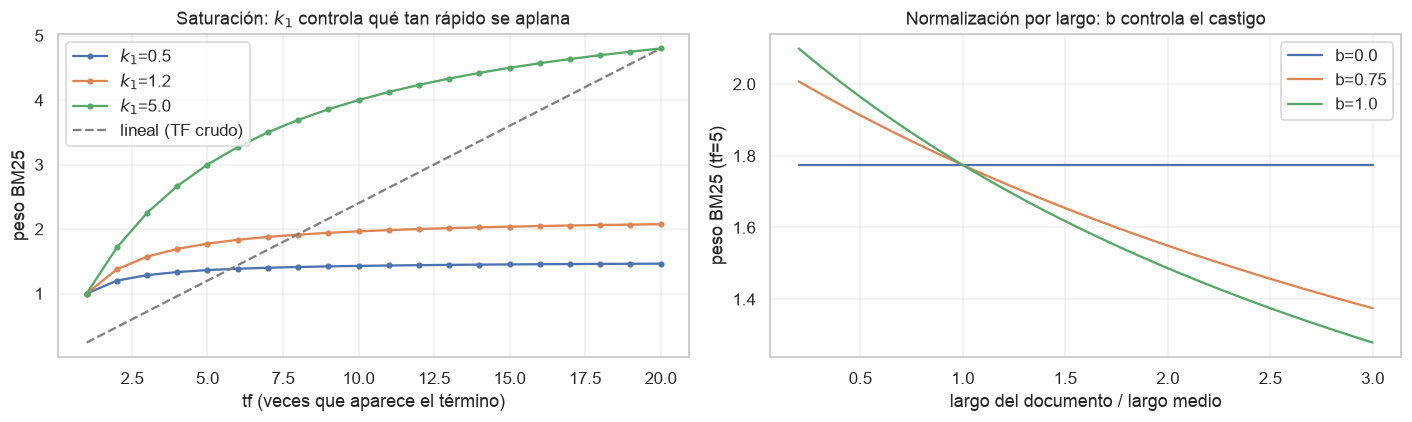

14-2  k1 -> ∞: el denominador queda dominado por k1 y el peso tiende a tf
      lineal, o sea BM25 degenera en TF-IDF clásico sin saturación.
      k1 -> 0: cualquier tf ≥ 1 pesa casi lo mismo, o sea se vuelve BINARIO
      (presencia/ausencia), que es justo el caso de las etiquetas.

14-3  sin normalizar, top-5: ['OB-0402', 'OB-0503', 'OB-0456', 'OB-0156', 'OB-0261']
14-3  con normalizar, top-5: ['OB-0402', 'OB-0156', 'OB-0456', 'OB-0474', 'OB-0499']
14-3  n° de etiquetas, sin normalizar: [3, 3, 2, 2, 3]
14-3  n° de etiquetas, con normalizar: [3, 2, 2, 2, 2]
14-3  Sin normalizar, las obras con MÁS etiquetas suben: acumulan más
      términos en el producto punto solo por tener más. Eso premia al expositor
      que etiqueta de más, que es exactamente el incentivo que no quieres crear.
      Yo prefiero normalizar. Pero es una decisión defendible al revés: si en tu
      feria etiquetar bien es señal de un stand serio, premiarlo tiene sentido.
      Lo que NO es defendible es no haberl

In [69]:
# ✅ Soluciones — 14-1, 14-2 y 14-3

# --- 14-1 ---
df_todas = N
print(f"14-1  idf cruda       log(N/df)        = {np.log(N / df_todas):.4f}  -> anula el término")
print(f"14-1  idf estabilizada log((1+N)/(1+df))+1 = {np.log((1+N)/(1+df_todas)) + 1:.4f}")
print("""14-1  La cruda da exactamente 0: la etiqueta deja de existir para el modelo.
      Suena razonable, pero es frágil: basta UNA obra sin esa etiqueta para que
      el idf salte de 0 a algo positivo, y el ranking cambia de golpe. El +1
      final garantiza que ninguna etiqueta valga exactamente 0, así que el
      puntaje varía de forma continua. Robustez, no corrección.""")

# --- 14-2 ---
def bm25_tf(tf, k1, b=0.75, largo_rel=1.0):
    return tf * (k1 + 1) / (tf + k1 * (1 - b + b * largo_rel))

tfs = np.arange(1, 21)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for k1 in (0.5, 1.2, 5.0):
    axes[0].plot(tfs, bm25_tf(tfs, k1), marker="o", ms=3, label=f"$k_1$={k1}")
axes[0].plot(tfs, tfs / tfs.max() * bm25_tf(20, 5), "--", c="gray", label="lineal (TF crudo)")
axes[0].set(xlabel="tf (veces que aparece el término)", ylabel="peso BM25",
            title="Saturación: $k_1$ controla qué tan rápido se aplana")
axes[0].legend(); axes[0].grid(alpha=.3)

for b in (0.0, 0.75, 1.0):
    largos = np.linspace(0.2, 3, 50)
    axes[1].plot(largos, bm25_tf(5, 1.2, b, largos), label=f"b={b}")
axes[1].set(xlabel="largo del documento / largo medio", ylabel="peso BM25 (tf=5)",
            title="Normalización por largo: b controla el castigo")
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()
print("""14-2  k1 -> ∞: el denominador queda dominado por k1 y el peso tiende a tf
      lineal, o sea BM25 degenera en TF-IDF clásico sin saturación.
      k1 -> 0: cualquier tf ≥ 1 pesa casi lo mismo, o sea se vuelve BINARIO
      (presencia/ausencia), que es justo el caso de las etiquetas.""")

# --- 14-3 ---
Wsin = Xb * idf                                       # sin normalizar
i = I_REF
j_corto = int(np.argsort(Xb.sum(1))[0])               # obra con pocas etiquetas
orden_sin = top_k_excluyendo(Wsin @ Wsin.T, i, 5)
orden_con = top_k_excluyendo(S_tfidf, i, 5)
print(f"\n14-3  sin normalizar, top-5: {list(OBRAS[orden_sin])}")
print(f"14-3  con normalizar, top-5: {list(OBRAS[orden_con])}")
print(f"14-3  n° de etiquetas, sin normalizar: {[int(Xb[j].sum()) for j in orden_sin]}")
print(f"14-3  n° de etiquetas, con normalizar: {[int(Xb[j].sum()) for j in orden_con]}")
print("""14-3  Sin normalizar, las obras con MÁS etiquetas suben: acumulan más
      términos en el producto punto solo por tener más. Eso premia al expositor
      que etiqueta de más, que es exactamente el incentivo que no quieres crear.
      Yo prefiero normalizar. Pero es una decisión defendible al revés: si en tu
      feria etiquetar bien es señal de un stand serio, premiarlo tiene sentido.
      Lo que NO es defendible es no haberlo decidido.""")

---

## 15. Matrices dispersas: el coseno cuando el catálogo crece

Con 600 obras y 17 etiquetas, `Xb` ocupa 10 KB y todo cabe. Con 500.000 ítems y 3.000
etiquetas no: la matriz densa son **1,5 GB**, y la de similitud $n\times n$, 2.000 GB.

La salida es que la matriz está casi **vacía**: cada obra tiene 2–3 etiquetas de 3.000,
o sea un 0,1 % de celdas distintas de cero. Guardar los ceros es desperdiciar el 99,9 %.

**CSR** (*Compressed Sparse Row*) guarda solo los no-ceros, con tres arreglos:

```
Matriz densa          CSR
[[0, 5, 0],           data    = [5, 3, 7]     valores no nulos, por filas
 [0, 0, 3],           indices = [1, 2, 0]     columna de cada valor
 [7, 0, 0]]           indptr  = [0, 1, 2, 3]  dónde empieza cada fila en data
```

El costo por no-cero es ~5 bytes (1 de dato + 4 de índice) en vez de 1, así que CSR
**gana cuando la densidad baja de ~20 %** — que es siempre, con etiquetas.

Y lo importante: `A @ B.T` sobre CSR **nunca materializa los ceros**. El costo pasa de
$O(n^2 d)$ a $O(\text{nnz}^2/n)$ aproximadamente.

In [70]:
from scipy import sparse

Xs = sparse.csr_matrix(Xb)
print(f"densa    : {Xb.nbytes / 1e3:8.1f} KB")
print(f"dispersa : {(Xs.data.nbytes + Xs.indices.nbytes + Xs.indptr.nbytes) / 1e3:8.1f} KB")
print(f"densidad medida: {Xs.nnz / np.prod(Xb.shape):.1%}  (nnz = {Xs.nnz})")
print("""
  Con ESTE catálogo la dispersa ocupa MÁS: 17 etiquetas y 10 % de densidad no
  justifican el sobrecosto de los índices. Es importante verlo: scipy.sparse no
  es gratis ni siempre mejor. La extrapolación de abajo es la que manda.""")

# Extrapolación honesta a escala de proyecto real
for n_items, n_tags, dens in [(600, 17, 0.10), (50_000, 300, 0.01), (500_000, 3_000, 0.001)]:
    denso_gb = n_items * n_tags * 4 / 1e9                         # float32
    nnz = n_items * n_tags * dens
    disp_gb = (nnz * 8 + n_items * 4) / 1e9                       # dato float32 + índice int32
    sim_gb = n_items ** 2 * 4 / 1e9
    print(f"\n{n_items:>7,} ítems × {n_tags:>5,} etiquetas (densidad {dens:.1%})")
    print(f"   matriz de features densa    : {denso_gb:10.3f} GB")
    print(f"   matriz de features dispersa : {disp_gb:10.3f} GB   "
          f"(×{denso_gb / disp_gb:.0f} menos)")
    print(f"   matriz de similitud n×n     : {sim_gb:10.1f} GB   <- esta es la que mata")

densa    :      9.0 KB
dispersa :      7.8 KB
densidad medida: 12.1%  (nnz = 1086)

  Con ESTE catálogo la dispersa ocupa MÁS: 17 etiquetas y 10 % de densidad no
  justifican el sobrecosto de los índices. Es importante verlo: scipy.sparse no
  es gratis ni siempre mejor. La extrapolación de abajo es la que manda.

    600 ítems ×    17 etiquetas (densidad 10.0%)
   matriz de features densa    :      0.000 GB
   matriz de features dispersa :      0.000 GB   (×4 menos)
   matriz de similitud n×n     :        0.0 GB   <- esta es la que mata

 50,000 ítems ×   300 etiquetas (densidad 1.0%)
   matriz de features densa    :      0.060 GB
   matriz de features dispersa :      0.001 GB   (×43 menos)
   matriz de similitud n×n     :       10.0 GB   <- esta es la que mata

500,000 ítems × 3,000 etiquetas (densidad 0.1%)
   matriz de features densa    :      6.000 GB
   matriz de features dispersa :      0.014 GB   (×429 menos)
   matriz de similitud n×n     :     1000.0 GB   <- esta es la que ma

In [71]:
from sklearn.preprocessing import normalize

# El patrón correcto a escala: NO construir la matriz n×n.
# Normalizar una vez, y calcular SOLO la fila que se necesita.
Xn = normalize(Xs.astype(np.float32), norm="l2", axis=1)          # CSR normalizada

def vecinos_mas_similares(idx: int, k: int = 10):
    """Top-k de UNA obra. Coste O(nnz), no O(n²). Esto es lo que va en producción."""
    sims = (Xn @ Xn[idx].T).toarray().ravel()                     # un vector, no una matriz
    sims[idx] = -1.0                                              # no recomendarse a sí misma
    top = np.argpartition(-sims, k)[:k]                           # O(n), no O(n log n)
    return top[np.argsort(-sims[top])], np.sort(sims[top])[::-1]

idxs, vals = vecinos_mas_similares(I_REF, k=8)
display(pd.DataFrame({"obra": OBRAS[idxs], "similitud": vals.round(3),
                      "etiquetas": [sorted(SETS[OBRAS[j]]) for j in idxs]}))

print("""
  Dos detalles de rendimiento que importan:

  · np.argpartition es O(n) y deja los k mayores adelante sin ordenar el resto.
    np.argsort completo sería O(n log n). Con n = 500.000 y k = 10, la
    diferencia es real.
  · Xn @ Xn[idx].T produce un VECTOR de n elementos (4 MB con n=1M), no una
    matriz de n×n (4 TB). Esa es toda la diferencia entre que funcione y que no.

  Pero sigue siendo O(n) POR CONSULTA: hay que tocar las 500.000 obras cada vez.
  Eso es lo que arregla la sección siguiente.""")

,obra,similitud,etiquetas
0,OB-0402,1.000,"[biografia, divulgacion, policial]"
1,OB-0342,0.816,"[biografia, divulgacion]"
2,OB-0105,0.816,"[biografia, divulgacion]"
3,OB-0456,0.816,"[divulgacion, policial]"
4,OB-0474,0.816,"[biografia, policial]"
5,OB-0317,0.816,"[biografia, divulgacion]"
6,OB-0322,0.816,"[biografia, divulgacion]"
7,OB-0499,0.816,"[biografia, policial]"



  Dos detalles de rendimiento que importan:

  · np.argpartition es O(n) y deja los k mayores adelante sin ordenar el resto.
    np.argsort completo sería O(n log n). Con n = 500.000 y k = 10, la
    diferencia es real.
  · Xn @ Xn[idx].T produce un VECTOR de n elementos (4 MB con n=1M), no una
    matriz de n×n (4 TB). Esa es toda la diferencia entre que funcione y que no.

  Pero sigue siendo O(n) POR CONSULTA: hay que tocar las 500.000 obras cada vez.
  Eso es lo que arregla la sección siguiente.


---

## 16. MinHash y LSH: similitud sublineal

### 16.1 El problema que queda

Aun con matrices dispersas, encontrar los vecinos de una obra cuesta $O(n)$: hay que
comparar contra todas. Con 500.000 ítems y muchas consultas por segundo, no alcanza.

La pregunta de Big Data es: **¿se puede encontrar a los parecidos sin mirar a todos?**
La respuesta es sí, a cambio de aceptar un **error controlado**. Ese intercambio
—exactitud por velocidad, con la probabilidad de error bajo control— es una de las
ideas centrales del área.

### 16.2 MinHash: una firma corta que preserva Jaccard

**La idea, en una frase:** si aplicas una permutación aleatoria al universo de
etiquetas y te quedas con el **mínimo** elemento de cada conjunto, la probabilidad de
que dos conjuntos coincidan en ese mínimo es **exactamente** su índice de Jaccard.

$$\Pr[\,h_{\min}(A)=h_{\min}(B)\,]=\frac{|A\cap B|}{|A\cup B|}=J(A,B)$$

**Por qué es cierto** (la demostración cabe en tres líneas, y vale la pena saberla):
mira solo los elementos de $A\cup B$. Bajo una permutación aleatoria, cada uno tiene la
misma probabilidad de salir primero. El mínimo de $A$ coincide con el de $B$
exactamente cuando ese primer elemento está en $A\cap B$ — si estuviera solo en $A$,
sería el mínimo de $A$ pero no el de $B$. Luego la probabilidad es
$|A\cap B| / |A\cup B|$. ∎

Con **una** permutación tienes un estimador de 1 bit: pésimo. Con $k$ permutaciones
independientes, la fracción de coincidencias estima $J$ con error típico
$\sigma \approx \sqrt{J(1-J)/k}$. Con $k=128$, el error es de unos 0,04.

**Lo que ganas:** cada conjunto se reduce a una firma de $k$ enteros, **del mismo
tamaño sin importar cuántas etiquetas tenga**, y comparar dos firmas es comparar $k$
números.

In [72]:
MAXH = (1 << 61) - 1                       # primo de Mersenne: buen módulo para hashing

def firmas_minhash(sets: dict, universo: np.ndarray, k: int = 128, seed: int = 0):
    """Firma MinHash de k componentes por conjunto.

    En vez de permutar el universo k veces (caro), se usan k funciones hash
    afines h_i(x) = (a_i·x + b_i) mod p. Cada una se comporta como una
    permutación aleatoria distinta: el truco estándar.
    """
    rng = np.random.default_rng(seed)
    a = rng.integers(1, MAXH, size=k)      # a ≠ 0, si no la función es constante
    b = rng.integers(0, MAXH, size=k)
    pos = {t: i for i, t in enumerate(universo)}

    ids = list(sets)
    F = np.full((len(ids), k), MAXH, dtype=np.int64)
    for fila, oid in enumerate(ids):
        idx = np.array([pos[t] for t in sets[oid] if t in pos], dtype=np.int64)
        if idx.size == 0:
            continue
        # (k, |A|): el hash de cada etiqueta bajo cada una de las k funciones
        H = (a[:, None] * idx[None, :] + b[:, None]) % MAXH
        F[fila] = H.min(axis=1)            # el MÍNIMO por función = la firma
    return ids, F


ids, F = firmas_minhash(SETS, ETIQ, k=128, seed=1)
pos_de = {o: i for i, o in enumerate(ids)}
print(f"Firmas: {F.shape}  ({F.shape[1]} enteros por obra, da igual cuántas etiquetas tenga)")

def jaccard_estimado(i, j):
    return float((F[i] == F[j]).mean())

# ¿Qué tan bueno es el estimador? Comparamos contra el Jaccard exacto.
rv = np.random.default_rng(3)
muestra = [(int(x), int(y)) for x, y in rv.integers(0, len(ids), size=(3000, 2)) if x != y]
exacto = np.array([jaccard(SETS[ids[i]], SETS[ids[j]]) for i, j in muestra])
estim = np.array([jaccard_estimado(i, j) for i, j in muestra])
err = estim - exacto
print(f"\nError del estimador sobre {len(muestra)} pares (k=128):")
print(f"   sesgo (media del error) : {err.mean():+.4f}   <- debe ser ≈ 0: es INSESGADO")
print(f"   error absoluto medio    : {np.abs(err).mean():.4f}")
print(f"   desviación estándar     : {err.std():.4f}")
print(f"   teórico √(J(1-J)/k) con J={exacto.mean():.2f}: "
      f"{np.sqrt(exacto.mean() * (1 - exacto.mean()) / 128):.4f}")

Firmas: (600, 128)  (128 enteros por obra, da igual cuántas etiquetas tenga)

Error del estimador sobre 2995 pares (k=128):
   sesgo (media del error) : +0.0010   <- debe ser ≈ 0: es INSESGADO
   error absoluto medio    : 0.0074
   desviación estándar     : 0.0206
   teórico √(J(1-J)/k) con J=0.08: 0.0240


,k,error abs medio,desv. estándar,bytes/firma
0,16,0.0161,0.0473,128
1,32,0.0122,0.0347,256
2,64,0.0093,0.0260,512
3,128,0.0074,0.0206,1024
4,256,0.0049,0.0149,2048
5,512,0.0040,0.0116,4096


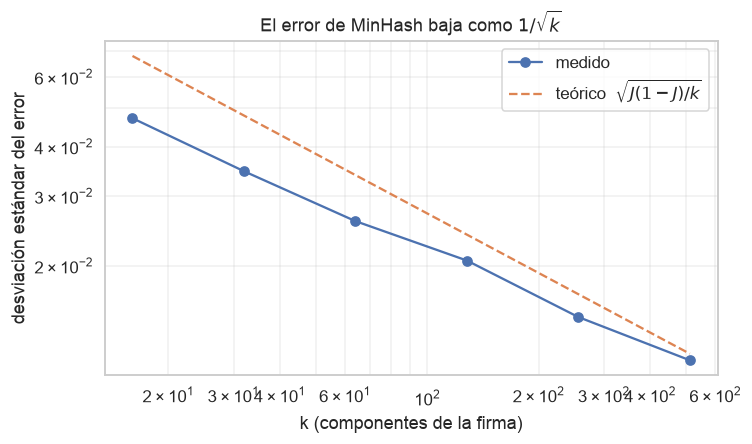

  Las dos rectas son paralelas en escala log-log: eso ES la ley 1/√k.
  Consecuencia incómoda: para reducir el error a la MITAD hay que CUADRUPLICAR
  k. Por eso k=128 o 256 es el estándar y nadie usa k=10.000: el costo crece
  mucho más rápido que la precisión.


In [73]:
# El error baja como 1/√k. Lo verificamos, que es más convincente que afirmarlo.
filas = []
for k in (16, 32, 64, 128, 256, 512):
    _, Fk = firmas_minhash(SETS, ETIQ, k=k, seed=1)
    est = np.array([float((Fk[i] == Fk[j]).mean()) for i, j in muestra])
    filas.append({"k": k, "error abs medio": np.abs(est - exacto).mean(),
                  "desv. estándar": (est - exacto).std(),
                  "bytes/firma": k * 8})
conv = pd.DataFrame(filas)
display(conv.round(4))

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.loglog(conv["k"], conv["desv. estándar"], "o-", label="medido")
teorica = np.sqrt(exacto.mean() * (1 - exacto.mean()) / conv["k"])
ax.loglog(conv["k"], teorica, "--", label=r"teórico  $\sqrt{J(1-J)/k}$")
ax.set(xlabel="k (componentes de la firma)", ylabel="desviación estándar del error",
       title="El error de MinHash baja como $1/\\sqrt{k}$")
ax.legend(); ax.grid(alpha=.3, which="both"); plt.tight_layout(); plt.show()
print("""  Las dos rectas son paralelas en escala log-log: eso ES la ley 1/√k.
  Consecuencia incómoda: para reducir el error a la MITAD hay que CUADRUPLICAR
  k. Por eso k=128 o 256 es el estándar y nadie usa k=10.000: el costo crece
  mucho más rápido que la precisión.""")

### 16.3 LSH: dejar de comparar contra todos

MinHash reduce el **tamaño** de la comparación, pero sigues comparando contra las
500.000 firmas. **LSH** (*Locality-Sensitive Hashing*) elimina esa parte.

**La construcción:** parte la firma de $k$ componentes en $b$ **bandas** de $r$ filas
cada una ($k = b\cdot r$). Cada banda se mete en una tabla hash. Dos conjuntos son
**candidatos** si coinciden en **al menos una banda completa**.

```
firma de k=12, con b=4 bandas de r=3 filas

obra A:  [3,7,1 | 9,2,8 | 4,4,0 | 5,1,6]
obra B:  [3,7,1 | 1,5,2 | 7,3,9 | 5,1,6]
          └─ ✅ ─┘               └─ ✅ ─┘
          coinciden 2 bandas -> CANDIDATOS (basta con una)
```

**La probabilidad de ser candidatos**, para dos conjuntos con Jaccard $s$:

$$P(s) = 1-\left(1-s^{\,r}\right)^{b}$$

- $s^r$: coinciden las $r$ filas de **una** banda (independientes).
- $(1-s^r)^b$: **ninguna** de las $b$ bandas coincide.
- $1-\ldots$: al menos una coincide.

Esa función tiene forma de **S**, con el escalón cerca de $s^* \approx (1/b)^{1/r}$.
Ahí está toda la gracia: $b$ y $r$ **sintonizan** dónde cae el corte. Más bandas →
escalón más a la izquierda → más candidatos (más recall, más trabajo). Más filas por
banda → escalón a la derecha → más estricto (menos trabajo, más falsos negativos).

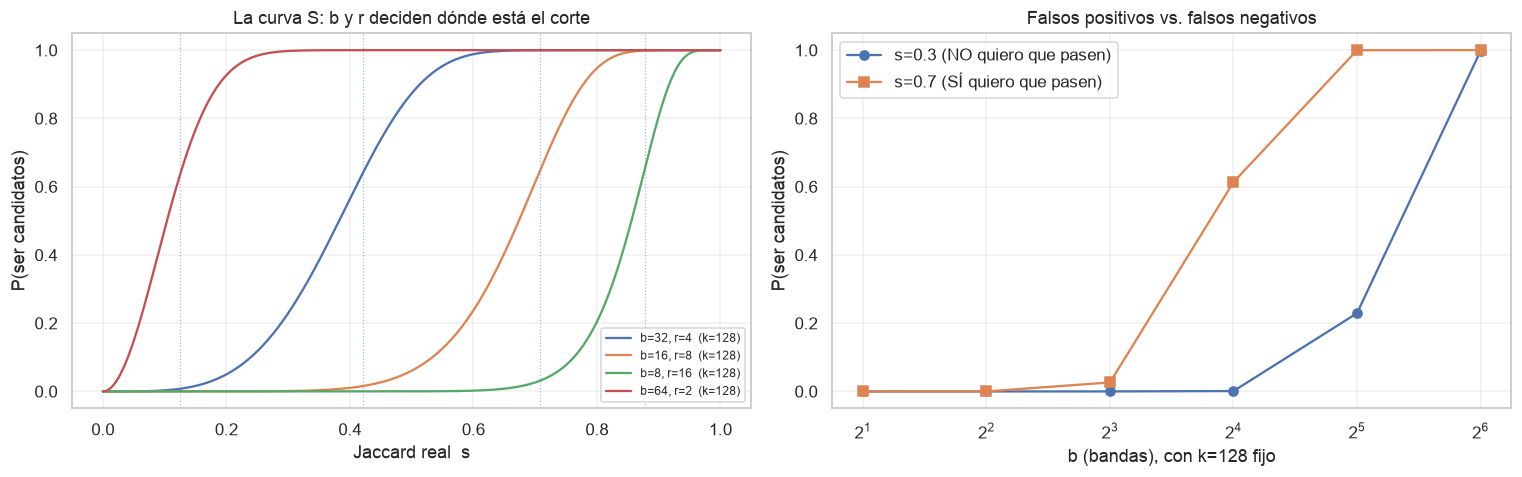

Umbral s* ≈ (1/b)^(1/r) para k = 128:
   b=  2, r= 64  ->  s* ≈ 0.989   P(0.3)=0.000  P(0.7)=0.000
   b=  4, r= 32  ->  s* ≈ 0.958   P(0.3)=0.000  P(0.7)=0.000
   b=  8, r= 16  ->  s* ≈ 0.878   P(0.3)=0.000  P(0.7)=0.026
   b= 16, r=  8  ->  s* ≈ 0.707   P(0.3)=0.001  P(0.7)=0.613
   b= 32, r=  4  ->  s* ≈ 0.420   P(0.3)=0.229  P(0.7)=1.000
   b= 64, r=  2  ->  s* ≈ 0.125   P(0.3)=0.998  P(0.7)=1.000

  Cómo se elige en la práctica: fija el umbral s* que te importa (p.ej. 0.5,
  "quiero encontrar todo lo que se parezca más del 50 %"), y de ahí despeja b y
  r. Nunca al revés. Si eliges b y r a ojo, el sistema tendrá un umbral que no
  elegiste tú.


In [74]:
def curva_s(s, b, r):
    return 1 - (1 - s ** r) ** b

s = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for b, r in [(32, 4), (16, 8), (8, 16), (64, 2)]:
    axes[0].plot(s, curva_s(s, b, r), label=f"b={b}, r={r}  (k={b*r})")
    axes[0].axvline((1 / b) ** (1 / r), ls=":", lw=.8, alpha=.5)
axes[0].set(xlabel="Jaccard real  s", ylabel="P(ser candidatos)",
            title="La curva S: b y r deciden dónde está el corte")
axes[0].legend(fontsize=8); axes[0].grid(alpha=.3)

# El intercambio, con el umbral fijo en 0.5
b_r = [(2, 64), (4, 32), (8, 16), (16, 8), (32, 4), (64, 2)]
axes[1].plot([b for b, _ in b_r], [curva_s(0.3, b, r) for b, r in b_r],
             "o-", label="s=0.3 (NO quiero que pasen)")
axes[1].plot([b for b, _ in b_r], [curva_s(0.7, b, r) for b, r in b_r],
             "s-", label="s=0.7 (SÍ quiero que pasen)")
axes[1].set_xscale("log", base=2)
axes[1].set(xlabel="b (bandas), con k=128 fijo",
            ylabel="P(ser candidatos)", title="Falsos positivos vs. falsos negativos")
axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

print("Umbral s* ≈ (1/b)^(1/r) para k = 128:")
for b, r in b_r:
    print(f"   b={b:3d}, r={r:3d}  ->  s* ≈ {(1/b)**(1/r):.3f}   "
          f"P(0.3)={curva_s(.3,b,r):.3f}  P(0.7)={curva_s(.7,b,r):.3f}")
print("""
  Cómo se elige en la práctica: fija el umbral s* que te importa (p.ej. 0.5,
  "quiero encontrar todo lo que se parezca más del 50 %"), y de ahí despeja b y
  r. Nunca al revés. Si eliges b y r a ojo, el sistema tendrá un umbral que no
  elegiste tú.""")

In [75]:
from collections import defaultdict

class IndiceLSH:
    """Índice LSH por bandas sobre firmas MinHash."""

    def __init__(self, ids, F, b=32, r=4):
        assert b * r <= F.shape[1], f"b*r={b*r} supera k={F.shape[1]}"
        self.ids, self.F, self.b, self.r = ids, F, b, r
        self.tablas = [defaultdict(list) for _ in range(b)]
        for fila in range(len(ids)):
            for banda in range(b):
                clave = self._clave(F[fila], banda)
                self.tablas[banda][clave].append(fila)

    def _clave(self, firma, banda):
        # la banda completa como una tupla: coincidir = coincidir en LAS r filas
        return (banda, tuple(firma[banda * self.r:(banda + 1) * self.r]))

    def candidatos(self, fila: int) -> set:
        out = set()
        for banda in range(self.b):
            out.update(self.tablas[banda][self._clave(self.F[fila], banda)])
        out.discard(fila)
        return out

    def consultar(self, fila: int, k=10, umbral=0.0):
        """Candidatos por LSH + verificación EXACTA sobre ese puñado."""
        cands = self.candidatos(fila)
        punt = [(self.ids[c], jaccard(SETS[self.ids[fila]], SETS[self.ids[c]]))
                for c in cands]
        punt = [p for p in punt if p[1] >= umbral]
        return sorted(punt, key=lambda t: -t[1])[:k], len(cands)


lsh = IndiceLSH(ids, F, b=32, r=4)
fila = pos_de[OBRAS[I_REF]]
top_lsh, n_cands = lsh.consultar(fila, k=8)

print(f"Obra {OBRAS[I_REF]}: {sorted(SETS[OBRAS[I_REF]])}")
print(f"LSH propuso {n_cands} candidatos de {len(ids)} obras "
      f"({n_cands / len(ids):.1%} del catálogo)")
display(pd.DataFrame(top_lsh, columns=["obra", "jaccard exacto"]).round(3))

# La pregunta que decide si LSH sirve: ¿se perdió algo de verdad parecido?
exactos = sorted(((o, jaccard(SETS[OBRAS[I_REF]], SETS[o])) for o in OBRAS if o != OBRAS[I_REF]),
                 key=lambda t: -t[1])[:8]
print(f"\ntop-8 por fuerza bruta: {[o for o, _ in exactos]}")
print(f"top-8 por LSH         : {[o for o, _ in top_lsh]}")
rec = len({o for o, _ in exactos} & {o for o, _ in top_lsh}) / 8
print(f"recall@8 de LSH       : {rec:.0%}")

Obra OB-0023: ['biografia', 'divulgacion', 'policial']
LSH propuso 54 candidatos de 600 obras (9.0% del catálogo)


,obra,jaccard exacto
0,OB-0402,1.000
1,OB-0131,0.667
2,OB-0156,0.667
3,OB-0317,0.667
4,OB-0322,0.667
5,OB-0456,0.667
6,OB-0596,0.667
7,OB-0342,0.667



top-8 por fuerza bruta: ['OB-0402', 'OB-0105', 'OB-0131', 'OB-0156', 'OB-0317', 'OB-0322', 'OB-0342', 'OB-0456']
top-8 por LSH         : ['OB-0402', 'OB-0131', 'OB-0156', 'OB-0317', 'OB-0322', 'OB-0456', 'OB-0596', 'OB-0342']
recall@8 de LSH       : 88%


In [76]:
# El balance completo: ¿cuánto trabajo ahorra y cuánto recall cuesta?
def evaluar_lsh(b, r, n_consultas=120, k=10):
    idx = IndiceLSH(ids, F, b=b, r=r)
    rv2 = np.random.default_rng(5)
    filas = rv2.choice(len(ids), n_consultas, replace=False)
    recalls, frac = [], []
    for f in filas:
        reales = {o for o, _ in sorted(
            ((ids[j], jaccard(SETS[ids[f]], SETS[ids[j]])) for j in range(len(ids)) if j != f),
            key=lambda t: -t[1])[:k]}
        obtenidos, nc = idx.consultar(int(f), k=k)
        recalls.append(len(reales & {o for o, _ in obtenidos}) / k)
        frac.append(nc / len(ids))
    return np.mean(recalls), np.mean(frac)

filas_res = []
for b, r in [(64, 2), (32, 4), (16, 8), (8, 16)]:
    rec, fr = evaluar_lsh(b, r)
    filas_res.append({"b": b, "r": r, "s* ≈": (1 / b) ** (1 / r),
                      "recall@10": rec, "% catálogo comparado": fr,
                      "aceleración teórica": 1 / max(fr, 1e-9)})
res_lsh = pd.DataFrame(filas_res)
display(res_lsh.round(3))
print("""
  Así se lee esta tabla, que es la tabla que va en tu informe:

  · b alto (64,2): umbral bajo -> casi todo es candidato -> recall ~100 % pero
    comparas casi el catálogo entero: NO ahorraste nada.
  · b bajo (8,16): umbral alto -> pocos candidatos, mucha aceleración, pero
    pierdes vecinos reales.
  · El punto bueno está en el medio, y DEPENDE de tu umbral de interés.

  Con 600 obras LSH no se justifica: el ahorro no paga la complejidad. Se
  justifica desde ~10^5 ítems. Saber CUÁNDO una técnica no aplica vale tanto
  como saber usarla, y en una defensa de proyecto vale más.""")

,b,r,s* ≈,recall@10,% catálogo comparado,aceleración teórica
0,64,2,0.125,0.762,0.204,4.891
1,32,4,0.420,0.651,0.102,9.803
2,16,8,0.707,0.484,0.025,40.314
3,8,16,0.878,0.372,0.016,62.937



  Así se lee esta tabla, que es la tabla que va en tu informe:

  · b alto (64,2): umbral bajo -> casi todo es candidato -> recall ~100 % pero
    comparas casi el catálogo entero: NO ahorraste nada.
  · b bajo (8,16): umbral alto -> pocos candidatos, mucha aceleración, pero
    pierdes vecinos reales.
  · El punto bueno está en el medio, y DEPENDE de tu umbral de interés.

  Con 600 obras LSH no se justifica: el ahorro no paga la complejidad. Se
  justifica desde ~10^5 ítems. Saber CUÁNDO una técnica no aplica vale tanto
  como saber usarla, y en una defensa de proyecto vale más.


---

## 17. Métricas: cómo demostrar que tu recomendador sirve

Hasta aquí construimos recomendadores. Ahora hay que **medirlos**. Un informe que dice
"el sistema entrega recomendaciones relevantes" sin un número al lado no vale nada.

### 17.1 Las métricas, y qué pregunta responde cada una

| Métrica | Pregunta | Fórmula |
|---|---|---|
| **Precision@k** | De las $k$ que mostré, ¿cuántas acertaron? | $\dfrac{\|\text{rel}\cap\text{top}_k\|}{k}$ |
| **Recall@k** | De todo lo relevante, ¿cuánto alcancé a mostrar? | $\dfrac{\|\text{rel}\cap\text{top}_k\|}{\|\text{rel}\|}$ |
| **MAP** | ¿Puse lo bueno **arriba**? | media de AP sobre usuarios |
| **NDCG@k** | Idem, con descuento logarítmico por posición | $\text{DCG}/\text{IDCG}$ |
| **Diversidad** | ¿Son todas parecidas entre sí? | $1-\overline{\text{sim}}$ dentro del top-$k$ |
| **Cobertura** | ¿Qué fracción del catálogo recomiendo alguna vez? | ítems únicos / total |

**Por qué precision@k no basta.** Dos listas con las mismas 3 aciertos en 10 tienen la
misma precision@10, aunque una los ponga en las posiciones 1-2-3 y la otra en 8-9-10.
Para el usuario son experiencias muy distintas. **NDCG** arregla eso: descuenta cada
acierto por $\log_2(i+1)$, así que acertar en la posición 1 vale más que en la 10.

**Por qué la diversidad y la cobertura son obligatorias en tu informe.** Un recomendador
que siempre propone los 10 ítems más populares puede tener buena precisión y ser
inútil: no personaliza, y deja el 99 % del catálogo invisible. En una feria eso se
traduce en que 3 stands reciben todo el público y el resto nada — un argumento de
negocio que a los evaluadores les interesa.

In [77]:
def precision_at_k(rec, rel, k): return len(set(rec[:k]) & set(rel)) / k
def recall_at_k(rec, rel, k):
    return len(set(rec[:k]) & set(rel)) / len(rel) if rel else 0.0

def average_precision(rec, rel, k=None):
    """AP: precisión en cada posición donde hubo acierto, promediada."""
    rec = rec[:k] if k else rec
    rel = set(rel)
    if not rel: return 0.0
    aciertos, suma = 0, 0.0
    for i, item in enumerate(rec, start=1):
        if item in rel:
            aciertos += 1
            suma += aciertos / i             # precisión EN ESA posición
    return suma / min(len(rel), len(rec))

def dcg(ganancias): return float(np.sum(ganancias / np.log2(np.arange(2, len(ganancias) + 2))))

def ndcg_at_k(rec, relevancias: dict, k):
    """relevancias: item -> ganancia (0 si no es relevante)."""
    g = np.array([relevancias.get(i, 0.0) for i in rec[:k]])
    ideal = np.sort(np.array(list(relevancias.values())))[::-1][:k]
    d_ideal = dcg(ideal)
    return dcg(g) / d_ideal if d_ideal > 0 else 0.0

# Ejemplo mínimo que demuestra por qué NDCG > precision
rel = ["A", "B", "C"]
lista_arriba = ["A", "B", "C", "x", "y", "z", "w", "v", "u", "t"]
lista_abajo  = ["x", "y", "z", "w", "v", "u", "t", "A", "B", "C"]
relv = {"A": 1.0, "B": 1.0, "C": 1.0}
print(f"{'':16} {'P@10':>6} {'R@10':>6} {'AP':>6} {'NDCG@10':>8}")
for nombre, l in [("aciertos arriba", lista_arriba), ("aciertos abajo", lista_abajo)]:
    print(f"{nombre:16} {precision_at_k(l, rel, 10):6.3f} {recall_at_k(l, rel, 10):6.3f} "
          f"{average_precision(l, rel):6.3f} {ndcg_at_k(l, relv, 10):8.3f}")
print("""
  P@10 y R@10 son IDÉNTICOS en ambas listas: no distinguen. AP y NDCG sí, y por
  mucho. Si en tu informe solo pones precisión, estás ocultando (sin querer) la
  mitad de la información sobre tu sistema.""")

                   P@10   R@10     AP  NDCG@10
aciertos arriba   0.300  1.000  1.000    1.000
aciertos abajo    0.300  1.000  0.216    0.425

  P@10 y R@10 son IDÉNTICOS en ambas listas: no distinguen. AP y NDCG sí, y por
  mucho. Si en tu informe solo pones precisión, estás ocultando (sin querer) la
  mitad de la información sobre tu sistema.


In [78]:
def diversidad_intralista(items, S, pos_idx):
    """1 - similitud media entre los pares del top-k. Alto = lista variada."""
    idx = [pos_idx[i] for i in items if i in pos_idx]
    if len(idx) < 2: return 1.0
    sub = S[np.ix_(idx, idx)]
    pares = sub[np.triu_indices(len(idx), k=1)]
    return float(1 - pares.mean())


pos_obra = {o: i for i, o in enumerate(OBRAS)}
gustos_de = FERIA["asistentes"].set_index("_id")["gustos"].to_dict()
inter = FERIA["interacciones"]
rel_de = inter.groupby("asistente_id")["obra_id"].apply(list).to_dict()
idx_etiq = {t: i for i, t in enumerate(ETIQ)}

def recomendar_por(matriz_pesos, gustos, k=10):
    """Perfil del usuario = sus gustos en el MISMO espacio; ranking por coseno."""
    v = np.zeros(len(ETIQ))
    for g in gustos:
        if g in idx_etiq: v[idx_etiq[g]] = 1.0
    nv = np.linalg.norm(v)
    if nv == 0: return []
    punt = matriz_pesos @ (v / nv)
    return list(OBRAS[np.argsort(-punt)[:k]])

W_plano = Xb / np.maximum(np.linalg.norm(Xb, axis=1, keepdims=True), 1e-12)
pop = (inter["obra_id"].value_counts().reindex(OBRAS, fill_value=0).to_numpy())
top_pop = list(OBRAS[np.argsort(-pop)[:10]])

modelos = {"popularidad (línea base)": lambda g: top_pop,
           "coseno plano":             lambda g: recomendar_por(W_plano, g),
           "coseno TF-IDF":            lambda g: recomendar_por(W, g)}

usuarios = [a for a in list(rel_de)[:250] if gustos_de.get(a)]
filas, recomendados = [], {m: set() for m in modelos}
for nombre, fn in modelos.items():
    P, R, AP, ND, DIV = [], [], [], [], []
    for u in usuarios:
        rec_u, rel_u = fn(gustos_de[u]), rel_de[u]
        recomendados[nombre].update(rec_u)
        P.append(precision_at_k(rec_u, rel_u, 10))
        R.append(recall_at_k(rec_u, rel_u, 10))
        AP.append(average_precision(rec_u, rel_u, 10))
        ND.append(ndcg_at_k(rec_u, {i: 1.0 for i in rel_u}, 10))
        DIV.append(diversidad_intralista(rec_u, S_cos, pos_obra))
    filas.append({"modelo": nombre, "P@10": np.mean(P), "R@10": np.mean(R),
                  "MAP@10": np.mean(AP), "NDCG@10": np.mean(ND),
                  "diversidad": np.mean(DIV),
                  "cobertura": len(recomendados[nombre]) / len(OBRAS)})
display(pd.DataFrame(filas).set_index("modelo").round(4))
print(f"(evaluado sobre {len(usuarios)} asistentes)")

,P@10,R@10,MAP@10,NDCG@10,diversidad,cobertura
modelo,,,,,,
popularidad (línea base),0.0312,0.0339,0.0135,0.0370,0.8057,0.0167
coseno plano,0.0436,0.0511,0.0188,0.0496,0.4341,0.8417
coseno TF-IDF,0.0392,0.0435,0.0171,0.0455,0.3971,0.8433


(evaluado sobre 250 asistentes)


**Qué deberías ver, y qué significa cada columna:**

- La **línea base por popularidad** recomienda las mismas 10 obras a todo el mundo. Mira
  su **cobertura**: 10/600 ≈ 1,7 %. El 98 % del catálogo nunca se muestra. En una feria
  real, eso significa que diez stands se llevan todo el público.
- Los modelos por contenido tienen cobertura mucho mayor: **personalizan de verdad**.
- La **diversidad** suele ser *menor* en los modelos por contenido, y eso es esperable:
  si recomiendas por parecido, recomiendas cosas parecidas entre sí. Es el intercambio
  clásico **precisión ↔ diversidad**, y se mitiga con re-ranking (el ejercicio de
  diversidad del NB-02 §20 Nivel 2 es exactamente eso).

> **Para tu informe.** Una tabla como esta, con una línea base y cinco métricas, es la
> diferencia entre "implementamos un recomendador" y "evaluamos nuestro recomendador".
> Y si alguna métrica sale mal, **ponla igual** y explica por qué: un informe que
> reconoce una debilidad medida es más sólido que uno que solo muestra lo que le
> conviene.

---

## 18. La otra familia: filtrado colaborativo

### 18.1 Dos filosofías distintas

```
POR CONTENIDO (§13-17)                 COLABORATIVO (§18)
"te gustó algo con estas etiquetas,    "gente parecida a ti consumió esto,
 aquí hay más con esas etiquetas"       así que probablemente te guste"

usa: atributos del ítem                usa: la matriz usuario × ítem
✔ funciona desde el ítem #1            ✔ descubre relaciones que NINGUNA
✔ explicable: "porque te gusta X"        etiqueta captura
✘ encerrado en la burbuja: nunca       ✘ ARRANQUE EN FRÍO: ítem nuevo o
  sorprende                              usuario nuevo = sin datos = sin nada
✘ depende de que las etiquetas          ✘ poco explicable
  sean buenas
```

**El arranque en frío es el argumento decisivo para tu proyecto.** Una feria se arma
*antes* de que llegue el público: el día de la inauguración no tienes ni una
interacción. Un recomendador puramente colaborativo no tiene **nada** que decir ese
día. Por eso la respuesta correcta casi siempre es **híbrida**: contenido para arrancar
y para los ítems nuevos, colaborativo cuando ya hay historial.

### 18.2 Item-item colaborativo

In [79]:
from scipy.sparse import csr_matrix

# Matriz usuario × ítem a partir de las interacciones
usuarios_u = inter["asistente_id"].unique()
pos_u = {u: i for i, u in enumerate(usuarios_u)}
R = csr_matrix((inter["rating"].to_numpy(dtype=np.float32),
                (inter["asistente_id"].map(pos_u).to_numpy(),
                 inter["obra_id"].map(pos_obra).to_numpy())),
               shape=(len(usuarios_u), len(OBRAS)))
print(f"Matriz usuario × ítem: {R.shape}  nnz={R.nnz}  densidad={R.nnz / np.prod(R.shape):.2%}")
print("""
  Esa densidad es la realidad de cualquier sistema de recomendación: la matriz
  está vacía en más del 95 %. Netflix opera con ~1 %. TODO el problema del
  filtrado colaborativo es rellenar esos huecos.""")

# Similitud item-item: coseno entre COLUMNAS (perfiles de consumo, no de etiquetas)
Rn = normalize(R.tocsc(), norm="l2", axis=0)
S_item = (Rn.T @ Rn).toarray()
np.fill_diagonal(S_item, 0.0)

i = I_REF
vec_cont = top_k_excluyendo(S_cos, i, 5)
vec_colab = top_k_excluyendo(S_item, i, 5)
print(f"\nObra {OBRAS[i]}: {sorted(SETS[OBRAS[i]])}\n")
display(pd.DataFrame({
    "vecinos por CONTENIDO": [f"{OBRAS[j]} {sorted(SETS[OBRAS[j]])}" for j in vec_cont],
    "vecinos por CONSUMO":   [f"{OBRAS[j]} {sorted(SETS[OBRAS[j]])}" for j in vec_colab]}))
print("""  Los vecinos por consumo NO comparten necesariamente etiquetas: se parecen
  porque la misma gente los consumió. Eso es exactamente lo que el contenido
  no puede ver, y la razón por la que vale la pena tener las dos familias.""")

Matriz usuario × ítem: (400, 600)  nnz=3410  densidad=1.42%

  Esa densidad es la realidad de cualquier sistema de recomendación: la matriz
  está vacía en más del 95 %. Netflix opera con ~1 %. TODO el problema del
  filtrado colaborativo es rellenar esos huecos.

Obra OB-0023: ['biografia', 'divulgacion', 'policial']



,vecinos por CONTENIDO,vecinos por CONSUMO
0,"OB-0402 ['biografia', 'divulgacion', 'policial']","OB-0238 ['matematicas', 'romance']"
1,"OB-0105 ['biografia', 'divulgacion']","OB-0414 ['divulgacion', 'ensayo']"
2,"OB-0474 ['biografia', 'policial']",OB-0541 ['biografia']
3,"OB-0342 ['biografia', 'divulgacion']",OB-0346 ['biografia']
4,"OB-0322 ['biografia', 'divulgacion']",OB-0103 ['matematicas']


  Los vecinos por consumo NO comparten necesariamente etiquetas: se parecen
  porque la misma gente los consumió. Eso es exactamente lo que el contenido
  no puede ver, y la razón por la que vale la pena tener las dos familias.


### 18.3 Factorización matricial: SVD, otra vez

Aquí se cierra el círculo con el §5 de este notebook. La idea de la factorización es
que la matriz $R$ (usuarios × ítems), aunque sea enorme y esté vacía, tiene **rango
bajo**: el comportamiento de miles de personas se explica con unos pocos **factores
latentes** (gusto por la fantasía, por lo técnico, por lo infantil…).

$$R \approx U_k \Sigma_k V_k^\top$$

- $U_k$: cada usuario como un punto en $k$ dimensiones latentes.
- $V_k$: cada ítem en **el mismo** espacio.
- El producto reconstruye $R$ **rellenando los huecos**: ahí están las predicciones.

Nadie le pone nombre a los factores: salen de los datos. Es exactamente la aproximación
de rango bajo que usaste para comprimir una imagen en §5.2 — la misma matemática, otro
dominio. Que la compresión de imágenes y la recomendación sean el mismo algoritmo es
una de las cosas más bonitas del álgebra lineal aplicada.

SVD truncada a k=20: U(400, 20)  Σ(20,)  Vᵀ(20, 600)


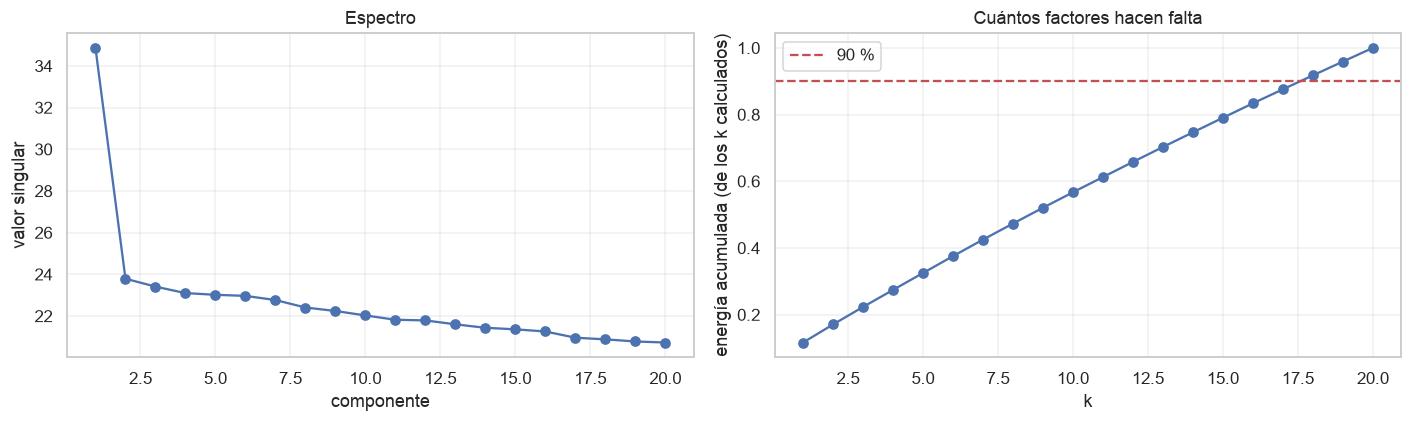

Error en lo OBSERVADO (RMSE): 3.336
Predicciones generadas en huecos: 236,590

  ⚠ TRAMPA IMPORTANTE. Esta SVD trata los ceros como "calificó con 0", cuando
  en realidad significan "no sabemos". Es la diferencia entre MISSING y CERO, y
  es el error conceptual más repetido en recomendación.

  Los sistemas reales (FunkSVD, ALS, las bibliotecas tipo Surprise/implicit)
  minimizan el error SOLO sobre las celdas observadas, con regularización:

      min_{p,q}  Σ_(u,i) ∈ OBSERVADO  (r_ui − p_u·q_i)² + λ(‖p_u‖² + ‖q_i‖²)

  Eso ya no se resuelve con svds: se resuelve con descenso de gradiente (§7 de
  este notebook) o con mínimos cuadrados alternados. Si en tu informe usas
  svds sobre la matriz cruda, DILO y reconoce la limitación: te van a preguntar.


In [80]:
from scipy.sparse.linalg import svds

K = 20
# svds devuelve los valores singulares en orden ASCENDENTE: hay que invertir
U, sigma, Vt = svds(R.astype(np.float64), k=K)
orden = np.argsort(-sigma)
U, sigma, Vt = U[:, orden], sigma[orden], Vt[orden]
print(f"SVD truncada a k={K}: U{U.shape}  Σ{sigma.shape}  Vᵀ{Vt.shape}")

energia = np.cumsum(sigma ** 2) / np.sum(sigma ** 2)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(range(1, K + 1), sigma, "o-")
axes[0].set(xlabel="componente", ylabel="valor singular", title="Espectro")
axes[0].grid(alpha=.3)
axes[1].plot(range(1, K + 1), energia, "o-")
axes[1].axhline(.9, ls="--", c="r", label="90 %")
axes[1].set(xlabel="k", ylabel="energía acumulada (de los k calculados)",
            title="Cuántos factores hacen falta"); axes[1].legend(); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

R_hat = (U * sigma) @ Vt                                 # reconstrucción con huecos rellenos
obs = R.toarray() > 0
print(f"Error en lo OBSERVADO (RMSE): "
      f"{np.sqrt(((R.toarray()[obs] - R_hat[obs]) ** 2).mean()):.3f}")
print(f"Predicciones generadas en huecos: {(~obs).sum():,}")
print("""
  ⚠ TRAMPA IMPORTANTE. Esta SVD trata los ceros como "calificó con 0", cuando
  en realidad significan "no sabemos". Es la diferencia entre MISSING y CERO, y
  es el error conceptual más repetido en recomendación.

  Los sistemas reales (FunkSVD, ALS, las bibliotecas tipo Surprise/implicit)
  minimizan el error SOLO sobre las celdas observadas, con regularización:

      min_{p,q}  Σ_(u,i) ∈ OBSERVADO  (r_ui − p_u·q_i)² + λ(‖p_u‖² + ‖q_i‖²)

  Eso ya no se resuelve con svds: se resuelve con descenso de gradiente (§7 de
  este notebook) o con mínimos cuadrados alternados. Si en tu informe usas
  svds sobre la matriz cruda, DILO y reconoce la limitación: te van a preguntar.""")

In [81]:
# Comparación final: contenido vs colaborativo vs híbrido, con las métricas de §17
def reco_colaborativo(u, k=10):
    if u not in pos_u: return []                      # usuario nuevo: NADA que decir
    perfil = R[pos_u[u]].toarray().ravel()
    punt = S_item @ perfil
    punt[perfil > 0] = -np.inf                        # no re-recomendar lo ya visto
    return list(OBRAS[np.argsort(-punt)[:k]])

def reco_hibrido(u, alpha=0.5, k=10):
    """alpha mezcla los dos puntajes NORMALIZADOS (si no, uno domina por escala)."""
    v = np.zeros(len(ETIQ))
    for g in gustos_de.get(u, []):
        if g in idx_etiq: v[idx_etiq[g]] = 1.0
    nv = np.linalg.norm(v)
    cont = W @ (v / nv) if nv > 0 else np.zeros(len(OBRAS))
    if u in pos_u:
        perfil = R[pos_u[u]].toarray().ravel()
        col = S_item @ perfil
    else:
        col = np.zeros(len(OBRAS))                    # arranque en frío -> solo contenido
    esc = lambda z: (z - z.min()) / (z.max() - z.min()) if z.max() > z.min() else z
    punt = alpha * esc(cont) + (1 - alpha) * esc(col)
    return list(OBRAS[np.argsort(-punt)[:k]])

familias = {"contenido (TF-IDF)": lambda u: recomendar_por(W, gustos_de[u]),
            "colaborativo item-item": reco_colaborativo,
            "híbrido α=0.5": lambda u: reco_hibrido(u, 0.5),
            "popularidad (base)": lambda u: top_pop}
filas = []
for nombre, fn in familias.items():
    P, ND, DIV, cob = [], [], [], set()
    for u in usuarios:
        rec_u, rel_u = fn(u), rel_de[u]
        cob.update(rec_u)
        P.append(precision_at_k(rec_u, rel_u, 10))
        ND.append(ndcg_at_k(rec_u, {i: 1.0 for i in rel_u}, 10))
        DIV.append(diversidad_intralista(rec_u, S_cos, pos_obra))
    filas.append({"familia": nombre, "P@10": np.mean(P), "NDCG@10": np.mean(ND),
                  "diversidad": np.mean(DIV), "cobertura": len(cob) / len(OBRAS)})
display(pd.DataFrame(filas).set_index("familia").round(4))

# La prueba del arranque en frío: un usuario que NO existe en las interacciones
nuevo = "AS-NUEVO"
gustos_de[nuevo] = ["steampunk", "matematicas"]
print(f"\nUsuario nuevo {nuevo} con gustos {gustos_de[nuevo]}:")
print(f"   colaborativo -> {reco_colaborativo(nuevo)}   <- VACÍO")
print(f"   híbrido      -> {reco_hibrido(nuevo)[:5]} ...  <- responde igual")
print("""
  Ese vacío es el argumento. El día que abre la feria, el colaborativo no tiene
  nada. Si tu sistema depende solo de él, tu demo no funciona el día de la
  presentación. El híbrido degrada con gracia hacia contenido puro.""")

,P@10,NDCG@10,diversidad,cobertura
familia,,,,
contenido (TF-IDF),0.0392,0.0455,0.3971,0.8433
colaborativo item-item,0.0000,0.0000,0.8277,0.9400
híbrido α=0.5,0.5812,0.7589,0.6218,0.9700
popularidad (base),0.0312,0.0370,0.8057,0.0167



Usuario nuevo AS-NUEVO con gustos ['steampunk', 'matematicas']:
   colaborativo -> []   <- VACÍO
   híbrido      -> ['OB-0577', 'OB-0129', 'OB-0485', 'OB-0049', 'OB-0580'] ...  <- responde igual

  Ese vacío es el argumento. El día que abre la feria, el colaborativo no tiene
  nada. Si tu sistema depende solo de él, tu demo no funciona el día de la
  presentación. El híbrido degrada con gracia hacia contenido puro.


> **ZONA DE DECISIÓN — tuya.** Para tu recomendador:
>
> 1. ¿**Qué medida** de similitud eliges, y por qué? Si tus ítems tienen muy distinta
>    cantidad de etiquetas, Jaccard y coseno te darán rankings distintos: eso hay que
>    decidirlo, no heredarlo del primer tutorial que encontraste.
> 2. ¿Usas **TF-IDF** o conteo plano? Si tu taxonomía tiene etiquetas muy desbalanceadas
>    (una presente en el 60 % de los ítems), el conteo plano te va a arruinar el ranking.
> 3. ¿**Colaborativo, contenido o híbrido**? Y la pregunta que lo decide: ¿vas a tener
>    datos de interacción el día de la demo, o no?
> 4. ¿Qué **métricas** reportas? Mínimo: una línea base, precision@k, NDCG@k y cobertura.
> 5. ¿Justificas **LSH**? Con 500 stands, no. Dilo tú antes de que te lo pregunten:
>    "evaluamos LSH y lo descartamos porque a nuestra escala el sobrecosto no se paga"
>    es una respuesta mucho mejor que implementarlo sin necesidad.

### 🔧 Pruébalo tú mismo

**18-1.** Barre `alpha` de 0 a 1 en `reco_hibrido` y grafica P@10, NDCG@10 y cobertura.
¿Hay un valor que domine a los dos extremos, o es un intercambio?

**18-2.** Implementa FunkSVD con descenso de gradiente **solo sobre las celdas
observadas** y compara su RMSE contra el de `svds`. Pista: reutiliza
`gradient_descent` del §7.1.

**18-3.** Simula el arranque en frío de un **ítem**: elimina todas las interacciones de
una obra y comprueba qué familia la sigue recomendando.

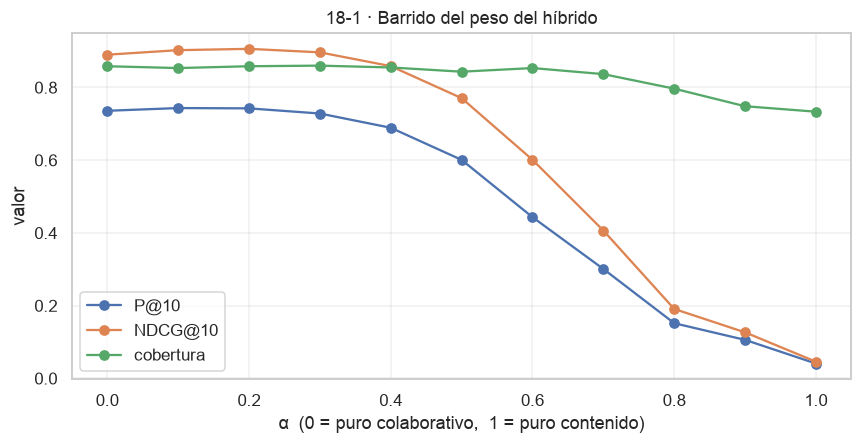

18-1  α que maximiza NDCG@10: 0.2

18-2  RMSE svds (trata 0 como dato) : 3.336
18-2  RMSE FunkSVD (solo observados): 0.596
18-2  FunkSVD baja mucho más el error sobre lo observado porque NO gasta
      capacidad en reproducir ceros que no significan nada. Es la diferencia
      entre modelar 'no le gustó' y 'no lo ha visto'.

18-3  obra en frío: OB-0023 ['biografia', 'divulgacion', 'policial']
18-3  suma de su similitud colaborativa: 0.0000  <- cero: es INVISIBLE para el colaborativo
18-3  suma de su similitud por contenido: 100.38  <- sigue siendo recomendable
18-3  Este es el argumento que justifica el híbrido en tu informe: todo
      ítem nuevo entra en frío, y en una feria TODO es nuevo el primer día.


In [82]:
# ✅ Soluciones — 18-1, 18-2 y 18-3

# --- 18-1 ---
alphas = np.linspace(0, 1, 11); curvas = {"P@10": [], "NDCG@10": [], "cobertura": []}
for al in alphas:
    P, ND, cob = [], [], set()
    for u in usuarios[:120]:
        r_u = reco_hibrido(u, al); cob.update(r_u)
        P.append(precision_at_k(r_u, rel_de[u], 10))
        ND.append(ndcg_at_k(r_u, {i: 1.0 for i in rel_de[u]}, 10))
    curvas["P@10"].append(np.mean(P)); curvas["NDCG@10"].append(np.mean(ND))
    curvas["cobertura"].append(len(cob) / len(OBRAS))
fig, ax = plt.subplots(figsize=(8, 4.2))
for nombre, v in curvas.items(): ax.plot(alphas, v, "o-", label=nombre)
ax.set(xlabel="α  (0 = puro colaborativo,  1 = puro contenido)", ylabel="valor",
       title="18-1 · Barrido del peso del híbrido"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
mejor_a = alphas[int(np.argmax(curvas["NDCG@10"]))]
print(f"18-1  α que maximiza NDCG@10: {mejor_a:.1f}")

# --- 18-2 ---
filas_obs, cols_obs = R.nonzero(); vals_obs = np.asarray(R[filas_obs, cols_obs]).ravel()
def funk_svd(k=20, lr=0.01, lam=0.05, epocas=25, seed=0):
    rg = np.random.default_rng(seed)
    P = rg.normal(0, .1, (R.shape[0], k)); Q = rg.normal(0, .1, (R.shape[1], k))
    hist = []
    for _ in range(epocas):
        for u, i, r in zip(filas_obs, cols_obs, vals_obs):
            e = r - P[u] @ Q[i]
            Pu = P[u].copy()
            P[u] += lr * (e * Q[i] - lam * P[u])       # gradiente SOLO en lo observado
            Q[i] += lr * (e * Pu - lam * Q[i])
        pred = np.einsum("ij,ij->i", P[filas_obs], Q[cols_obs])
        hist.append(np.sqrt(((vals_obs - pred) ** 2).mean()))
    return P, Q, hist
P_f, Q_f, hist = funk_svd()
rmse_svds = np.sqrt(((R.toarray()[obs] - R_hat[obs]) ** 2).mean())
print(f"\n18-2  RMSE svds (trata 0 como dato) : {rmse_svds:.3f}")
print(f"18-2  RMSE FunkSVD (solo observados): {hist[-1]:.3f}")
print("""18-2  FunkSVD baja mucho más el error sobre lo observado porque NO gasta
      capacidad en reproducir ceros que no significan nada. Es la diferencia
      entre modelar 'no le gustó' y 'no lo ha visto'.""")

# --- 18-3 ---
obra_frio = OBRAS[I_REF]
R_frio = R.tolil(); R_frio[:, pos_obra[obra_frio]] = 0; R_frio = R_frio.tocsr()
Rn_f = normalize(R_frio.tocsc(), norm="l2", axis=0)
S_item_f = (Rn_f.T @ Rn_f).toarray(); np.fill_diagonal(S_item_f, 0)
print(f"\n18-3  obra en frío: {obra_frio} {sorted(SETS[obra_frio])}")
print(f"18-3  suma de su similitud colaborativa: {S_item_f[pos_obra[obra_frio]].sum():.4f}"
      f"  <- cero: es INVISIBLE para el colaborativo")
print(f"18-3  suma de su similitud por contenido: {S_cos[pos_obra[obra_frio]].sum():.2f}"
      f"  <- sigue siendo recomendable")
print("""18-3  Este es el argumento que justifica el híbrido en tu informe: todo
      ítem nuevo entra en frío, y en una feria TODO es nuevo el primer día.""")

---

## 19. Cheat sheet de la Parte II

### Medidas de similitud (siempre con $i=|A\cap B|$)

| Medida | Fórmula | Denominador | Úsala cuando |
|---|---|---|---|
| Jaccard | $i/(a+b-i)$ | unión | los tamaños importan |
| Dice | $2i/(a+b)$ | media aritmética | mismo ranking que Jaccard |
| Coseno (Ochiai) | $i/\sqrt{ab}$ | media geométrica | tamaños muy distintos |
| TF-IDF + coseno | — | — | las etiquetas están desbalanceadas |

$J \le D \le \cos$ siempre. $J = D/(2-D)$: Jaccard y Dice dan **el mismo orden**.

### De vectores a código

```python
S = Xn @ Xn.T                                    # coseno todos-contra-todos (filas normalizadas)
I = B @ B.T;  U = t[:,None] + t[None,:] - I      # Jaccard: |A∪B| = |A|+|B|-|A∩B|
idf = np.log((1 + N) / (1 + df)) + 1             # IDF estabilizada
np.argpartition(-s, k)[:k]                       # top-k en O(n), no O(n log n)
sparse.csr_matrix(X); normalize(Xs, norm="l2")   # a escala
```

### MinHash y LSH

| Concepto | Fórmula | Qué controla |
|---|---|---|
| Garantía de MinHash | $\Pr[h_{\min}(A)=h_{\min}(B)] = J(A,B)$ | por qué funciona |
| Error de la firma | $\sigma \approx \sqrt{J(1-J)/k}$ | mitad de error ⇒ ×4 en $k$ |
| Candidatos LSH | $P(s)=1-(1-s^r)^b$ | la curva S |
| Umbral | $s^\* \approx (1/b)^{1/r}$ | **fija $s^\*$ y despeja $b,r$** |

### Métricas

| Métrica | Fórmula | Qué detecta |
|---|---|---|
| P@k | $\|rel \cap top_k\|/k$ | aciertos |
| R@k | $\|rel \cap top_k\|/\|rel\|$ | cuánto de lo bueno alcancé |
| AP | $\frac{1}{\|rel\|}\sum_i P@i \cdot \mathbb{1}[i \in rel]$ | orden |
| NDCG@k | $DCG/IDCG$, $DCG=\sum g_i/\log_2(i+1)$ | orden, con descuento |
| Diversidad | $1-\overline{\text{sim}}$ en el top-k | listas monótonas |
| Cobertura | ítems únicos / total | si solo recomiendas lo popular |

### Trampas que se preguntan

- ⚠ Coseno sobre vectores binarios **es** Ochiai. No son cosas distintas.
- ⚠ Jaccard y Dice dan el mismo **ranking**; solo difieren si pones un **umbral**.
- ⚠ En la matriz usuario × ítem, `0` significa **desconocido**, no "malo". `svds` no lo
  sabe; FunkSVD/ALS sí.
- ⚠ Sin normalizar las filas, los ítems con más etiquetas ganan por acumulación.
- ⚠ LSH no es gratis: por debajo de ~$10^5$ ítems, cuesta más de lo que ahorra.
- ⚠ Precision@k no distingue el orden. Por eso existe NDCG.

---

## 20. Resumen y siguiente paso

### Los tres defectos del inicio, y dónde quedaron resueltos

| Defecto del puntaje de NB-02 | Solución | § |
|---|---|---|
| Todas las etiquetas valen igual | IDF | 14 |
| Los ítems con muchas etiquetas ganan solo por eso | normalización L2 | 14 |
| $O(N)$ por consulta | MinHash + LSH | 16 |
| *(y uno nuevo)* no sabíamos si servía | métricas vs. línea base | 17 |

### Checklist antes de la Entrega 2

- [ ] Explicar por qué $J \le D \le \cos$ **sin** mirar las fórmulas.
- [ ] Demostrar en tres líneas la garantía de MinHash.
- [ ] Despejar $b$ y $r$ a partir de un umbral $s^\*$ dado.
- [ ] Decir por qué NDCG distingue dos listas que precision@k confunde.
- [ ] Argumentar el arranque en frío como razón para un modelo híbrido.
- [ ] Justificar si tu proyecto **necesita** LSH o no.

### El siguiente paso

→ **NB-04, Parte II**: tienes una lista ordenada de stands recomendados. Pero una feria
es un espacio físico: la persona llega con tres horas y tiene que **caminar**. Convertir
"estos 20 stands te interesan" en "este es tu recorrido" es un problema de búsqueda, y
es exactamente lo que resuelve NB-04.